# A3 WebCrawler and NLP System: Multi-label Classification of Complaint Types in Steam Reviews
## Bai Shikun
## 14655654
Each section was developed and run as a separate notebook; the outputs below are from those runs. Scraping and model training are not re-run here. Long logs are shortened.

## 1. WebCrawler

### 1.1 Game selection

#### Configuration

In [1]:
import html as htmllib
import json
import re
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode, urlparse
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
from bs4 import BeautifulSoup

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RAW_DIR = A3_DIR / "data" / "raw" / "01_select_games" / RUN_ID
OUT_DIR = A3_DIR / "outputs" / "01_select_games" / RUN_ID
for sub in ["search_pages", "app_pages", "api_counts"]:
    (RAW_DIR / sub).mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 3831
FRAME_SIZE = 100             # top games by relevance
N_GAMES = 20                 # games drawn from the eligible frame
SPLIT = {"train": 14, "validation": 3, "test": 3}
MIN_ENGLISH_NEGATIVE = 300   # eligibility threshold (all time, English)
SLEEP_SECONDS = 2            # pause between requests
USER_AGENT = "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) MA3831-student-research"

SEARCH_URL = "https://store.steampowered.com/search/"
SEARCH_PARAMS = {"category1": 998, "supportedlang": "english", "hidef2p": 1, "l": "english", "cc": "sg", "ndl": 1}
APP_URL = "https://store.steampowered.com/app/{appid}/?l=english&cc=sg"
API_URL = "https://api.steampowered.com/IUserReviewsService/GetAppReviews/v1/"
COMMUNITY_URL = "https://steamcommunity.com/app/{appid}/reviews/?browsefilter=toprated&filterLanguage=english&p=1"

ADULT_DESCRIPTOR_IDS = {3, 4}   # 3 = Adult Only Sexual Content, 4 = Frequent Nudity or Sexual Content
ADULT_TAGS = {"Sexual Content", "Nudity", "NSFW", "Hentai"}

assert sum(SPLIT.values()) == N_GAMES
print("Run ID:", RUN_ID)

Run ID: 20261119T022410Z


#### Request helper

In [2]:
def polite_get(url, retries=3):
    """GET with a fixed pause after every request and simple retries. Returns (final_url, status, text)."""
    for attempt in range(1, retries + 1):
        try:
            request = Request(url, headers={"User-Agent": USER_AGENT, "Accept-Language": "en-US,en;q=0.9"})
            with urlopen(request, timeout=30) as response:
                result = response.geturl(), response.status, response.read().decode("utf-8", "replace")
            time.sleep(SLEEP_SECONDS)
            return result
        except (HTTPError, URLError) as error:
            print(f"  request failed ({error}); attempt {attempt}/{retries}")
            time.sleep(SLEEP_SECONDS * 5 * attempt)
    raise RuntimeError(f"Request failed after {retries} attempts: {url}")

#### Sampling frame from the search page (BeautifulSoup)

In [3]:
REVIEW_TOOLTIP = re.compile(r"^(?P<label>[^<]+)<br>(?P<pct>\d+)% of the (?P<n>[\d,]+) user reviews")

def parse_price(text):
    if not text:
        return np.nan
    if "free" in text.lower():
        return 0.0
    numbers = re.findall(r"[\d,]+\.?\d*", text)
    return float(numbers[-1].replace(",", "")) if numbers else np.nan

def parse_search_rows(soup, page):
    rows = []
    for a in soup.select("a.search_result_row"):
        review = a.select_one(".search_review_summary")
        match = REVIEW_TOOLTIP.match(htmllib.unescape(review["data-tooltip-html"])) if review else None
        price = a.select_one(".discount_final_price")
        rows.append({
            "search_page": page,
            "appid": a.get("data-ds-appid"),
            "name": a.select_one(".title").get_text(strip=True),
            "released": a.select_one(".search_released").get_text(strip=True),
            "price_text": price.get_text(" ", strip=True) if price else None,
            "descriptor_ids": json.loads(a.get("data-ds-descids") or "[]"),
            "review_summary": match.group("label") if match else None,
            "summary_positive_pct": int(match.group("pct")) if match else None,
            "summary_n_reviews": int(match.group("n").replace(",", "")) if match else None,
        })
    return rows

frame_rows, page = [], 0
while len(frame_rows) < FRAME_SIZE:
    page += 1
    _, status, html = polite_get(SEARCH_URL + "?" + urlencode({**SEARCH_PARAMS, "page": page}))
    (RAW_DIR / "search_pages" / f"search_p{page:02d}.html").write_text(html, encoding="utf-8")
    rows = parse_search_rows(BeautifulSoup(html, "html.parser"), page)
    assert rows, f"No rows on search page {page}"
    frame_rows += rows

frame = pd.DataFrame(frame_rows).head(FRAME_SIZE).copy()
frame["rank"] = np.arange(1, len(frame) + 1)
frame["price_sgd"] = frame.price_text.map(parse_price)
assert frame.appid.notna().all() and frame.appid.is_unique, "Frame rows must be single apps with unique ids"
print(f"Frame: {len(frame)} games from {page} search pages")
frame.head()

Frame: 100 games from 4 search pages


,search_page,appid,name,released,price_text,descriptor_ids,review_summary,summary_positive_pct,summary_n_reviews,rank,price_sgd
0,1,4115450,Phantom Blade Zero,"28 Oct, 2026",S$69.90,[],Very Positive,93.0,11155.0,1,69.90
1,1,2406770,Bodycam,"7 Jun, 2024",S$23.20,"[2, 5]",Mostly Positive,79.0,41140.0,2,23.20
2,1,4530370,Football Manager 27,"10 Nov, 2026",S$80.00,[],Very Positive,83.0,1038.0,3,80.00
3,1,227300,Euro Truck Simulator 2,"12 Oct, 2012",S$6.49,[],Overwhelmingly Positive,97.0,148000.0,4,6.49
4,1,4080220,EA SPORTS FC™ 27,"24 Sep, 2026",S$99.90,[],Mixed,48.0,4839.0,5,99.90


#### Store page metadata (BeautifulSoup)

In [4]:
def parse_app_page(html):
    soup = BeautifulSoup(html, "html.parser")
    block = soup.select_one("#genresAndManufacturer")
    def field(label):
        if not block:
            return None
        tag = block.find("b", string=re.compile(label))
        if not tag:
            return None
        links = []
        for sibling in tag.next_siblings:
            if getattr(sibling, "name", None) == "b" or getattr(sibling, "name", None) == "br" and links:
                break
            if getattr(sibling, "name", None) == "a":
                links.append(sibling.get_text(strip=True))
            elif getattr(sibling, "name", None) == "span":
                links += [a.get_text(strip=True) for a in sibling.select("a")]
        return "; ".join(links) or None
    return {
        "genres": field("Genre"),
        "developer": field("Developer"),
        "publisher": field("Publisher"),
        "tags": "; ".join(t.get_text(strip=True) for t in soup.select("a.app_tag")) or None,
        "has_mature_description": soup.select_one("#game_area_content_descriptors") is not None,
    }

meta = []
for appid in frame.appid:
    final_url, status, html = polite_get(APP_URL.format(appid=appid))
    age_gate = "agecheck" in final_url
    if not age_gate:
        (RAW_DIR / "app_pages" / f"{appid}.html").write_text(html, encoding="utf-8")
    record = {"appid": appid, "age_gate": age_gate}
    record.update(parse_app_page(html) if not age_gate else {})
    meta.append(record)

frame = frame.merge(pd.DataFrame(meta), on="appid", how="left")
print("Age gate:", int(frame.age_gate.sum()), "| missing genres:", int(frame.genres.isna().sum()), "| missing tags:", int(frame.tags.isna().sum()))
frame[["rank", "name", "genres", "developer", "age_gate"]].head(10)

Age gate: 0 | missing genres: 0 | missing tags: 0


,rank,name,genres,developer,age_gate
0,1,Phantom Blade Zero,Action; RPG,S-GAME Studio,False
1,2,Bodycam,Action; Indie; Massively Multiplayer; Simulati...,Reissad,False
2,3,Football Manager 27,Simulation; Sports; Strategy,Sports Interactive,False
3,4,Euro Truck Simulator 2,Indie; Simulation,SCS Software,False
4,5,EA SPORTS FC™ 27,Simulation; Sports,EA CANADA; EA Romania,False
5,6,Call of Duty®: Modern Warfare® 4,Action,Infinity Ward; Beenox; Digital Legends; Activi...,False
6,7,Crimson Desert Enhanced,Action; Adventure,Pearl Abyss,False
7,8,Escape from Tarkov,Action; Massively Multiplayer; RPG; Simulation,Battlestate Games,False
8,9,Crusader Kings III,RPG; Simulation; Strategy,Paradox Development Studio,False
9,10,Grand Theft Auto V Enhanced,Action; Adventure; Racing,Rockstar North,False


#### English review counts (official API)

In [5]:
counts = []
for appid in frame.appid:
    params = {"appid": appid, "language": "english", "purchase_type": 1, "review_type": 0, "filter": 1, "num_per_page": 1}
    _, status, text = polite_get(API_URL + "?" + urlencode(params))
    summary = json.loads(text).get("response", {}).get("query_summary", {})
    (RAW_DIR / "api_counts" / f"{appid}.json").write_text(json.dumps(summary, indent=1), encoding="utf-8")
    counts.append({"appid": appid, "english_total": summary.get("total_reviews"),
                   "english_positive": summary.get("total_positive"), "english_negative": summary.get("total_negative")})

frame = frame.merge(pd.DataFrame(counts), on="appid", how="left")
frame["english_negative_share"] = frame.english_negative / frame.english_total
frame[["rank", "name", "english_total", "english_negative", "english_negative_share"]].head(10)

,rank,name,english_total,english_negative,english_negative_share
0,1,Phantom Blade Zero,14677,913,0.062206
1,2,Bodycam,43275,8786,0.203027
2,3,Football Manager 27,1730,275,0.158960
3,4,Euro Truck Simulator 2,189554,4788,0.025259
4,5,EA SPORTS FC™ 27,5308,2765,0.520912
5,6,Call of Duty®: Modern Warfare® 4,7001,2192,0.313098
6,7,Crimson Desert Enhanced,82739,11290,0.136453
7,8,Escape from Tarkov,16066,5928,0.368978
8,9,Crusader Kings III,69326,7060,0.101838
9,10,Grand Theft Auto V Enhanced,88299,16469,0.186514


#### Eligibility rules

In [6]:
def adult_reason(row):
    if ADULT_DESCRIPTOR_IDS & set(row.descriptor_ids or []):
        return "adult content (descriptor)"
    tags = set((row.tags or "").split("; "))
    if tags & ADULT_TAGS:
        return "adult content (tag: " + ", ".join(sorted(tags & ADULT_TAGS)) + ")"
    return None

def first_failed_rule(row):
    if not row.price_sgd > 0:
        return "not paid (price 0 or missing)"
    if pd.isna(row.english_negative) or row.english_negative < MIN_ENGLISH_NEGATIVE:
        return f"fewer than {MIN_ENGLISH_NEGATIVE} English negative reviews"
    return adult_reason(row)

frame["exclusion_reason"] = frame.apply(first_failed_rule, axis=1)

community = []
for appid in frame.loc[frame.exclusion_reason.isna(), "appid"]:
    final_url, status, html = polite_get(COMMUNITY_URL.format(appid=appid))
    final_appid = re.search(r"/app/(\d+)", urlparse(final_url).path)
    n_cards = len(BeautifulSoup(html, "html.parser").select(".apphub_Card"))
    community.append({"appid": appid, "community_final_appid": final_appid.group(1) if final_appid else None,
                      "community_cards_page1": n_cards})
frame = frame.merge(pd.DataFrame(community), on="appid", how="left")

bad_community = frame.exclusion_reason.isna() & ((frame.community_final_appid != frame.appid) | (frame.community_cards_page1 == 0))
frame.loc[bad_community, "exclusion_reason"] = "community review page redirects or is empty"
frame.exclusion_reason.fillna("eligible before series rule").value_counts()

exclusion_reason
eligible before series rule                    61
fewer than 300 English negative reviews        19
community review page redirects or is empty     8
adult content (tag: Sexual Content)             5
adult content (tag: Nudity, Sexual Content)     4
adult content (tag: Nudity)                     3
Name: count, dtype: int64

#### One game per series

In [7]:
EDITION_WORDS = r"\b(remastered|remake|definitive|deluxe|edition|goty|game of the year|enhanced|complete|anniversary)\b"
ROMAN = r"\b(ii|iii|iv|v|vi|vii|viii|ix|x|xi|xii)\b"

def series_key(name):
    key = re.sub(r"[™®©]", "", name.lower())
    key = re.split(r"\s*[:\u2013\u2014]\s*|\s+-\s+", key)[0]
    key = re.sub(EDITION_WORDS, " ", key)
    key = re.sub(r"\b(19|20)\d{2}\b", " ", key)
    key = re.sub(r"[^a-z0-9 ]", " ", key)
    key = re.sub(r"(\s+(\d+|" + ROMAN[2:-2] + r"))+\s*$", "", key.strip())
    return re.sub(r"\s+", " ", key).strip()

frame["series_key"] = frame.name.map(series_key)
rng = np.random.default_rng(SEED)
eligible = frame.exclusion_reason.isna()
for key, group in frame[eligible].groupby("series_key"):
    if len(group) > 1:
        keep = rng.choice(sorted(group.appid))
        drop = group.appid[group.appid != keep]
        frame.loc[frame.appid.isin(drop), "exclusion_reason"] = f"same series as {keep} ({key})"
        print(f"series '{key}': kept {keep}; dropped {list(drop)} | titles: {list(group.name)}")

frame["eligible"] = frame.exclusion_reason.isna()
print("Eligible games:", int(frame.eligible.sum()))
assert frame.eligible.sum() >= N_GAMES, "Not enough eligible games for the planned sample"
frame.exclusion_reason.fillna("eligible").value_counts()

series 'diablo': kept 2536520; dropped ['2344520'] | titles: ['Diablo II: Resurrected – Infernal Edition', 'Diablo® IV']
Eligible games: 60


exclusion_reason
eligible                                       60
fewer than 300 English negative reviews        19
community review page redirects or is empty     8
adult content (tag: Sexual Content)             5
adult content (tag: Nudity, Sexual Content)     4
adult content (tag: Nudity)                     3
same series as 2536520 (diablo)                 1
Name: count, dtype: int64

#### Random draw and split by game

In [8]:
rng = np.random.default_rng(SEED)
eligible_ids = sorted(frame.loc[frame.eligible, "appid"], key=int)
drawn = list(rng.choice(eligible_ids, size=N_GAMES, replace=False))
order = list(rng.permutation(drawn))
split_of = {}
start = 0
for name, size in SPLIT.items():
    for appid in order[start:start + size]:
        split_of[appid] = name
    start += size

frame["selected"] = frame.appid.isin(drawn)
frame["split"] = frame.appid.map(split_of)
selected = frame[frame.selected].sort_values(["split", "rank"])
assert selected.split.value_counts().to_dict() == SPLIT
selected[["split", "rank", "appid", "name", "genres", "price_sgd", "english_total", "english_negative", "english_negative_share"]]

,split,rank,appid,name,genres,price_sgd,english_total,english_negative,english_negative_share
7,test,8,3932890,Escape from Tarkov,Action; Massively Multiplayer; RPG; Simulation,27.00,16066,5928,0.368978
47,test,48,3059520,F1® 25,Racing; Sports,64.90,12562,1678,0.133577
58,test,59,1677280,Company of Heroes 3,Action; Strategy,18.14,20740,8377,0.403905
6,train,7,3321460,Crimson Desert Enhanced,Action; Adventure,79.20,82739,11290,0.136453
11,train,12,2868840,Slay the Spire 2,Indie; Strategy; Early Access,19.19,80981,6332,0.078191
14,train,15,2483190,Forza Horizon 6,Racing; Simulation; Sports,89.90,46816,8471,0.180942
24,train,25,1142710,Total War: WARHAMMER III,Action; Strategy,10.35,87546,24678,0.281886
32,train,33,270880,American Truck Simulator,Indie; Simulation,6.49,111778,3239,0.028977
39,train,40,2536520,Diablo II: Resurrected – Infernal Edition,Action; RPG; Strategy,48.90,4070,576,0.141523
45,train,46,1627720,Lies of P,Action; Adventure; RPG,29.95,38157,2599,0.068113


#### Save outputs

In [9]:
list_cols = ["descriptor_ids"]
to_save = frame.assign(**{c: frame[c].map(json.dumps) for c in list_cols})
to_save.to_csv(OUT_DIR / "frame_top100.csv", index=False)
to_save[to_save.selected].sort_values(["split", "rank"]).to_csv(OUT_DIR / "selected_games.csv", index=False)

run_config = {
    "run_id": RUN_ID,
    "collected_at_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED, "frame_size": FRAME_SIZE, "n_games": N_GAMES, "split": SPLIT,
    "min_english_negative": MIN_ENGLISH_NEGATIVE,
    "search_url": SEARCH_URL, "search_params": SEARCH_PARAMS, "api_url": API_URL,
    "adult_descriptor_ids": sorted(ADULT_DESCRIPTOR_IDS), "adult_tags": sorted(ADULT_TAGS),
    "sleep_seconds": SLEEP_SECONDS, "logged_in": False,
    "n_eligible": int(frame.eligible.sum()),
    "exclusions": frame.exclusion_reason.fillna("eligible").value_counts().to_dict(),
    "selected": {s: sorted(selected.loc[selected.split == s, "appid"].tolist(), key=int) for s in SPLIT},
}
(OUT_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)
print(json.dumps(run_config["exclusions"], indent=1))

Saved to /Users/kysen/MA3831/A3/outputs/01_select_games/20261119T022410Z
{
 "eligible": 60,
 "fewer than 300 English negative reviews": 19,
 "community review page redirects or is empty": 8,
 "adult content (tag: Sexual Content)": 5,
 "adult content (tag: Nudity, Sexual Content)": 4,
 "adult content (tag: Nudity)": 3,
 "same series as 2536520 (diablo)": 1
}


Key result: 60 eligible games under the first adult-content rule (superseded in 1.2).

### 1.2 Game reselection with the relaxed adult-content rule

#### Configuration and frame snapshot

In [1]:
import json
import re
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.parse import urlparse
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
from bs4 import BeautifulSoup

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

SOURCE_RUN_ID = "20261119T022410Z"          # snapshot from 1.1 used for the corpus
SOURCE_DIR = A3_DIR / "outputs" / "01_select_games" / SOURCE_RUN_ID
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT_DIR = A3_DIR / "outputs" / "02_reselect_games" / RUN_ID
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 3831
N_GAMES = 20
SPLIT = {"train": 14, "validation": 3, "test": 3}
MIN_ENGLISH_NEGATIVE = 300
ADULT_DESCRIPTOR_IDS = {3, 4}
ADULT_TAGS = {"Hentai", "NSFW"}
SLEEP_SECONDS = 2
USER_AGENT = "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) MA3831-student-research"
COMMUNITY_URL = "https://steamcommunity.com/app/{appid}/reviews/?browsefilter=toprated&filterLanguage=english&p=1"

source_config = json.loads((SOURCE_DIR / "run_config.json").read_text())
frame = pd.read_csv(SOURCE_DIR / "frame_top100.csv", dtype={"appid": str, "community_final_appid": str})
frame["descriptor_ids"] = frame.descriptor_ids.map(json.loads)
frame = frame.rename(columns={"exclusion_reason": "exclusion_reason_01", "eligible": "eligible_01",
                              "selected": "selected_01", "split": "split_01"})
assert len(frame) == source_config["frame_size"] and frame.appid.is_unique
print(f"Frame snapshot {SOURCE_RUN_ID}: {len(frame)} games, {int(frame.eligible_01.sum())} eligible under the notebook 01 rules")

Frame snapshot 20261119T022410Z: 100 games, 60 eligible under the notebook 01 rules


#### Re-apply price, review-count and relaxed adult-content rules

In [2]:
def adult_reason(row):
    if ADULT_DESCRIPTOR_IDS & set(row.descriptor_ids):
        return "adult content (descriptor " + ", ".join(map(str, sorted(ADULT_DESCRIPTOR_IDS & set(row.descriptor_ids)))) + ")"
    tags = set(str(row.tags).split("; ")) if pd.notna(row.tags) else set()
    if tags & ADULT_TAGS:
        return "adult content (tag: " + ", ".join(sorted(tags & ADULT_TAGS)) + ")"
    return None

def first_failed_rule(row):
    if not row.price_sgd > 0:
        return "not paid (price 0 or missing)"
    if pd.isna(row.english_negative) or row.english_negative < MIN_ENGLISH_NEGATIVE:
        return f"fewer than {MIN_ENGLISH_NEGATIVE} English negative reviews"
    return adult_reason(row)

frame["exclusion_reason"] = frame.apply(first_failed_rule, axis=1)
frame.exclusion_reason.fillna("passes so far").value_counts()

exclusion_reason
passes so far                              81
fewer than 300 English negative reviews    19
Name: count, dtype: int64

#### Community review page check for newly eligible games

In [3]:
def polite_get(url, retries=3):
    for attempt in range(1, retries + 1):
        try:
            request = Request(url, headers={"User-Agent": USER_AGENT, "Accept-Language": "en-US,en;q=0.9"})
            with urlopen(request, timeout=30) as response:
                result = response.geturl(), response.read().decode("utf-8", "replace")
            time.sleep(SLEEP_SECONDS)
            return result
        except (HTTPError, URLError) as error:
            print(f"  request failed ({error}); attempt {attempt}/{retries}")
            time.sleep(SLEEP_SECONDS * 5 * attempt)
    raise RuntimeError(f"Request failed after {retries} attempts: {url}")

to_check = frame.exclusion_reason.isna() & frame.community_final_appid.isna()
checked_at = datetime.now(timezone.utc).isoformat()
for idx in frame.index[to_check]:
    appid = frame.at[idx, "appid"]
    final_url, html = polite_get(COMMUNITY_URL.format(appid=appid))
    match = re.search(r"/app/(\d+)", urlparse(final_url).path)
    frame.at[idx, "community_final_appid"] = match.group(1) if match else None
    frame.at[idx, "community_cards_page1"] = len(BeautifulSoup(html, "html.parser").select(".apphub_Card"))
    print(f"checked {appid} {frame.at[idx, 'name']}: final app {frame.at[idx, 'community_final_appid']}, cards {int(frame.at[idx, 'community_cards_page1'])}")
print("Newly checked:", int(to_check.sum()))

bad = frame.exclusion_reason.isna() & ((frame.community_final_appid != frame.appid) | (frame.community_cards_page1 == 0))
frame.loc[bad, "exclusion_reason"] = "community review page redirects or is empty"

checked 1158310 Crusader Kings III: final app 1158310, cards 0


checked 3240220 Grand Theft Auto V Enhanced: final app 3240220, cards 0


checked 1771300 Kingdom Come: Deliverance II: final app 1771300, cards 0


checked 381210 Dead by Daylight: final app 381210, cards 10


checked 1086940 Baldur's Gate 3: final app 1086940, cards 0


checked 1091500 Cyberpunk 2077: final app 1091500, cards 0


... (2 outputs left out)

checked 1174180 Red Dead Redemption 2: final app 1174180, cards 10


checked 488790 South Park™: The Fractured But Whole™: final app 488790, cards 0


checked 2072450 Like a Dragon: Infinite Wealth: final app 2072450, cards 0


checked 252490 Rust: final app 252490, cards 0
Newly checked: 12


#### One game per series (same rule as 1.1)

In [4]:
EDITION_WORDS = r"\b(remastered|remake|definitive|deluxe|edition|goty|game of the year|enhanced|complete|anniversary)\b"
ROMAN = r"\b(ii|iii|iv|v|vi|vii|viii|ix|x|xi|xii)\b"

def series_key(name):
    key = re.sub(r"[™®©]", "", name.lower())
    key = re.split(r"\s*[:\u2013\u2014]\s*|\s+-\s+", key)[0]
    key = re.sub(EDITION_WORDS, " ", key)
    key = re.sub(r"\b(19|20)\d{2}\b", " ", key)
    key = re.sub(r"[^a-z0-9 ]", " ", key)
    key = re.sub(r"(\s+(\d+|" + ROMAN[2:-2] + r"))+\s*$", "", key.strip())
    return re.sub(r"\s+", " ", key).strip()

frame["series_key"] = frame.name.map(series_key)
rng = np.random.default_rng(SEED)
for key, group in frame[frame.exclusion_reason.isna()].groupby("series_key"):
    if len(group) > 1:
        keep = rng.choice(sorted(group.appid))
        drop = group.appid[group.appid != keep]
        frame.loc[frame.appid.isin(drop), "exclusion_reason"] = f"same series as {keep} ({key})"
        print(f"series '{key}': kept {keep}; dropped {list(drop)} | titles: {list(group.name)}")

frame["eligible"] = frame.exclusion_reason.isna()
print("Eligible games:", int(frame.eligible.sum()))
assert frame.eligible.sum() >= N_GAMES
changed = frame[frame.eligible != frame.eligible_01][["rank", "name", "exclusion_reason_01", "exclusion_reason"]]
print("\nEligibility changed relative to notebook 01:")
changed

series 'diablo': kept 2536520; dropped ['2344520'] | titles: ['Diablo II: Resurrected – Infernal Edition', 'Diablo® IV']
series 'grand theft auto': kept 1547000; dropped ['12210'] | titles: ['Grand Theft Auto: San Andreas – The Definitive Edition', 'Grand Theft Auto IV: The Complete Edition']
Eligible games: 63

Eligibility changed relative to notebook 01:


,rank,name,exclusion_reason_01,exclusion_reason
18,19,Dead by Daylight,adult content (tag: Sexual Content),None
67,68,NieR:Automata™,adult content (tag: Nudity),None
75,76,Grand Theft Auto: San Andreas – The Definitive...,"adult content (tag: Nudity, Sexual Content)",None
77,78,Red Dead Redemption 2,adult content (tag: Sexual Content),None
96,97,Grand Theft Auto IV: The Complete Edition,NaN,same series as 1547000 (grand theft auto)


#### Random draw and split by game (same procedure and seed as 1.1)

In [5]:
rng = np.random.default_rng(SEED)
eligible_ids = sorted(frame.loc[frame.eligible, "appid"], key=int)
drawn = list(rng.choice(eligible_ids, size=N_GAMES, replace=False))
order = list(rng.permutation(drawn))
split_of, start = {}, 0
for name, size in SPLIT.items():
    for appid in order[start:start + size]:
        split_of[appid] = name
    start += size

frame["selected"] = frame.appid.isin(drawn)
frame["split"] = frame.appid.map(split_of)
selected = frame[frame.selected].sort_values(["split", "rank"])
assert selected.split.value_counts().to_dict() == SPLIT
selected[["split", "rank", "appid", "name", "genres", "price_sgd", "english_total", "english_negative", "english_negative_share"]]

,split,rank,appid,name,genres,price_sgd,english_total,english_negative,english_negative_share
7,test,8,3932890,Escape from Tarkov,Action; Massively Multiplayer; RPG; Simulation,27.00,16066,5928,0.368978
69,test,70,1669000,Age of Wonders 4,RPG; Strategy,59.00,14513,2696,0.185764
71,test,72,3010850,Gears of War: E-Day,Action; Adventure,89.90,9310,2762,0.296670
1,train,2,2406770,Bodycam,Action; Indie; Massively Multiplayer; Simulati...,23.20,43275,8786,0.203027
6,train,7,3321460,Crimson Desert Enhanced,Action; Adventure,79.20,82739,11290,0.136453
14,train,15,2483190,Forza Horizon 6,Racing; Simulation; Sports,89.90,46816,8471,0.180942
16,train,17,39210,FINAL FANTASY XIV Online,Massively Multiplayer; RPG,24.00,67051,8699,0.129737
24,train,25,1142710,Total War: WARHAMMER III,Action; Strategy,10.35,87546,24678,0.281886
39,train,40,2536520,Diablo II: Resurrected – Infernal Edition,Action; RPG; Strategy,48.90,4070,576,0.141523
42,train,43,1623730,Palworld,Action; Adventure; Indie; RPG,26.00,210981,8923,0.042293


#### Save outputs

In [6]:
to_save = frame.assign(descriptor_ids=frame.descriptor_ids.map(json.dumps))
to_save.to_csv(OUT_DIR / "frame_top100_relaxed.csv", index=False)
to_save[to_save.selected].sort_values(["split", "rank"]).to_csv(OUT_DIR / "selected_games.csv", index=False)
run_config = {
    "run_id": RUN_ID, "source_run_id": SOURCE_RUN_ID, "community_checks_at_utc": checked_at,
    "seed": SEED, "n_games": N_GAMES, "split": SPLIT, "min_english_negative": MIN_ENGLISH_NEGATIVE,
    "adult_descriptor_ids": sorted(ADULT_DESCRIPTOR_IDS), "adult_tags": sorted(ADULT_TAGS),
    "n_eligible": int(frame.eligible.sum()),
    "exclusions": frame.exclusion_reason.fillna("eligible").value_counts().to_dict(),
    "selected": {s: sorted(selected.loc[selected.split == s, "appid"].tolist(), key=int) for s in SPLIT},
}
(OUT_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)
print(json.dumps(run_config["exclusions"], indent=1))

Saved to /Users/kysen/MA3831/A3/outputs/02_reselect_games/20261119T031740Z
{
 "eligible": 63,
 "fewer than 300 English negative reviews": 19,
 "community review page redirects or is empty": 16,
 "same series as 2536520 (diablo)": 1,
 "same series as 1547000 (grand theft auto)": 1
}


Key result: 63 eligible games; 20 drawn and split by game into 14 training, 3 validation and 3 test games.

### 1.3 Review collection

#### Configuration

In [1]:
import hashlib
import json
import re
import secrets
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
from lingua import Language, LanguageDetectorBuilder

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

SELECTION_DIR = A3_DIR / "outputs" / "02_reselect_games" / "20261119T031740Z"
RAW_DIR = A3_DIR / "data" / "raw" / "03_collect_reviews"
GAME_DIR = RAW_DIR / "games"
GAME_DIR.mkdir(parents=True, exist_ok=True)
STATUS_FILE = RAW_DIR / "collection_status.csv"
LOG_FILE = RAW_DIR / "progress.log"

SEED = 3831
TARGET_NEG, TARGET_POS = 160, 40
MARGIN = 1.25
STOP_NEG, STOP_POS = int(TARGET_NEG * MARGIN), int(TARGET_POS * MARGIN)   # 200, 50
MIN_TRAIN_REVIEWS = 2000     # unlabelled Word2Vec corpus per training game
MIN_WORDS_EXCLUSIVE = 5      # a review needs more than 5 words
MAX_PAGES = 3000
STALL_PAGES = 500           # stop a game after this many pages without a new qualifying negative review
SLEEP_SECONDS = 2
USER_AGENT = "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) MA3831-student-research"
START_URL = "https://steamcommunity.com/app/{appid}/reviews/?" + urlencode(
    {"browsefilter": "toprated", "filterLanguage": "english", "p": 1})

salt_file = RAW_DIR / ".salt"
if not salt_file.exists():
    salt_file.write_text(secrets.token_hex(16))
SALT = salt_file.read_text().strip()

detector = LanguageDetectorBuilder.from_all_languages().with_preloaded_language_models().build()
print("Stop when qualifying negative >=", STOP_NEG, "and positive >=", STOP_POS)

Stop when qualifying negative >= 200 and positive >= 50


#### Games and backup order

In [2]:
frame = pd.read_csv(SELECTION_DIR / "frame_top100_relaxed.csv", dtype={"appid": str})
selected = pd.read_csv(SELECTION_DIR / "selected_games.csv", dtype={"appid": str})

rng = np.random.default_rng(SEED)
eligible_ids = sorted(frame.loc[frame.eligible, "appid"], key=int)
drawn = list(rng.choice(eligible_ids, size=20, replace=False))
order = list(rng.permutation(drawn))
assert set(drawn) == set(selected.appid), "Draw does not reproduce notebook 02"
remaining = sorted(set(eligible_ids) - set(drawn), key=int)
backup_order = list(rng.permutation(remaining))

names = frame.set_index("appid").name.to_dict()
split_of = selected.set_index("appid").split.to_dict()
queue = [(a, split_of[a], "selected") for a in order]
print("Backup order (first 10):", [(a, names[a]) for a in backup_order[:10]])
(RAW_DIR / "backup_order.json").write_text(json.dumps([{"appid": a, "name": names[a]} for a in backup_order], indent=1))

Backup order (first 10): [(np.str_('1547000'), 'Grand Theft Auto: San Andreas – The Definitive Edition'), (np.str_('1462040'), 'FINAL FANTASY VII REMAKE INTERGRADE'), (np.str_('2638890'), 'Onimusha: Way of the Sword'), (np.str_('1867240'), 'WARDOGS'), (np.str_('266410'), 'iRacing'), (np.str_('1478500'), 'Big Walk'), (np.str_('4080220'), 'EA SPORTS FC™ 27'), (np.str_('227300'), 'Euro Truck Simulator 2'), (np.str_('1962700'), 'Subnautica 2'), (np.str_('4115450'), 'Phantom Blade Zero')]


2628

#### Request and parsing helpers

In [3]:
def log(message):
    line = f"{datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M:%S')} {message}"
    print(line, flush=True)
    with LOG_FILE.open("a", encoding="utf-8") as f:
        f.write(line + "\n")

def polite_get(url, retries=4):
    for attempt in range(1, retries + 1):
        try:
            request = Request(url, headers={"User-Agent": USER_AGENT, "Accept-Language": "en-US,en;q=0.9"})
            with urlopen(request, timeout=30) as response:
                text = response.read().decode("utf-8", "replace")
            time.sleep(SLEEP_SECONDS)
            return text
        except (HTTPError, URLError, TimeoutError) as error:
            log(f"  request failed ({error}); attempt {attempt}/{retries}")
            time.sleep(SLEEP_SECONDS * 10 * attempt)
    raise RuntimeError(f"Request failed after {retries} attempts: {url}")

NUMBER = re.compile(r"([\d,]+) (?:people|person) found this review (helpful|funny)")

def parse_card(card):
    body = card.select_one(".apphub_CardTextContent")
    posted = body.select_one(".date_posted")
    early = body.select_one(".early_access_review")
    received = body.select_one(".received_compensation")
    for extra in (posted, early, received):
        if extra:
            extra.extract()
    text = body.get_text("\n", strip=True)
    hours = card.select_one(".hours")
    helpful = card.select_one(".found_helpful")
    votes = dict((kind, int(n.replace(",", ""))) for n, kind in NUMBER.findall(helpful.get_text(" ", strip=True))) if helpful else {}
    link = card.get("data-modal-content-url", "")
    return {
        "review_key": hashlib.sha256((SALT + link).encode()).hexdigest()[:20] if link else None,
        "voted_up": card.select_one(".title").get_text(strip=True) == "Recommended",
        "hours_on_record": float(re.sub(r"[^\d.]", "", hours.get_text()) or "nan") if hours else np.nan,
        "posted_text": posted.get_text(strip=True).replace("Posted: ", "") if posted else None,
        "early_access": early is not None,
        "received_free": received is not None,
        "votes_helpful": votes.get("helpful", 0),
        "votes_funny": votes.get("funny", 0),
        "text": text,
    }

def annotate(rows):
    for r in rows:
        r["n_words"] = len(r["text"].split())
        lang = detector.detect_language_of(r["text"]) if r["text"] else None
        r["lang_detected"] = lang.iso_code_639_1.name.lower() if lang else None
        r["qualifies"] = r["n_words"] > MIN_WORDS_EXCLUSIVE and r["lang_detected"] == "en"
    return rows

#### Collect one game

In [4]:
def collect_game(appid, split):
    started = time.time()
    rows, seen, pages, stop = [], set(), 0, "page limit"
    last_neg, last_neg_page = 0, 0
    html = polite_get(START_URL.format(appid=appid))
    while pages < MAX_PAGES:
        soup = BeautifulSoup(html, "html.parser")
        cards = soup.select(".apphub_Card")
        pages += 1
        new = []
        for position, card in enumerate(cards):
            row = parse_card(card)
            row.update({"appid": appid, "page": pages, "position": position})
            row["duplicate"] = row["review_key"] in seen
            seen.add(row["review_key"])
            new.append(row)
        rows += annotate(new)
        ok = [r for r in rows if r["qualifies"] and not r["duplicate"]]
        neg = sum(not r["voted_up"] for r in ok)
        pos = sum(r["voted_up"] for r in ok)
        if neg > last_neg:
            last_neg, last_neg_page = neg, pages
        if pages % 50 == 0:
            log(f"  {appid} page {pages}: cards {len(rows)}, qualifying neg {neg}, pos {pos}")
        enough = neg >= STOP_NEG and pos >= STOP_POS and (split != "train" or len(rows) >= MIN_TRAIN_REVIEWS)
        if enough:
            stop = "targets met"
            break
        if neg < STOP_NEG and pages - last_neg_page >= STALL_PAGES:
            stop = f"stalled: no new qualifying negative for {STALL_PAGES} pages"
            break
        form = soup.select_one("form[id^=MoreContentForm]")
        if not cards or not form:
            stop = "end of reviews"
            break
        html = polite_get(form.get("action") + "?" + urlencode([(i.get("name"), i.get("value") or "") for i in form.select("input")]))
    df = pd.DataFrame(rows)
    df["collected_at_utc"] = datetime.now(timezone.utc).isoformat()
    ok = df[df.qualifies & ~df.duplicate]
    summary = {"appid": appid, "name": names[appid], "split": split, "pages": pages, "cards": len(df),
               "duplicates": int(df.duplicate.sum()), "qualifying_neg": int((~ok.voted_up).sum()),
               "qualifying_pos": int(ok.voted_up.sum()), "stop": stop, "minutes": round((time.time() - started) / 60, 1)}
    summary["sufficient"] = summary["qualifying_neg"] >= TARGET_NEG and summary["qualifying_pos"] >= TARGET_POS
    return df, summary

#### Run the collection

In [5]:
status = pd.read_csv(STATUS_FILE, dtype={"appid": str}).to_dict("records") if STATUS_FILE.exists() else []
done = {s["appid"]: s for s in status}

MANUAL_RECORDS = [{"appid": "413150", "name": "Stardew Valley", "split": "train", "pages": 1400, "cards": 13999,
                   "duplicates": None, "qualifying_neg": 84, "qualifying_pos": 10159,
                   "stop": "stalled: no new qualifying negative from page 800 to 1,400 (manual stop, recorded from progress.log)",
                   "minutes": 60.5, "sufficient": False, "role": "selected"}]
for record in MANUAL_RECORDS:
    if record["appid"] not in done:
        status.append(record)
        done[record["appid"]] = record
        pd.DataFrame(status).to_csv(STATUS_FILE, index=False)
backups = iter(a for a in backup_order if a not in done or done[a]["role"] == "backup")
log(f"Start: {len(queue)} selected games; {len(done)} already in status file")

pending = list(queue)
while pending:
    appid, split, role = pending.pop(0)
    if appid in done:
        summary = done[appid]
    else:
        log(f"Collect {appid} {names[appid]} ({split}, {role})")
        df, summary = collect_game(appid, split)
        summary["role"] = role
        df.to_csv(GAME_DIR / f"reviews_{appid}.csv", index=False)
        status.append(summary)
        done[appid] = summary
        pd.DataFrame(status).to_csv(STATUS_FILE, index=False)
        log(f"Done {appid}: {summary}")
    if not summary["sufficient"]:
        replacement = next(backups)
        while replacement in done and done[replacement].get("split") != split:
            replacement = next(backups)
        log(f"{appid} insufficient; replaced by backup {replacement} {names[replacement]} ({split})")
        pending.insert(0, (replacement, split, "backup"))

final_status = pd.DataFrame(status)
final_status

2026-11-19 05:11:16 Start: 20 selected games; 3 already in status file


2026-11-19 05:11:16 413150 insufficient; replaced by backup 1547000 Grand Theft Auto: San Andreas – The Definitive Edition (train)


2026-11-19 05:11:16 Collect 1547000 Grand Theft Auto: San Andreas – The Definitive Edition (train, backup)


2026-11-19 05:13:23   1547000 page 50: cards 500, qualifying neg 266, pos 176


2026-11-19 05:15:30   1547000 page 100: cards 1000, qualifying neg 496, pos 368


2026-11-19 05:17:35   1547000 page 150: cards 1500, qualifying neg 637, pos 573


... (112 outputs left out)

2026-11-19 08:15:13 Done 3932890: {'appid': np.str_('3932890'), 'name': 'Escape from Tarkov', 'split': 'test', 'pages': 41, 'cards': 409, 'duplicates': 0, 'qualifying_neg': 205, 'qualifying_pos': 162, 'stop': 'targets met', 'minutes': 1.8, 'sufficient': True, 'role': 'selected'}


2026-11-19 08:15:13 Collect 1669000 Age of Wonders 4 (test, selected)


2026-11-19 08:17:13 Done 1669000: {'appid': np.str_('1669000'), 'name': 'Age of Wonders 4', 'split': 'test', 'pages': 48, 'cards': 480, 'duplicates': 0, 'qualifying_neg': 201, 'qualifying_pos': 277, 'stop': 'targets met', 'minutes': 2.0, 'sufficient': True, 'role': 'selected'}


,appid,name,split,pages,cards,duplicates,qualifying_neg,qualifying_pos,stop,minutes,sufficient,role
0,39210,FINAL FANTASY XIV Online,train,200,2000,0.0,267,1309,targets met,8.5,True,selected
1,2062430,BALL x PIT,train,219,2190,0.0,204,1435,targets met,9.2,True,selected
2,413150,Stardew Valley,train,1400,13999,NaN,84,10159,stalled: no new qualifying negative from page ...,60.5,False,selected
3,1547000,Grand Theft Auto: San Andreas – The Definitive...,train,200,2000,0.0,729,806,targets met,8.4,True,backup
4,1466860,Age of Empires IV: Anniversary Edition,train,200,2000,0.0,604,1032,targets met,8.6,True,selected
5,3812600,ReStory: Chill Electronics Repairs,train,200,2000,0.0,304,1330,targets met,8.4,True,selected
6,2536520,Diablo II: Resurrected – Infernal Edition,train,201,2009,0.0,425,1169,targets met,8.4,True,selected
7,1623730,Palworld,train,405,4049,0.0,200,2981,targets met,17.0,True,selected
8,1627720,Lies of P,train,644,6437,0.0,200,4549,targets met,27.0,True,selected
9,3321460,Crimson Desert Enhanced,train,200,2000,0.0,451,1339,targets met,8.4,True,selected


#### Final game list

In [6]:
final_games = final_status[final_status.sufficient].copy()
assert final_games.split.value_counts().to_dict() == {"train": 14, "validation": 3, "test": 3}, final_games.split.value_counts()
final_games.to_csv(RAW_DIR / "final_games.csv", index=False)
print(final_games[["split", "appid", "name", "role", "pages", "cards", "qualifying_neg", "qualifying_pos", "minutes"]].to_string())
print("Total cards:", int(final_status.cards.sum()), "| total minutes:", final_status.minutes.sum())

         split    appid                                                    name      role  pages  cards  qualifying_neg  qualifying_pos  minutes
0        train    39210                                FINAL FANTASY XIV Online  selected    200   2000             267            1309      8.5
1        train  2062430                                              BALL x PIT  selected    219   2190             204            1435      9.2
3        train  1547000  Grand Theft Auto: San Andreas – The Definitive Edition    backup    200   2000             729             806      8.4
4        train  1466860                  Age of Empires IV: Anniversary Edition  selected    200   2000             604            1032      8.6
5        train  3812600                      ReStory: Chill Electronics Repairs  selected    200   2000             304            1330      8.4
6        train  2536520               Diablo II: Resurrected – Infernal Edition  selected    201   2009             425           

Key result: all 20 games reached the stopping targets.

## 2. Data wrangling

### 2.1 Cleaning and normalisation

#### Configuration

In [1]:
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lingua import Language, LanguageDetectorBuilder

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

RAW_DIR = A3_DIR / "data" / "raw" / "03_collect_reviews"
OUT_DIR = A3_DIR / "outputs" / "04_clean_reviews"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

MIN_WORDS_EXCLUSIVE = 5           # keep reviews with more than 5 words
VOCAB_MIN_REVIEWS = 20            # a common English word occurs in at least this many English reviews
SECOND_CHANCE_SHARE = 0.80        # share of common English words needed for the second chance
MAX_NON_LATIN_SHARE = 0.10        # maximum share of non-Latin letters
SPLIT_ORDER = {"train": 0, "validation": 1, "test": 2}

STEAM_LANGUAGES = [
    Language.ENGLISH, Language.CHINESE, Language.JAPANESE, Language.KOREAN, Language.THAI, Language.BULGARIAN,
    Language.CZECH, Language.DANISH, Language.GERMAN, Language.SPANISH, Language.GREEK, Language.FRENCH,
    Language.ITALIAN, Language.INDONESIAN, Language.HUNGARIAN, Language.DUTCH, Language.BOKMAL, Language.POLISH,
    Language.PORTUGUESE, Language.ROMANIAN, Language.RUSSIAN, Language.FINNISH, Language.SWEDISH, Language.TURKISH,
    Language.VIETNAMESE, Language.UKRAINIAN, Language.ARABIC,
]

games = pd.read_csv(RAW_DIR / "final_games.csv", dtype={"appid": str})[["appid", "name", "split", "role"]]
assert games.split.value_counts().to_dict() == {"train": 14, "validation": 3, "test": 3}
frames = [pd.read_csv(RAW_DIR / "games" / f"reviews_{appid}.csv", dtype={"appid": str}) for appid in games.appid]
raw = pd.concat(frames, ignore_index=True).merge(games, on="appid", how="left", validate="many_to_one")
assert raw.review_key.is_unique and raw.split.notna().all()
print(f"{len(raw):,} collected reviews from {raw.appid.nunique()} games")
raw.groupby("split").size()

48,412 collected reviews from 20 games


split
test           1169
train         42643
validation     4600
dtype: int64

#### Clean the text

In [2]:
ART_CHARS = re.compile(r"[─-▟⠀-⣿]+")          # box drawing, blocks, Braille
LINK_DOMAIN = re.compile(r"\s*\[(?:www\.)?[a-z0-9-]+(?:\.[a-z0-9-]+)+\]", re.I)
URL = re.compile(r"https?://\S+|www\.\S+", re.I)
ZERO_WIDTH = re.compile(r"[​-‏⁠﻿]")
HEARTS = re.compile(r"♥+")
ELONGATION = re.compile(r"([^\d\s♥])\1{3,}")                          # not digits, so 100000 stays
PUNCT_MAP = str.maketrans({"‘": "'", "’": "'", "‚": "'", "‛": "'", "“": '"', "”": '"',
                           "„": '"', "–": "-", "—": "-", "−": "-", "…": "..."})
WORD = re.compile(r"[^\W_]|♥")                                        # a letter, a digit or ♥

def clean_text(text):
    text = unicodedata.normalize("NFKC", str(text) if pd.notna(text) else "")
    text = ZERO_WIDTH.sub("", text).translate(PUNCT_MAP)
    text = LINK_DOMAIN.sub("", text)
    text = URL.sub(" ", text)
    text = ART_CHARS.sub(" ", text)
    text = ELONGATION.sub(lambda m: m.group(1) * 3, text)
    text = HEARTS.sub("♥♥♥♥", text)
    lines = [re.sub(r"[ \t]+", " ", line).strip() for line in text.splitlines()]
    return "\n".join(line for line in lines if WORD.search(line))

def count_words(text):
    return sum(1 for token in text.split() if WORD.search(token))

df = raw.copy()
df["text_clean"] = df.text.map(clean_text)
df["n_words_clean"] = df.text_clean.map(count_words)
changed = df.text.fillna("") != df.text_clean
print(f"Text changed by cleaning: {changed.sum():,} of {len(df):,} reviews (most changes are whitespace only)")
for pattern, label in [(LINK_DOMAIN, "link domain annotations"), (URL, "URLs"), (ART_CHARS, "text-art characters"),
                       (HEARTS, "masked profanity"), (ELONGATION, "elongated characters")]:
    print(f"  reviews with {label}: {df.text.fillna('').str.contains(pattern).sum():,}")

Text changed by cleaning: 9,130 of 48,412 reviews (most changes are whitespace only)


  reviews with link domain annotations: 34


  reviews with URLs: 356


  reviews with text-art characters: 217
  reviews with masked profanity: 1,995


/var/folders/tf/t11f42p158d5wsy26nkmk5mh0000gn/T/ipykernel_50440/1361964786.py:35: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print(f"  reviews with {label}: {df.text.fillna('').str.contains(pattern).sum():,}")


  reviews with elongated characters: 2,217


#### Language detection on the cleaned text

In [4]:
detector = LanguageDetectorBuilder.from_languages(*STEAM_LANGUAGES).with_preloaded_language_models().build()
NON_LATIN = re.compile(r"[Ͱ-ϿЀ-ԯ֐-ۿ฀-๿぀-ヿ㐀-鿿가-힯]")
LETTER = re.compile(r"[^\W\d_]")
TOKEN = re.compile(r"[^\W\d_]{2,}")

def detect(text):
    language = detector.detect_language_of(text) if text else None
    return language.iso_code_639_1.name.lower() if language else None

to_check = df.n_words_clean > MIN_WORDS_EXCLUSIVE
df["lang_steam"] = None
df.loc[to_check, "lang_steam"] = df.loc[to_check, "text_clean"].map(detect)
df["non_latin_share"] = df.text_clean.map(lambda s: len(NON_LATIN.findall(s)) / max(len(LETTER.findall(s)), 1))

english = df[to_check & (df.lang_steam == "en")]
review_freq = Counter(word for text in english.text_clean for word in set(TOKEN.findall(text.lower())))
COMMON_ENGLISH = {word for word, n in review_freq.items() if n >= VOCAB_MIN_REVIEWS}

def english_share(text):
    words = TOKEN.findall(text.lower())
    return sum(word in COMMON_ENGLISH for word in words) / len(words) if words else 0.0

df["english_word_share"] = np.nan
df.loc[to_check, "english_word_share"] = df.loc[to_check, "text_clean"].map(english_share)
df["second_chance"] = (to_check & (df.lang_steam != "en") & (df.non_latin_share == 0)
                       & (df.english_word_share >= SECOND_CHANCE_SHARE))
df["is_english"] = to_check & ((df.lang_steam == "en") | df.second_chance) & (df.non_latin_share <= MAX_NON_LATIN_SHARE)
print(f"Common English words: {len(COMMON_ENGLISH):,}")
print("Checked:", int(to_check.sum()), "| lingua English:", int((df.lang_steam == "en").sum()),
      "| second chance:", int(df.second_chance.sum()),
      "| excluded for non-Latin share:", int((to_check & (df.lang_steam == 'en') & (df.non_latin_share > MAX_NON_LATIN_SHARE)).sum()))
print("Change against notebook 03 (all-language lingua on raw text), reviews with more than 5 words:")
pd.crosstab(df.loc[to_check, "lang_detected"].eq("en").rename("03 English"), df.loc[to_check, "is_english"].rename("04 English"))

Common English words: 7,918
Checked: 39178 | lingua English: 38634 | second chance: 87 | excluded for non-Latin share: 35
Change against notebook 03 (all-language lingua on raw text), reviews with more than 5 words:


04 English,False,True
03 English,,
False,457,209
True,35,38477


#### Duplicates and final eligibility

In [6]:
df["dup_key"] = df.text_clean.str.lower().str.replace(r"[^0-9a-z♥]", "", regex=True)
df = df.assign(_split_order=df.split.map(SPLIT_ORDER)).sort_values(["_split_order", "appid", "page", "position"])
df["duplicate_text"] = df.dup_key.ne("") & df.dup_key.duplicated(keep="first")

def exclusion_reason(row):
    if row.n_words_clean == 0:
        return "empty after cleaning"
    if row.n_words_clean <= MIN_WORDS_EXCLUSIVE:
        return f"{MIN_WORDS_EXCLUSIVE} words or fewer"
    if not row.is_english:
        return "not English"
    if row.duplicate_text:
        return "duplicate text"
    return None

df["exclusion_reason"] = df.apply(exclusion_reason, axis=1)
df["eligible"] = df.exclusion_reason.isna()
df = df.drop(columns="_split_order")
print(df.exclusion_reason.fillna("eligible").value_counts().to_string())

dups = df[df.duplicate_text & df.is_english & (df.n_words_clean > MIN_WORDS_EXCLUSIVE)]
print(f"\nDuplicate texts removed: {len(dups)}")
first_split = df[df.dup_key.ne("") & ~df.duplicate_text].set_index("dup_key").split
cross = dups[dups.dup_key.map(first_split) != dups.split]
print(f"Removed copies whose first copy is in another split: {len(cross)}")

exclusion_reason
eligible                38454
5 words or fewer         8939
not English               492
empty after cleaning      295
duplicate text            232

Duplicate texts removed: 232
Removed copies whose first copy is in another split: 29


#### Summary by game

In [7]:
eligible = df[df.eligible]
summary = (df.groupby(["split", "appid", "name"])
             .agg(collected=("review_key", "size"),
                  eligible=("eligible", "sum"),
                  eligible_neg=("eligible", lambda s: int((s & ~df.loc[s.index, "voted_up"]).sum())),
                  eligible_pos=("eligible", lambda s: int((s & df.loc[s.index, "voted_up"]).sum())))
             .reset_index())
summary["median_words_eligible"] = summary.appid.map(eligible.groupby("appid").n_words_clean.median())
summary = summary.assign(_o=summary.split.map(SPLIT_ORDER)).sort_values(["_o", "name"]).drop(columns="_o")
print(summary.to_string(index=False))
print("\nTotals:", summary[["collected", "eligible", "eligible_neg", "eligible_pos"]].sum().to_dict())

     split   appid                                                   name  collected  eligible  eligible_neg  eligible_pos  median_words_eligible
     train 2784470                                                9 Kings       2000      1550           433          1117                   41.0
     train 1466860                 Age of Empires IV: Anniversary Edition       2000      1634           603          1031                   49.0
     train 2062430                                             BALL x PIT       2190      1630           203          1427                   32.0
     train 2406770                                                Bodycam       2000      1771           903           868                   43.0
     train 3321460                                Crimson Desert Enhanced       2000      1794           451          1343                   99.0
     train 2536520              Diablo II: Resurrected – Infernal Edition       2009      1597           425          1172  

#### Figures

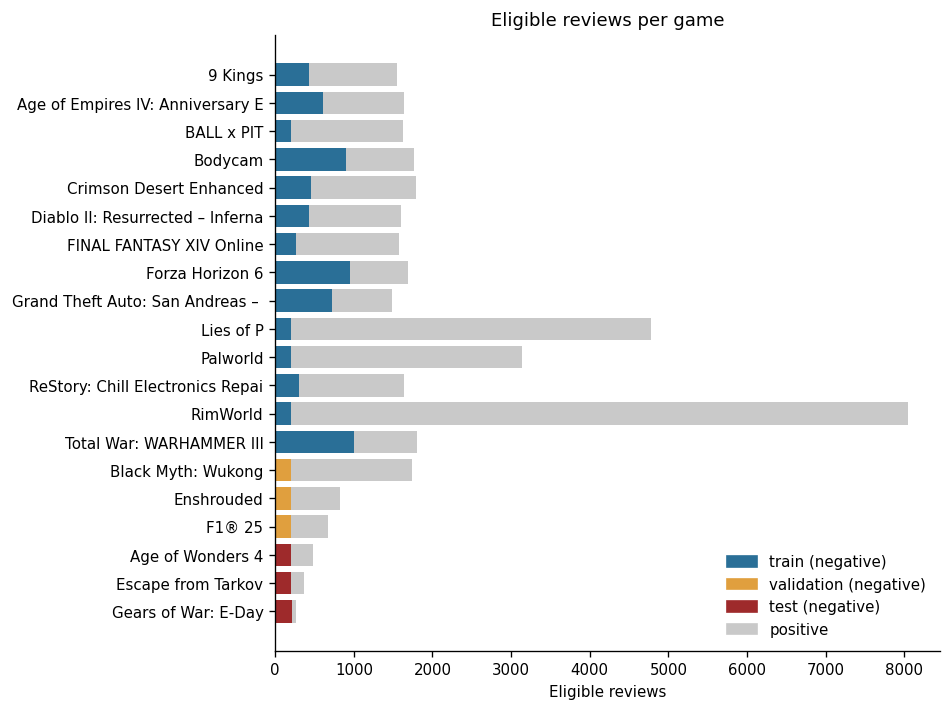

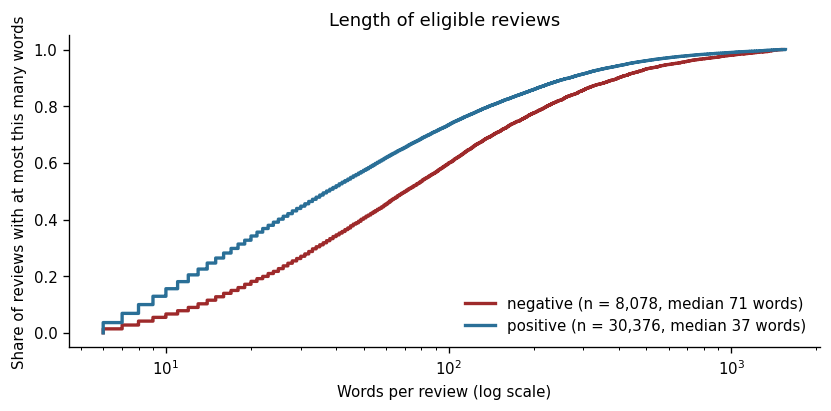

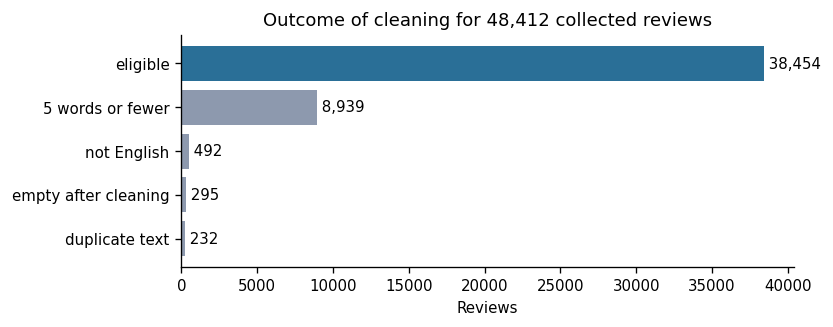

In [8]:
SPLIT_COLOURS = {"train": "#2a6f97", "validation": "#e09f3e", "test": "#9e2a2b"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

fig, ax = plt.subplots(figsize=(8, 6))
plot = summary.iloc[::-1].reset_index(drop=True)
y = np.arange(len(plot))
ax.barh(y, plot.eligible_neg, color=[SPLIT_COLOURS[s] for s in plot.split], label="negative")
ax.barh(y, plot.eligible_pos, left=plot.eligible_neg, color="#c9c9c9", label="positive")
ax.set_yticks(y, plot.name.str.slice(0, 32))
ax.set_xlabel("Eligible reviews")
ax.set_title("Eligible reviews per game")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SPLIT_COLOURS.values()] + [plt.Rectangle((0, 0), 1, 1, color="#c9c9c9")]
ax.legend(handles, [f"{s} (negative)" for s in SPLIT_COLOURS] + ["positive"], loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_eligible_per_game.png")
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
for voted_up, label, colour in [(False, "negative", "#9e2a2b"), (True, "positive", "#2a6f97")]:
    words = np.sort(eligible.loc[eligible.voted_up == voted_up, "n_words_clean"].to_numpy())
    ax.step(words, np.arange(1, len(words) + 1) / len(words), where="post", linewidth=2, color=colour,
            label=f"{label} (n = {len(words):,}, median {np.median(words):.0f} words)")
ax.set_xscale("log")
ax.set_xlabel("Words per review (log scale)")
ax.set_ylabel("Share of reviews with at most this many words")
ax.set_title("Length of eligible reviews")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_review_length.png")
plt.show()

fig, ax = plt.subplots(figsize=(7, 2.8))
counts = df.exclusion_reason.fillna("eligible").value_counts()
ax.barh(counts.index[::-1], counts.values[::-1], color=["#2a6f97" if i == "eligible" else "#8d99ae" for i in counts.index[::-1]])
for i, v in enumerate(counts.values[::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlabel("Reviews")
ax.set_title(f"Outcome of cleaning for {len(df):,} collected reviews")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_exclusions.png")
plt.show()

#### Save outputs

In [9]:
KEEP = ["review_key", "appid", "name", "split", "role", "voted_up", "hours_on_record", "early_access", "received_free",
        "votes_helpful", "votes_funny", "page", "position", "text_clean", "n_words_clean"]
AUDIT = ["lang_detected", "lang_steam", "english_word_share", "non_latin_share", "second_chance", "duplicate_text",
         "exclusion_reason", "eligible"]
df[KEEP + AUDIT].to_csv(OUT_DIR / "reviews_all_cleaned.csv", index=False)
df.loc[df.eligible, KEEP].to_csv(OUT_DIR / "reviews_eligible.csv", index=False)
summary.to_csv(OUT_DIR / "summary_by_game.csv", index=False)
config = {
    "input": str(RAW_DIR.relative_to(A3_DIR)), "min_words_exclusive": MIN_WORDS_EXCLUSIVE,
    "vocab_min_reviews": VOCAB_MIN_REVIEWS, "second_chance_share": SECOND_CHANCE_SHARE,
    "max_non_latin_share": MAX_NON_LATIN_SHARE, "steam_languages": [l.iso_code_639_1.name.lower() for l in STEAM_LANGUAGES],
    "n_collected": int(len(df)), "n_eligible": int(df.eligible.sum()),
    "exclusions": df.exclusion_reason.fillna("eligible").value_counts().to_dict(),
    "dropped_fields": ["posted_text", "text (raw text stays in data/raw)"],
}
(OUT_DIR / "clean_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)
print(json.dumps(config["exclusions"], indent=1))

Saved to /Users/kysen/MA3831/A3/outputs/04_clean_reviews
{
 "eligible": 38454,
 "5 words or fewer": 8939,
 "not English": 492,
 "empty after cleaning": 295,
 "duplicate text": 232
}


Key result: 38,454 of 48,412 collected reviews are eligible.

### 2.2 Sampling: labelled sample and embedding corpus

#### Configuration

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

IN_FILE = A3_DIR / "outputs" / "04_clean_reviews" / "reviews_eligible.csv"
OUT_DIR = A3_DIR / "outputs" / "05_sample_reviews"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 3831
PER_GAME = {False: 160, True: 40}           # voted_up -> reviews drawn per game
HUMAN_PER_GAME = {False: 32, True: 8}       # 20% of each stratum in train and validation games
W2V_MAX_PER_GAME = 5000
SPLIT_ORDER = {"train": 0, "validation": 1, "test": 2}

eligible = pd.read_csv(IN_FILE, dtype={"appid": str})
assert eligible.review_key.is_unique
game_order = (eligible[["split", "appid", "name"]].drop_duplicates()
              .assign(_o=lambda d: d.split.map(SPLIT_ORDER), _a=lambda d: d.appid.astype(int))
              .sort_values(["_o", "_a"]).drop(columns=["_o", "_a"]).reset_index(drop=True))
assert len(game_order) == 20 and game_order.split.value_counts().to_dict() == {"train": 14, "validation": 3, "test": 3}
print(f"{len(eligible):,} eligible reviews; available per game and recommendation:")
available = eligible.groupby(["split", "name", "voted_up"]).size().unstack("voted_up").rename(columns={False: "negative", True: "positive"})
assert (available.negative >= PER_GAME[False]).all() and (available.positive >= PER_GAME[True]).all()
available

38,454 eligible reviews; available per game and recommendation:


voted_up                                                       negative  \
split      name                                                           
test       Age of Wonders 4                                         201   
           Escape from Tarkov                                       204   
           Gears of War: E-Day                                      208   
train      9 Kings                                                  433   
           Age of Empires IV: Anniversary Edition                   603   
           BALL x PIT                                               203   
           Bodycam                                                  903   
           Crimson Desert Enhanced                                  451   
           Diablo II: Resurrected – Infernal Edition                425   
           FINAL FANTASY XIV Online                                 268   
           Forza Horizon 6                                          947   
           Grand Theft Auto: San Andreas – The Definitive ...       724   
           Lies of P                                                201   
           Palworld                                                 200   
           ReStory: Chill Electronics Repairs                       304   
           RimWorld                                                 199   
           Total War: WARHAMMER III                                1002   
validation Black Myth: Wukong                                       202   
           Enshrouded                                               200   
           F1® 25                                                   200   

voted_up                                                       positive  
split      name                                                          
test       Age of Wonders 4                                         274  
           Escape from Tarkov                                       163  
           Gears of War: E-Day                                       51  
train      9 Kings                                                 1117  
           Age of Empires IV: Anniversary Edition                  1031  
           BALL x PIT                                              1427  
           Bodycam                                                  868  
           Crimson Desert Enhanced                                 1343  
           Diablo II: Resurrected – Infernal Edition               1172  
           FINAL FANTASY XIV Online                                1302  
           Forza Horizon 6                                          746  
           Grand Theft Auto: San Andreas – The Definitive ...       761  
           Lies of P                                               4573  
           Palworld                                                2942  
           ReStory: Chill Electronics Repairs                      1331  
           RimWorld                                                7846  
           Total War: WARHAMMER III                                 796  
validation Black Myth: Wukong                                      1535  
           Enshrouded                                               621  
           F1® 25                                                   477

#### Labelled set and annotator assignment

In [2]:
rng = np.random.default_rng(SEED)
parts = []
for game in game_order.itertuples():
    for voted_up, n in PER_GAME.items():
        pool = eligible[(eligible.appid == game.appid) & (eligible.voted_up == voted_up)].sort_values("review_key")
        drawn = pool.iloc[np.sort(rng.choice(len(pool), size=n, replace=False))].copy()
        if game.split == "test":
            drawn["annotator"] = "human"
        else:
            human = rng.choice(n, size=HUMAN_PER_GAME[voted_up], replace=False)
            drawn["annotator"] = np.where(np.isin(np.arange(n), human), "human", "llm")
        parts.append(drawn)

labelled = pd.concat(parts, ignore_index=True)
labelled = labelled.iloc[rng.permutation(len(labelled))].reset_index(drop=True)   # shuffled presentation order
labelled.insert(0, "label_id", [f"R{i:04d}" for i in range(1, len(labelled) + 1)])

assert len(labelled) == 4000 and labelled.review_key.is_unique
assert labelled.split.value_counts().to_dict() == {"train": 2800, "validation": 600, "test": 600}
counts = labelled.groupby(["appid", "voted_up"]).size().unstack()
assert counts[False].eq(PER_GAME[False]).all() and counts[True].eq(PER_GAME[True]).all()
print(pd.crosstab([labelled.split, labelled.voted_up.map({False: "negative", True: "positive"})], labelled.annotator, margins=True))

annotator            human   llm   All
split      voted_up                   
test       negative    480     0   480
           positive    120     0   120
train      negative    448  1792  2240
           positive    112   448   560
validation negative     96   384   480
           positive     24    96   120
All                   1280  2720  4000


#### Word2Vec corpus (training games only)

In [3]:
w2v_parts = []
for game in game_order[game_order.split == "train"].itertuples():
    pool = eligible[eligible.appid == game.appid].sort_values("review_key")
    if len(pool) > W2V_MAX_PER_GAME:
        pool = pool.iloc[np.sort(rng.choice(len(pool), size=W2V_MAX_PER_GAME, replace=False))]
    w2v_parts.append(pool)
w2v = pd.concat(w2v_parts, ignore_index=True)

assert set(w2v.split) == {"train"}
assert not set(w2v.appid) & set(eligible.loc[eligible.split != "train", "appid"])
w2v["in_labelled_set"] = w2v.review_key.isin(labelled.review_key)
per_game = w2v.groupby("name").agg(reviews=("review_key", "size"), words=("n_words_clean", "sum"),
                                   labelled=("in_labelled_set", "sum")).sort_values("reviews")
print(f"Word2Vec corpus: {len(w2v):,} reviews, {w2v.n_words_clean.sum():,} words, "
      f"{int(w2v.in_labelled_set.sum()):,} of them in the labelled training set")
per_game

Word2Vec corpus: 31,073 reviews, 3,467,718 words, 2,733 of them in the labelled training set


,reviews,words,labelled
name,,,
Grand Theft Auto: San Andreas – The Definitive Edition,1485,144026,200
9 Kings,1550,132384,200
FINAL FANTASY XIV Online,1570,268471,200
Diablo II: Resurrected – Infernal Edition,1597,107126,200
BALL x PIT,1630,116734,200
Age of Empires IV: Anniversary Edition,1634,174677,200
ReStory: Chill Electronics Repairs,1635,126563,200
Forza Horizon 6,1693,252062,200
Bodycam,1771,172073,200


#### Save outputs

In [4]:
LABELLED_COLS = ["label_id", "review_key", "appid", "name", "split", "voted_up", "annotator", "hours_on_record",
                 "early_access", "received_free", "votes_helpful", "votes_funny", "n_words_clean", "text_clean"]
labelled[LABELLED_COLS].to_csv(OUT_DIR / "labelled_set.csv", index=False)
w2v[["review_key", "appid", "name", "in_labelled_set", "n_words_clean", "text_clean"]].to_csv(OUT_DIR / "word2vec_corpus.csv", index=False)
config = {
    "input": str(IN_FILE.relative_to(A3_DIR)), "seed": SEED,
    "per_game": {"negative": PER_GAME[False], "positive": PER_GAME[True]},
    "human_per_game_train_validation": {"negative": HUMAN_PER_GAME[False], "positive": HUMAN_PER_GAME[True]},
    "labelled": labelled.groupby(["split", "annotator"]).size().unstack(fill_value=0).to_dict(orient="index"),
    "word2vec": {"games": int(w2v.appid.nunique()), "max_per_game": W2V_MAX_PER_GAME, "reviews": int(len(w2v)),
                 "words": int(w2v.n_words_clean.sum()), "min_reviews_per_game": int(per_game.reviews.min())},
}
(OUT_DIR / "sample_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)
print(json.dumps(config, indent=1))

Saved to /Users/kysen/MA3831/A3/outputs/05_sample_reviews
{
 "input": "outputs/04_clean_reviews/reviews_eligible.csv",
 "seed": 3831,
 "per_game": {
  "negative": 160,
  "positive": 40
 },
 "human_per_game_train_validation": {
  "negative": 32,
  "positive": 8
 },
 "labelled": {
  "test": {
   "human": 600,
   "llm": 0
  },
  "train": {
   "human": 560,
   "llm": 2240
  },
  "validation": {
   "human": 120,
   "llm": 480
  }
 },
 "word2vec": {
  "games": 14,
  "max_per_game": 5000,
  "reviews": 31073,
  "words": 3467718,
  "min_reviews_per_game": 1485
 }
}


Key result: labelled sample of 4,000 reviews (2,800 / 600 / 600); embedding corpus of 31,073 reviews (about 3.5 million words) from the training games only.

### 2.3 LLM labels: checks

#### Configuration and loading

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

LAB_DIR = A3_DIR / "labelling"
BATCH_DIR, ANSWER_DIR = LAB_DIR / "llm" / "batches", LAB_DIR / "llm" / "answers"
OUT_DIR = A3_DIR / "outputs" / "07_check_llm_labels"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {1: "Technical and performance", 2: "Gameplay and design", 3: "Content and updates",
               4: "Community and cheating", 5: "Pricing and monetisation", 6: "Developer conduct and operations",
               7: "Other complaint"}
LABEL_COLS = [f"l{k}" for k in LABEL_NAMES]

manifest = pd.read_csv(LAB_DIR / "manifest.csv", dtype={"appid": str})
labelled = pd.read_csv(A3_DIR / "outputs" / "05_sample_reviews" / "labelled_set.csv", dtype={"appid": str})
batch_files = sorted(BATCH_DIR.glob("batch_*.txt"))
answer_files = sorted(ANSWER_DIR.glob("batch_*.csv"))
print(f"{len(batch_files)} batch files, {len(answer_files)} answer files")
assert [p.stem for p in batch_files] == [p.stem for p in answer_files]

38 batch files, 38 answer files


#### Check IDs and label format

In [2]:
VALID = re.compile(r"^(0|[1-7]( [1-7])*)$")
problems, answers = [], []
for batch_path, answer_path in zip(batch_files, answer_files):
    expected = re.findall(r"^\[(R\d{4})\]$", batch_path.read_text(encoding="utf-8"), flags=re.M)
    answer = pd.read_csv(answer_path, dtype=str, keep_default_na=False)
    if list(answer.columns) != ["label_id", "labels"]:
        problems.append((answer_path.name, f"columns {list(answer.columns)}"))
        continue
    if answer.label_id.tolist() != expected:
        problems.append((answer_path.name, "IDs differ from the batch file (missing, extra or reordered)"))
    for row in answer.itertuples():
        numbers = row.labels.split()
        if not VALID.match(row.labels) or numbers != sorted(set(numbers), key=int):
            problems.append((answer_path.name, f"{row.label_id}: invalid labels {row.labels!r}"))
    answers.append(answer.assign(batch=int(batch_path.stem.split("_")[1])))

llm = pd.concat(answers, ignore_index=True)
expected_ids = set(manifest.loc[manifest.annotator == "llm", "label_id"])
print("Problems found:", len(problems))
for name, message in problems[:20]:
    print(" ", name, message)
assert not problems
assert llm.label_id.is_unique and set(llm.label_id) == expected_ids
assert (llm.batch == llm.label_id.map(manifest.set_index("label_id").batch)).all()
print(f"All {len(llm):,} LLM labels pass the ID and format checks")

Problems found: 0
All 2,720 LLM labels pass the ID and format checks


#### One column per complaint type

In [3]:
for k, col in zip(LABEL_NAMES, LABEL_COLS):
    llm[col] = llm.labels.str.split().map(lambda nums, k=k: int(str(k) in nums))
llm["n_labels"] = llm[LABEL_COLS].sum(axis=1)
llm["no_complaint"] = (llm.labels == "0").astype(int)
assert (llm.no_complaint == (llm.n_labels == 0)).all()
llm = llm.merge(labelled[["label_id", "review_key", "appid", "name", "split", "voted_up", "n_words_clean", "text_clean"]],
                on="label_id", how="left", validate="one_to_one")

rec = llm.voted_up.map({False: "negative", True: "positive"})
prevalence = pd.concat({
    "all": llm[LABEL_COLS + ["no_complaint"]].mean(),
    "negative reviews": llm.loc[rec == "negative", LABEL_COLS + ["no_complaint"]].mean(),
    "positive reviews": llm.loc[rec == "positive", LABEL_COLS + ["no_complaint"]].mean(),
    "train": llm.loc[llm.split == "train", LABEL_COLS + ["no_complaint"]].mean(),
    "validation": llm.loc[llm.split == "validation", LABEL_COLS + ["no_complaint"]].mean(),
}, axis=1)
prevalence.index = [f"{c} {LABEL_NAMES[int(c[1])]}" if c.startswith("l") else "0 No complaint" for c in prevalence.index]
counts = llm[LABEL_COLS + ["no_complaint"]].sum().rename("count")
counts.index = prevalence.index
print("Share of reviews carrying each label:")
prevalence.round(3).assign(count=counts)

Share of reviews carrying each label:


,all,negative reviews,positive reviews,train,validation,count
l1 Technical and performance,0.221,0.254,0.090,0.192,0.360,602
l2 Gameplay and design,0.423,0.487,0.169,0.406,0.502,1151
l3 Content and updates,0.224,0.258,0.090,0.231,0.192,610
l4 Community and cheating,0.027,0.033,0.006,0.031,0.010,74
l5 Pricing and monetisation,0.130,0.153,0.037,0.146,0.054,354
l6 Developer conduct and operations,0.230,0.284,0.015,0.255,0.115,626
l7 Other complaint,0.035,0.040,0.018,0.039,0.019,96
0 No complaint,0.145,0.011,0.680,0.146,0.140,395


In [4]:
print("Labels per review:")
print(llm.n_labels.value_counts().sort_index().rename_axis("labels").to_string())
print(f"Mean labels per review: {llm.n_labels.mean():.2f} (all), {llm.loc[llm.n_labels > 0, 'n_labels'].mean():.2f} (reviews with a complaint)")
print(f"Reviews with 4 or more labels (to be re-read): {(llm.n_labels >= 4).sum()}")
print("\nMost common label combinations:")
print(llm.labels.value_counts().head(12).to_string())
print("\nLabel 7 together with another label (the codebook says 7 only when nothing else fits):", int(((llm.l7 == 1) & (llm.n_labels > 1)).sum()))

co = llm[LABEL_COLS].T.dot(llm[LABEL_COLS])
co.index = co.columns = [c[1] for c in LABEL_COLS]
print("\nCo-occurrence counts (diagonal = label count):")
co

Labels per review:
labels
0     395
1    1481
2     575
3     204
4      55
5      10
Mean labels per review: 1.29 (all), 1.51 (reviews with a complaint)
Reviews with 4 or more labels (to be re-read): 65

Most common label combinations:
labels
2        593
0        395
6        322
1        246
2 3      192
3        114
7         96
5         96
1 2       76
1 6       67
1 2 3     65
3 5       52

Label 7 together with another label (the codebook says 7 only when nothing else fits): 0

Co-occurrence counts (diagonal = label count):


,1,2,3,4,5,6,7
1,602,207,143,19,66,145,0
2,207,1151,351,26,126,126,0
3,143,351,610,26,139,103,0
4,19,26,26,74,15,35,0
5,66,126,139,15,354,90,0
6,145,126,103,35,90,626,0
7,0,0,0,0,0,0,96


#### Figure and outputs

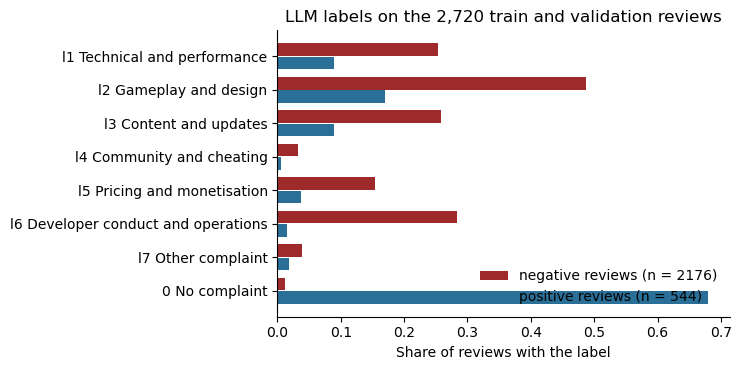

Saved to /Users/kysen/MA3831/A3/outputs/07_check_llm_labels


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
order = list(prevalence.index)
y = np.arange(len(order))
ax.barh(y - 0.2, prevalence.loc[order, "negative reviews"], height=0.38, color="#9e2a2b", label="negative reviews (n = %d)" % (rec == "negative").sum())
ax.barh(y + 0.2, prevalence.loc[order, "positive reviews"], height=0.38, color="#2a6f97", label="positive reviews (n = %d)" % (rec == "positive").sum())
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.set_xlabel("Share of reviews with the label")
ax.set_title("LLM labels on the 2,720 train and validation reviews")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_llm_label_prevalence.png", dpi=150)
plt.show()

llm[["label_id", "review_key", "appid", "split", "batch", "labels"] + LABEL_COLS + ["n_labels"]].to_csv(OUT_DIR / "llm_labels.csv", index=False)
llm.loc[llm.n_labels >= 4, ["label_id", "labels", "text_clean"]].to_csv(OUT_DIR / "reread_4plus_labels.csv", index=False)
summary = {"n": int(len(llm)), "prevalence_all": prevalence["all"].round(4).to_dict(),
           "mean_labels": round(float(llm.n_labels.mean()), 3), "n_4plus": int((llm.n_labels >= 4).sum())}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)

### 2.4 Hand labels: checks and merge

#### Configuration and loading

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

LAB_DIR = A3_DIR / "labelling"
HUMAN_FILE = LAB_DIR / "human" / "human_labels_completed.xlsx"
OUT_DIR = A3_DIR / "outputs" / "08_merge_labels"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {1: "Technical and performance", 2: "Gameplay and design", 3: "Content and updates",
               4: "Community and cheating", 5: "Pricing and monetisation", 6: "Developer conduct and operations",
               7: "Other complaint"}
LABEL_COLS = [f"l{k}" for k in LABEL_NAMES]

manifest = pd.read_csv(LAB_DIR / "manifest.csv", dtype={"appid": str})
labelled = pd.read_csv(A3_DIR / "outputs" / "05_sample_reviews" / "labelled_set.csv", dtype={"appid": str})
llm = pd.read_csv(A3_DIR / "outputs" / "07_check_llm_labels" / "llm_labels.csv", dtype={"appid": str, "labels": str})
sheet = pd.read_excel(HUMAN_FILE, sheet_name="Labels", dtype=str, keep_default_na=False)
print(f"Hand-label sheet: {len(sheet):,} rows, columns {list(sheet.columns)}")

Hand-label sheet: 1,280 rows, columns ['ID', 'Review', 'Labels']


#### Check the hand labels

In [2]:
expected = manifest.dropna(subset=["human_sheet_row"]).sort_values("human_sheet_row")
assert list(sheet.columns[:3]) == ["ID", "Review", "Labels"]
assert sheet.ID.tolist() == expected.label_id.tolist(), "IDs or row order differ from notebook 06"

raw = sheet.Labels.str.strip()
labels = raw.str.replace(r"[\s,，;；、]+", " ", regex=True).str.strip()
numbers = labels.str.split()
problems = sheet.loc[(raw == "")
                     | ~labels.str.fullmatch(r"[0-7]( [0-7])*")
                     | numbers.map(lambda n: len(set(n)) != len(n) or ("0" in n and len(n) > 1)), ["ID", "Labels"]]
print("Empty or invalid label cells:", len(problems))
print(problems.to_string() if len(problems) else "")
assert problems.empty

human = pd.DataFrame({"label_id": sheet.ID,
                      "labels": numbers.map(lambda n: " ".join(sorted(n, key=int)))})
print(f"All {len(human):,} hand labels pass the ID and format checks")

Empty or invalid label cells: 0

All 1,280 hand labels pass the ID and format checks


In [3]:
text = labelled.set_index("label_id").text_clean
changed = sheet.loc[sheet.Review != sheet.ID.map(text), "ID"].tolist()
print("Reviews whose text cell differs from the cleaned text:", changed)

Reviews whose text cell differs from the cleaned text: ['R1041']


#### Merge with the LLM labels

In [4]:
def to_columns(frame):
    for k, col in zip(LABEL_NAMES, LABEL_COLS):
        frame[col] = frame.labels.str.split().map(lambda nums, k=k: int(str(k) in nums))
    frame["n_labels"] = frame[LABEL_COLS].sum(axis=1)
    return frame

all_labels = pd.concat([to_columns(human).assign(annotator="human"),
                        llm[["label_id", "labels"]].copy().pipe(to_columns).assign(annotator="llm")], ignore_index=True)
all_labels = all_labels.merge(labelled[["label_id", "review_key", "appid", "name", "split", "voted_up", "n_words_clean", "text_clean", "annotator"]],
                              on="label_id", how="left", validate="one_to_one", suffixes=("", "_planned"))
assert len(all_labels) == 4000 and all_labels.label_id.is_unique
assert (all_labels.annotator == all_labels.annotator_planned).all()
all_labels = all_labels.drop(columns="annotator_planned")
assert (all_labels.labels.eq("0") == all_labels.n_labels.eq(0)).all()

print(all_labels.groupby(["split", "annotator"]).size().unstack(fill_value=0))

annotator   human   llm
split                  
test          600     0
train         560  2240
validation    120   480


#### Label frequencies

In [5]:
def share(mask):
    part = all_labels.loc[mask]
    return pd.Series({**{c: part[c].mean() for c in LABEL_COLS}, "no complaint": part.n_labels.eq(0).mean(),
                      "mean labels": part.n_labels.mean(), "n": len(part)})

trval = all_labels.split.ne("test")
freq = pd.DataFrame({
    "test (human)": share(all_labels.split.eq("test")),
    "train+val human": share(trval & all_labels.annotator.eq("human")),
    "train+val LLM": share(trval & all_labels.annotator.eq("llm")),
    "train (all)": share(all_labels.split.eq("train")),
    "validation (all)": share(all_labels.split.eq("validation")),
})
freq.index = [f"{c} {LABEL_NAMES[int(c[1])]}" if c in LABEL_COLS else c for c in freq.index]
counts = all_labels.groupby("split")[LABEL_COLS].sum().T
counts.index = freq.index[:len(LABEL_COLS)]
print("Share of reviews with each label:")
display(freq.round(3))
print("Number of reviews with each label, by split:")
counts

Share of reviews with each label:


,test (human),train+val human,train+val LLM,train (all),validation (all)
l1 Technical and performance,0.353,0.257,0.221,0.199,0.365
l2 Gameplay and design,0.328,0.515,0.423,0.425,0.518
l3 Content and updates,0.323,0.303,0.224,0.246,0.212
l4 Community and cheating,0.093,0.057,0.027,0.038,0.012
l5 Pricing and monetisation,0.258,0.168,0.130,0.156,0.053
l6 Developer conduct and operations,0.445,0.284,0.230,0.265,0.127
l7 Other complaint,0.058,0.026,0.035,0.035,0.027
no complaint,0.102,0.135,0.145,0.144,0.138
mean labels,1.860,1.610,1.292,1.364,1.313
n,600.000,680.000,2720.000,2800.000,600.000


Number of reviews with each label, by split:


split,test,train,validation
l1 Technical and performance,212,558,219
l2 Gameplay and design,197,1190,311
l3 Content and updates,194,689,127
l4 Community and cheating,56,106,7
l5 Pricing and monetisation,155,436,32
l6 Developer conduct and operations,267,743,76
l7 Other complaint,35,98,16


In [6]:
by_rec = all_labels.assign(rec=all_labels.voted_up.map({False: "negative", True: "positive"})).groupby(["annotator", "rec"])
print("Share of reviews with at least one complaint, by annotator and recommendation (train+val and test):")
print(by_rec.n_labels.apply(lambda s: s.gt(0).mean()).unstack().round(3))
print("\nLabel 7 together with another label:", int(((all_labels.l7 == 1) & (all_labels.n_labels > 1)).sum()))
print("Hand labels with 4 or more numbers:", int((all_labels.annotator.eq("human") & all_labels.n_labels.ge(4)).sum()))

Share of reviews with at least one complaint, by annotator and recommendation (train+val and test):
rec        negative  positive
annotator                    
human         0.994     0.426
llm           0.989     0.320

Label 7 together with another label: 0
Hand labels with 4 or more numbers: 104


#### Figure and outputs

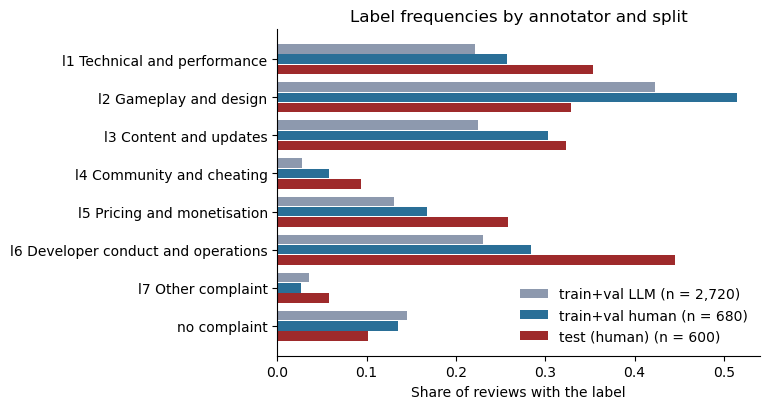

Saved to /Users/kysen/MA3831/A3/outputs/08_merge_labels


In [7]:
names = list(freq.index[:len(LABEL_COLS)]) + ["no complaint"]
series = [("train+val LLM", "#8d99ae"), ("train+val human", "#2a6f97"), ("test (human)", "#9e2a2b")]
fig, ax = plt.subplots(figsize=(7.8, 4.2))
y = np.arange(len(names))
for i, (col, colour) in enumerate(series):
    n = int(freq.loc["n", col])
    ax.barh(y + (i - 1) * 0.27, freq.loc[names, col], height=0.25, color=colour, label=f"{col} (n = {n:,})")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel("Share of reviews with the label")
ax.set_title("Label frequencies by annotator and split")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_label_frequencies.png", dpi=150)
plt.show()

cols = ["label_id", "review_key", "appid", "name", "split", "annotator", "voted_up", "labels"] + LABEL_COLS + ["n_labels", "n_words_clean", "text_clean"]
all_labels.sort_values("label_id")[cols].to_csv(OUT_DIR / "all_labels.csv", index=False)
summary = {"n": int(len(all_labels)),
           "by_split_annotator": {f"{s}/{a}": int(n) for (s, a), n in all_labels.groupby(["split", "annotator"]).size().items()},
           "test_label_counts": {c: int(all_labels.loc[all_labels.split.eq("test"), c].sum()) for c in LABEL_COLS},
           "text_cells_differing": changed}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)

Key result: 4,000 labelled reviews; all 600 test reviews are hand-labelled.

### 2.5 Word2Vec embeddings

#### Configuration and tokenisation

In [1]:
import json
import re
import time
import zlib
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from gensim.models.callbacks import CallbackAny2Vec
from sklearn.decomposition import PCA

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"
OUT_DIR = A3_DIR / "outputs" / "10_word2vec"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

SEED = 3831
W2V_PARAMS = dict(vector_size=100, window=10, min_count=5, sg=1, negative=5, epochs=10, workers=1, seed=SEED)
TOKEN_PATTERN = r"[a-z0-9]+(?:'[a-z]+)?"
TOKEN = re.compile(TOKEN_PATTERN)

def tokenize(text):
    """Tokeniser shared by Word2Vec and the neural classifiers."""
    text = re.sub(r"♥+", " swearword ", text.lower()).replace("’", "'")
    return TOKEN.findall(text)

def stable_hash(text):
    """Process-independent hash, so the initial vectors do not depend on PYTHONHASHSEED."""
    return zlib.crc32(text.encode("utf-8"))

corpus = pd.read_csv(A3_DIR / "outputs" / "05_sample_reviews" / "word2vec_corpus.csv", dtype={"appid": str})
labelled = pd.read_csv(A3_DIR / "outputs" / "08_merge_labels" / "all_labels.csv", dtype={"appid": str, "labels": str})
assert not set(corpus.appid) & set(labelled.loc[labelled.split != "train", "appid"]), "corpus must contain training games only"

print("Example:", tokenize("It's NOT worth $60. ♥♥♥♥ this, the game crashed 3 times!"))
sentences = corpus.text_clean.map(tokenize).tolist()
counts = Counter(tok for sent in sentences for tok in sent)
print(f"Corpus: {len(sentences):,} reviews from {corpus.appid.nunique()} games, {sum(counts.values()):,} tokens, "
      f"{len(counts):,} distinct tokens, {sum(c >= W2V_PARAMS['min_count'] for c in counts.values()):,} seen at least {W2V_PARAMS['min_count']} times")

Example: ["it's", 'not', 'worth', '60', 'swearword', 'this', 'the', 'game', 'crashed', '3', 'times']


Corpus: 31,073 reviews from 14 games, 3,501,271 tokens, 45,009 distinct tokens, 15,417 seen at least 5 times


#### Train Word2Vec

In [2]:
class EpochLogger(CallbackAny2Vec):
    def __init__(self):
        self.epoch, self.start = 0, time.time()
    def on_epoch_end(self, model):
        self.epoch += 1
        print(f"  epoch {self.epoch:2d} done, {time.time() - self.start:5.0f} s")

start = time.time()
w2v = Word2Vec(sentences=sentences, hashfxn=stable_hash, callbacks=[EpochLogger()], **W2V_PARAMS)
train_seconds = time.time() - start
wv = w2v.wv
print(f"Trained in {train_seconds:.0f} s; vocabulary {len(wv):,} words x {wv.vector_size} dimensions")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


  epoch  1 done,    18 s


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


... (46 outputs left out)

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


  epoch 10 done,   180 s
Trained in 180 s; vocabulary 15,417 words x 100 dimensions


#### Vocabulary coverage of the labelled reviews

In [3]:
labelled["tokens"] = labelled.text_clean.map(tokenize)
rows = {}
for name, part in labelled.groupby("split"):
    toks = [t for sent in part.tokens for t in sent]
    types = set(toks)
    rows[name] = {"reviews": len(part), "tokens": len(toks),
                  "OOV token share": np.mean([t not in wv.key_to_index for t in toks]),
                  "OOV type share": np.mean([t not in wv.key_to_index for t in types]),
                  "median tokens per review": part.tokens.str.len().median(),
                  "95th percentile tokens": part.tokens.str.len().quantile(0.95)}
coverage = pd.DataFrame(rows).T.loc[["train", "validation", "test"]]
display(coverage.round(4))

oov_test = Counter(t for sent in labelled.loc[labelled.split == "test", "tokens"] for t in sent if t not in wv.key_to_index)
print("Most frequent OOV tokens in the test reviews:", ", ".join(f"{t} ({c})" for t, c in oov_test.most_common(25)))

,reviews,tokens,OOV token share,OOV type share,median tokens per review,95th percentile tokens
train,2800.0,436603.0,0.0126,0.2873,67.0,594.10
validation,600.0,120559.0,0.0188,0.1973,90.0,844.85
test,600.0,105980.0,0.0270,0.2123,80.5,701.10


Most frequent OOV tokens in the test reviews: dom (124), bsg (84), aow (53), nikita (36), locust (32), pantheon (30), coalition (29), aow4 (27), battlestate (26), eod (23), gnasher (22), gow (15), lucas (14), scav (14), aow3 (14), planetfall (14), lgbtq (13), cog (12), rulers (12), executions (11), carter (11), reyes (11), pmc (11), tai (10), emergence (10)


Key result: vocabulary of 15,417 words; out-of-vocabulary token share 1.26% (train), 1.88% (validation), 2.70% (test).

#### Sanity check: nearest neighbours

In [4]:
PROBES = {
    "Technical and performance": ["crash", "stutter", "fps", "bug", "optimization"],
    "Gameplay and design": ["grind", "controls", "difficulty", "repetitive"],
    "Content and updates": ["content", "story", "update"],
    "Community and cheating": ["cheaters", "hackers", "toxic"],
    "Pricing and monetisation": ["price", "dlc", "microtransactions", "refund"],
    "Developer conduct and operations": ["devs", "servers", "launcher", "denuvo", "support"],
}
neighbours = pd.DataFrame([{"label": label, "word": w, "count": counts[w],
                            "nearest neighbours": ", ".join(n for n, _ in wv.most_similar(w, topn=8))}
                           for label, words in PROBES.items() for w in words if w in wv.key_to_index])
missing = [w for words in PROBES.values() for w in words if w not in wv.key_to_index]
print("Probe words not in the vocabulary:", missing or "none")
pd.set_option("display.max_colwidth", 200)
neighbours

Probe words not in the vocabulary: none


,label,word,count,nearest neighbours
0,Technical and performance,crash,368,"crashed, landed, crashes, relaunch, reopen, startup, corrupting, wreck"
1,Technical and performance,stutter,45,"frametime, hitches, shader, stuttering, framerate, stutters, frame, crashes"
2,Technical and performance,fps,856,"ultra, 1440p, 90fps, 70fps, frame, 50fps, framerate, 9070xt"
3,Technical and performance,bug,587,"gamebreaking, fixes, bugs, issue, adressed, fixed, patch, crashes"
4,Technical and performance,optimization,350,"performance, optimisation, perfomance, graphical, graphics, 3060ti, technical, 9070xt"
5,Gameplay and design,grind,987,"leaderboards, necessary, ranks, grinding, grindy, progress, average, insanity"
6,Gameplay and design,controls,1325,"clunky, ui, camera, movement, keybinds, controller, mouse, menus"
7,Gameplay and design,difficulty,1679,"difficulties, challenge, levels, hardest, spike, easy, beginner, normal"
8,Gameplay and design,repetitive,557,"boring, stale, repetetive, tedious, grindy, monotonous, tiring, unrewarding"
9,Content and updates,content,3696,"updates, dlcs, dlc, dlc's, downloadable, reworks, overpriced, pricy"


#### Two-dimensional view of complaint words

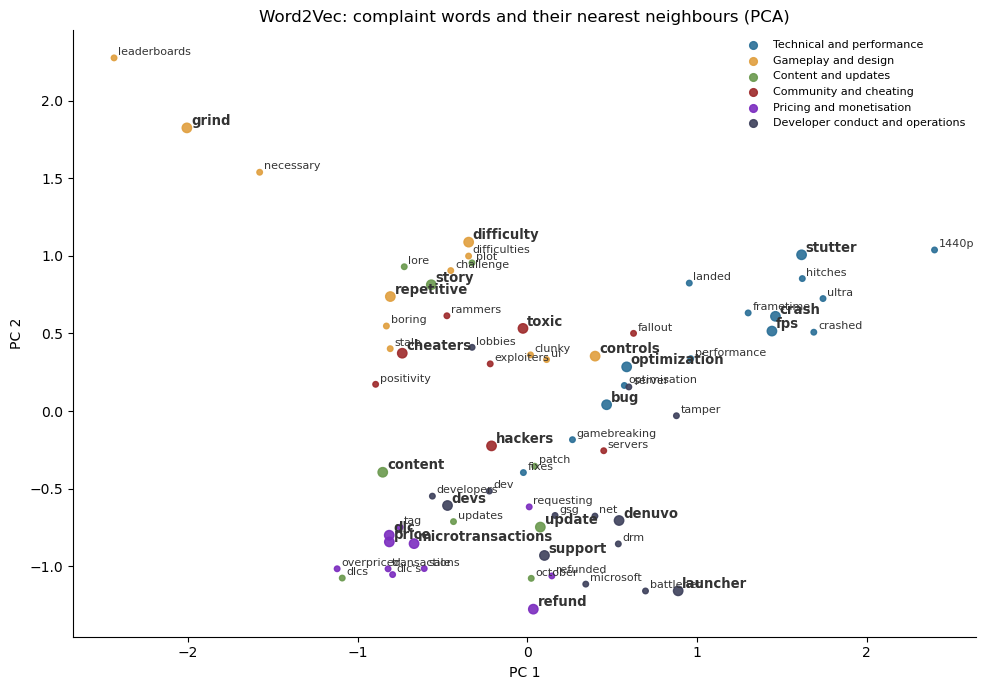

In [5]:
points = []
for label, words in PROBES.items():
    for w in words:
        if w in wv.key_to_index:
            points.append((w, label, True))
            points += [(n, label, False) for n, _ in wv.most_similar(w, topn=2)]
plot_df = pd.DataFrame(points, columns=["word", "label", "probe"]).drop_duplicates("word")
xy = PCA(n_components=2, random_state=SEED).fit_transform(wv[plot_df.word.tolist()])
plot_df[["x", "y"]] = xy

COLOURS = dict(zip(PROBES, ["#2a6f97", "#e09f3e", "#6a994e", "#9e2a2b", "#7b2cbf", "#3d405b"]))
fig, ax = plt.subplots(figsize=(10, 7))
for label, part in plot_df.groupby("label", sort=False):
    ax.scatter(part.x, part.y, s=np.where(part.probe, 46, 16), color=COLOURS[label], label=label, alpha=0.9)
    for r in part.itertuples():
        ax.annotate(r.word, (r.x, r.y), xytext=(3, 2), textcoords="offset points",
                    fontsize=9.5 if r.probe else 8, fontweight="bold" if r.probe else "normal", color="0.2")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("Word2Vec: complaint words and their nearest neighbours (PCA)")
ax.legend(frameon=False, fontsize=8, loc="best")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_word2vec_pca.png", dpi=150)
plt.show()

#### Save

In [6]:
w2v.save(str(OUT_DIR / "word2vec.model"))
wv.save(str(OUT_DIR / "word2vec.kv"))
neighbours.to_csv(OUT_DIR / "nearest_neighbours.csv", index=False)
coverage.to_csv(OUT_DIR / "vocabulary_coverage.csv")
config = {"seed": SEED, "word2vec": {k: v for k, v in W2V_PARAMS.items()}, "hash_function": "zlib.crc32",
          "token_pattern": TOKEN_PATTERN, "swear_token": "swearword", "lemmatisation": False, "stop_words_removed": False,
          "corpus_reviews": len(sentences), "corpus_tokens": int(sum(counts.values())), "vocabulary_size": len(wv),
          "train_seconds": round(train_seconds, 1),
          "oov_token_share": coverage["OOV token share"].round(4).to_dict()}
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)

Saved to /Users/kysen/MA3831/A3/outputs/10_word2vec


## 3. Machine learning

### 3.1 Baseline: TF-IDF + logistic regression

#### Configuration and loading

In [1]:
import json
import re
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.multiclass import OneVsRestClassifier

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"
OUT_DIR = A3_DIR / "outputs" / "09_tfidf_lr_baseline"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

SEED = 3831
LABEL_NAMES = {1: "Technical and performance", 2: "Gameplay and design", 3: "Content and updates",
               4: "Community and cheating", 5: "Pricing and monetisation", 6: "Developer conduct and operations",
               7: "Other complaint"}
LABEL_COLS = [f"l{k}" for k in LABEL_NAMES]

TFIDF_PARAMS = dict(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)   # fixed, not tuned
C_GRID = [0.1, 1, 10, 100]   # 100 added after 10 was best at the edge of the first grid
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)

data = pd.read_csv(A3_DIR / "outputs" / "08_merge_labels" / "all_labels.csv", dtype={"appid": str, "labels": str})
print(data.groupby(["split", "annotator"]).size().unstack(fill_value=0))

annotator   human   llm
split                  
test          600     0
train         560  2240
validation    120   480


#### Text preprocessing

In [2]:
KEEP = {"no", "not", "nor", "never", "nothing", "none", "nobody", "nowhere", "cannot", "without", "but",
        "against", "less", "least", "too", "very", "few", "more", "most", "only", "again", "off", "down", "up"}
STOP_WORDS = frozenset(ENGLISH_STOP_WORDS - KEEP)
TOKEN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
POS_MAP = {"J": "a", "V": "v", "N": "n", "R": "r"}
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r"♥+", " swearword ", text.lower())
    tokens = TOKEN.findall(text.replace("’", "'"))
    lemmas = [lemmatizer.lemmatize(tok, POS_MAP.get(tag[0], "n")) for tok, tag in nltk.pos_tag(tokens)]
    return [w for w in lemmas if w not in STOP_WORDS and len(w) > 1]

example = "The game crashes constantly and it's NOT worth $60. ♥♥♥♥ this, I stopped playing."
print(example, "\n→", preprocess(example))

start = time.time()
data["tokens"] = data.text_clean.map(preprocess)
data["text_prep"] = data.tokens.str.join(" ")
print(f"Preprocessed {len(data):,} reviews in {time.time() - start:.0f} s; "
      f"median {data.tokens.str.len().median():.0f} tokens per review (cleaned text: {data.n_words_clean.median():.0f} words)")

The game crashes constantly and it's NOT worth $60. ♥♥♥♥ this, I stopped playing. 
→ ['game', 'crash', 'constantly', "it's", 'not', 'worth', '60', 'swearword', 'stop', 'play']


Preprocessed 4,000 reviews in 8 s; median 38 tokens per review (cleaned text: 72 words)


#### TF-IDF features (fitted on the training reviews only)

In [3]:
split = {s: data[data.split == s].reset_index(drop=True) for s in ["train", "validation", "test"]}
vectorizer = TfidfVectorizer(**TFIDF_PARAMS, token_pattern=r"\S+", lowercase=False)
X_train = vectorizer.fit_transform(split["train"].text_prep)
X_val = vectorizer.transform(split["validation"].text_prep)
Y_train, Y_val = split["train"][LABEL_COLS].to_numpy(), split["validation"][LABEL_COLS].to_numpy()
print(f"Vocabulary: {len(vectorizer.vocabulary_):,} unigrams and bigrams; X_train {X_train.shape}, X_val {X_val.shape}")
print("Positive training examples per label:", dict(zip(LABEL_COLS, Y_train.sum(axis=0).tolist())))
print("Positive validation examples per label:", dict(zip(LABEL_COLS, Y_val.sum(axis=0).tolist())))

Vocabulary: 29,071 unigrams and bigrams; X_train (2800, 29071), X_val (600, 29071)
Positive training examples per label: {'l1': 558, 'l2': 1190, 'l3': 689, 'l4': 106, 'l5': 436, 'l6': 743, 'l7': 98}
Positive validation examples per label: {'l1': 219, 'l2': 311, 'l3': 127, 'l4': 7, 'l5': 32, 'l6': 76, 'l7': 16}


#### Tune C and the shared threshold on the validation set

In [4]:
def make_model(C):
    return OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", solver="liblinear",
                                                  max_iter=1000, random_state=SEED))

def micro_f1_by_threshold(Y, P):
    return np.array([f1_score(Y, (P >= t).astype(int), average="micro", zero_division=0) for t in THRESHOLD_GRID])

curves, val_probs, models = {}, {}, {}
for C in C_GRID:
    models[C] = make_model(C).fit(X_train, Y_train)
    val_probs[C] = models[C].predict_proba(X_val)
    curves[C] = micro_f1_by_threshold(Y_val, val_probs[C])

tuning = pd.DataFrame({"C": C_GRID,
                       "best threshold": [THRESHOLD_GRID[curves[C].argmax()] for C in C_GRID],
                       "validation micro-F1": [curves[C].max() for C in C_GRID],
                       "micro-F1 at 0.5": [curves[C][np.where(THRESHOLD_GRID == 0.5)[0][0]] for C in C_GRID]})
best_C = float(tuning.loc[tuning["validation micro-F1"].idxmax(), "C"])
best_t = float(tuning.loc[tuning["validation micro-F1"].idxmax(), "best threshold"])
print(f"Chosen: C = {best_C}, shared threshold = {best_t}")
tuning.round(4)

Chosen: C = 100.0, shared threshold = 0.37


,C,best threshold,validation micro-F1,micro-F1 at 0.5
0,0.1,0.51,0.6596,0.6582
1,1.0,0.46,0.6820,0.6723
2,10.0,0.44,0.6961,0.6923
3,100.0,0.37,0.6989,0.6880


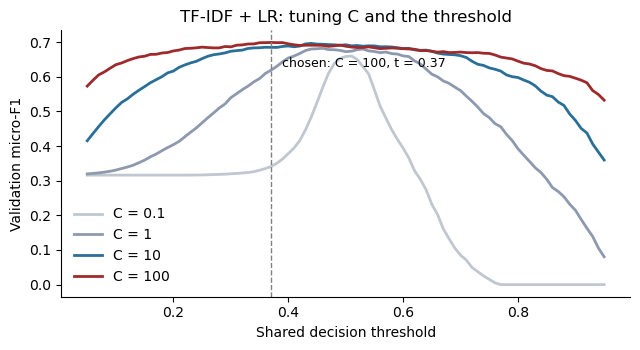

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for C, colour in zip(C_GRID, ["#c0c7d1", "#8d99ae", "#2a6f97", "#9e2a2b"]):
    ax.plot(THRESHOLD_GRID, curves[C], color=colour, lw=2, label=f"C = {C:g}")
ax.axvline(best_t, color="0.5", lw=1, ls="--")
ax.annotate(f"chosen: C = {best_C:g}, t = {best_t:.2f}", (best_t, curves[best_C].max()),
            xytext=(8, -18), textcoords="offset points", fontsize=9)
ax.set_xlabel("Shared decision threshold")
ax.set_ylabel("Validation micro-F1")
ax.set_title("TF-IDF + LR: tuning C and the threshold")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_tuning_curves.png", dpi=150)
plt.show()

#### Validation results of the chosen model

In [6]:
model, P_val = models[best_C], val_probs[best_C]
pred_val = (P_val >= best_t).astype(int)

def report(Y, pred):
    rows = {f"{c} {LABEL_NAMES[int(c[1])]}": {"support": int(Y[:, i].sum()),
                                               "precision": precision_score(Y[:, i], pred[:, i], zero_division=0),
                                               "recall": recall_score(Y[:, i], pred[:, i], zero_division=0),
                                               "F1": f1_score(Y[:, i], pred[:, i], zero_division=0)}
            for i, c in enumerate(LABEL_COLS)}
    none_true, none_pred = Y.sum(axis=1) == 0, pred.sum(axis=1) == 0
    rows["0 No complaint (none predicted)"] = {"support": int(none_true.sum()),
                                               "precision": precision_score(none_true, none_pred, zero_division=0),
                                               "recall": recall_score(none_true, none_pred, zero_division=0),
                                               "F1": f1_score(none_true, none_pred, zero_division=0)}
    table = pd.DataFrame(rows).T
    overall = {"micro-F1": f1_score(Y, pred, average="micro", zero_division=0),
               "macro-F1": f1_score(Y, pred, average="macro", zero_division=0),
               "samples-F1": f1_score(Y, pred, average="samples", zero_division=0),
               "exact match": float((Y == pred).all(axis=1).mean())}
    return table, overall

val_table, val_overall = report(Y_val, pred_val)
print({k: round(v, 4) for k, v in val_overall.items()})
print(f"Mean predicted labels per review: {pred_val.sum(axis=1).mean():.2f} (true: {Y_val.sum(axis=1).mean():.2f})")
print("Macro-F1 and per-label F1 are over labels 1-7; the class-0 row is shown for information only.")
val_table.round(3)

{'micro-F1': 0.6989, 'macro-F1': 0.4769, 'samples-F1': 0.5827, 'exact match': 0.4}
Mean predicted labels per review: 1.45 (true: 1.31)
Macro-F1 and per-label F1 are over labels 1-7; the class-0 row is shown for information only.


,support,precision,recall,F1
l1 Technical and performance,219.0,0.840,0.671,0.746
l2 Gameplay and design,311.0,0.768,0.916,0.836
l3 Content and updates,127.0,0.460,0.724,0.563
l4 Community and cheating,7.0,0.143,0.286,0.190
l5 Pricing and monetisation,32.0,0.636,0.438,0.519
l6 Developer conduct and operations,76.0,0.459,0.513,0.484
l7 Other complaint,16.0,0.000,0.000,0.000
0 No complaint (none predicted),83.0,0.490,0.590,0.536


Key result: C = 100, shared threshold 0.37; validation micro-F1 0.699, macro-F1 0.477.

#### Most informative terms per label

In [7]:
terms = np.array(vectorizer.get_feature_names_out())
top_terms = {f"{c} {LABEL_NAMES[int(c[1])]}": ", ".join(terms[np.argsort(est.coef_.ravel())[::-1][:12]])
             for c, est in zip(LABEL_COLS, model.estimators_)}
pd.set_option("display.max_colwidth", 200)
pd.Series(top_terms, name="highest positive coefficients").to_frame()

,highest positive coefficients
l1 Technical and performance,"bug, crash, buggy, fix, glitch, performance, run, fps, pc, break, issue, freeze"
l2 Gameplay and design,"difficulty, repetitive, control, boring, feel, grind, just, bad, turn, gameplay, balance, unbalanced"
l3 Content and updates,"story, content, feature, no, lack, remove, variety, cloud, nothing, ur, shallow, new"
l4 Community and cheating,"hacker, cheater, community, people, swear, server, lobby, rank, cheat, player, anti cheat, round"
l5 Pricing and monetisation,"price, dlc, expensive, pay, dlcs, 60, cost, dollar, skin, not worth, justify, overprice"
l6 Developer conduct and operations,"account, ai, company, launcher, ca, ban, devs, blizzard, use, support, denuvo, server"
l7 Other complaint,"buy just, refund refund, remaster, buy garbage, massacre, but not, hooked, it's too, game suppose, dislike, 30 hour, bad more"


#### Sensitivity check: one threshold per label

In [8]:
per_label_t = np.array([THRESHOLD_GRID[np.argmax([f1_score(Y_val[:, i], (P_val[:, i] >= t).astype(int), zero_division=0)
                                                  for t in THRESHOLD_GRID])] for i in range(len(LABEL_COLS))])
pred_val_pl = (P_val >= per_label_t).astype(int)
pl_table, pl_overall = report(Y_val, pred_val_pl)
sensitivity = pd.DataFrame({"shared threshold": val_overall, "per-label thresholds (optimistic)": pl_overall}).round(4)
print("Per-label thresholds:", dict(zip(LABEL_COLS, per_label_t.tolist())))
display(sensitivity)
pd.DataFrame({"F1 shared": val_table.F1, "F1 per-label": pl_table.F1}).round(3)

Per-label thresholds: {'l1': 0.2, 'l2': 0.73, 'l3': 0.35, 'l4': 0.59, 'l5': 0.22, 'l6': 0.35, 'l7': 0.06}


,shared threshold,per-label thresholds (optimistic)
micro-F1,0.6989,0.7011
macro-F1,0.4769,0.5255
samples-F1,0.5827,0.5688
exact match,0.4000,0.4017


,F1 shared,F1 per-label
l1 Technical and performance,0.746,0.765
l2 Gameplay and design,0.836,0.849
l3 Content and updates,0.563,0.568
l4 Community and cheating,0.190,0.286
l5 Pricing and monetisation,0.519,0.556
l6 Developer conduct and operations,0.484,0.518
l7 Other complaint,0.000,0.136
0 No complaint (none predicted),0.536,0.571


#### Save the model and results

In [9]:
joblib.dump({"vectorizer": vectorizer, "model": model, "threshold": best_t, "C": best_C,
             "per_label_thresholds": per_label_t, "label_cols": LABEL_COLS}, OUT_DIR / "tfidf_lr_model.joblib")
data[["label_id", "split", "text_prep"]].to_csv(OUT_DIR / "preprocessed_text.csv", index=False)
pd.DataFrame(P_val, columns=[f"p_{c}" for c in LABEL_COLS]).assign(label_id=split["validation"].label_id).to_csv(
    OUT_DIR / "validation_probabilities.csv", index=False)
val_table.to_csv(OUT_DIR / "validation_per_label.csv")
tuning.to_csv(OUT_DIR / "tuning_results.csv", index=False)
config = {"seed": SEED, "tfidf": {k: list(v) if isinstance(v, tuple) else v for k, v in TFIDF_PARAMS.items()},
          "C_grid": C_GRID, "chosen_C": best_C, "shared_threshold": best_t,
          "threshold_grid": [float(THRESHOLD_GRID[0]), float(THRESHOLD_GRID[-1]), 0.01],
          "stop_words_kept": sorted(KEEP), "vocabulary_size": len(vectorizer.vocabulary_),
          "validation": {k: round(v, 4) for k, v in val_overall.items()},
          "validation_per_label_thresholds_optimistic": {k: round(v, 4) for k, v in pl_overall.items()},
          "test_evaluated": False}
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)

Saved to /Users/kysen/MA3831/A3/outputs/09_tfidf_lr_baseline


### 3.2 TextCNN (Word2Vec vs random initialisation)

#### Configuration

In [1]:
import copy
import itertools
import json
import os
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from gensim.models import KeyedVectors
from sklearn.metrics import f1_score, precision_score, recall_score

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

SMOKE_TEST = os.environ.get("A3_SMOKE_TEST") == "1"     # quick check of the code only; never used for results
OUT_DIR = A3_DIR / "outputs" / ("11_textcnn_smoke" if SMOKE_TEST else "11_textcnn")
RUN_DIR = OUT_DIR / "runs"
for d in [RUN_DIR, OUT_DIR / "figures", OUT_DIR / "models"]:
    d.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {1: "Technical and performance", 2: "Gameplay and design", 3: "Content and updates",
               4: "Community and cheating", 5: "Pricing and monetisation", 6: "Developer conduct and operations",
               7: "Other complaint"}
LABEL_COLS = [f"l{k}" for k in LABEL_NAMES]

TUNE_SEED, EXTRA_SEEDS = 3831, [3931, 4031, 4131, 4231]
GRID = {"lr": [5e-4, 1e-3, 2e-3, 4e-3], "dropout": [0.3, 0.5], "n_filters": [100, 200]}
FIXED = {"kernel_sizes": [3, 4, 5], "batch_size": 32, "max_epochs": 50, "patience": 5,
         "max_len": 512, "head": 256, "tail": 256}
VARIANTS = ["w2v", "random"]
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)
if SMOKE_TEST:
    GRID = {"lr": [1e-3], "dropout": [0.5], "n_filters": [100]}
    FIXED.update(max_epochs=2)
    EXTRA_SEEDS = [3931]

torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cpu")     # CPU for exact reproducibility
print("Smoke test" if SMOKE_TEST else "Full run", "| torch", torch.__version__, "| output", OUT_DIR)

Full run | torch 2.14.0 | output /Users/kysen/MA3831/A3/outputs/11_textcnn


#### Tokens, vocabulary and embedding matrices

In [2]:
TOKEN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
def tokenize(text):
    """Same tokeniser as in 2.5."""
    return TOKEN.findall(re.sub(r"♥+", " swearword ", text.lower()).replace("’", "'"))

data = pd.read_csv(A3_DIR / "outputs" / "08_merge_labels" / "all_labels.csv", dtype={"appid": str, "labels": str})
wv = KeyedVectors.load(str(A3_DIR / "outputs" / "10_word2vec" / "word2vec.kv"))

PAD, UNK = 0, 1
itos = ["<pad>", "<unk>"] + list(wv.index_to_key)
stoi = {w: i for i, w in enumerate(itos)}

def encode(text):
    ids = [stoi.get(t, UNK) for t in tokenize(text)] or [UNK]
    if len(ids) > FIXED["max_len"]:
        ids = ids[:FIXED["head"]] + ids[-FIXED["tail"]:]
    return ids

split = {s: data[data.split == s].reset_index(drop=True) for s in ["train", "validation", "test"]}
ids = {s: split[s].text_clean.map(encode).tolist() for s in ["train", "validation"]}
Y = {s: split[s][LABEL_COLS].to_numpy(dtype=np.float32) for s in ["train", "validation"]}
lengths = pd.Series([len(x) for x in ids["train"]])
print(f"Vocabulary {len(itos):,} (Word2Vec words + <pad>, <unk>); training reviews truncated: {(data.loc[data.split == 'train', 'text_clean'].map(lambda t: len(tokenize(t))) > FIXED['max_len']).mean():.1%}")
print(f"<unk> share of training tokens: {np.mean([i == UNK for x in ids['train'] for i in x]):.2%}")

w2v_matrix = np.zeros((len(itos), wv.vector_size), dtype=np.float32)
w2v_matrix[2:] = wv.vectors
scale = float(wv.vectors.std())
rng = np.random.default_rng(TUNE_SEED)
w2v_matrix[UNK] = rng.normal(0, scale, wv.vector_size)

def embedding_matrix(variant, seed):
    """Word2Vec vectors, or random vectors with the same standard deviation; <pad> is always zero."""
    if variant == "w2v":
        return w2v_matrix.copy()
    m = np.random.default_rng(seed).normal(0, scale, w2v_matrix.shape).astype(np.float32)
    m[PAD] = 0
    return m

POS_WEIGHT = torch.tensor((len(Y["train"]) - Y["train"].sum(0)) / Y["train"].sum(0), dtype=torch.float32)
print("Positive-class weights:", dict(zip(LABEL_COLS, POS_WEIGHT.numpy().round(2).tolist())))

Vocabulary 15,419 (Word2Vec words + <pad>, <unk>); training reviews truncated: 6.3%


<unk> share of training tokens: 1.24%
Positive-class weights: {'l1': 4.019999980926514, 'l2': 1.350000023841858, 'l3': 3.059999942779541, 'l4': 25.420000076293945, 'l5': 5.420000076293945, 'l6': 2.7699999809265137, 'l7': 27.56999969482422}


#### Model, batching and training loop

In [3]:
class TextCNN(nn.Module):
    def __init__(self, embeddings, n_filters, kernel_sizes, dropout, n_labels=7):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embeddings), freeze=False, padding_idx=PAD)
        self.convs = nn.ModuleList(nn.Conv1d(embeddings.shape[1], n_filters, k) for k in kernel_sizes)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(n_filters * len(kernel_sizes), n_labels)

    def forward(self, x, lengths):
        e = self.embedding(x).transpose(1, 2)                       # batch x dim x time
        pooled = []
        for conv in self.convs:
            h = F.relu(conv(e))                                     # batch x filters x (time - k + 1)
            k = conv.kernel_size[0]
            pos = torch.arange(h.shape[2]).unsqueeze(0)
            valid = (pos + k <= lengths.unsqueeze(1)) | (pos == 0)  # windows inside the review; the first window always counts
            h = h.masked_fill(~valid.unsqueeze(1), float("-inf"))
            pooled.append(h.max(dim=2).values)
        return self.out(self.dropout(torch.cat(pooled, dim=1)))

def batches(seqs, labels, batch_size, shuffle, generator=None):
    """Length bucketing: shuffle, sort within chunks of 50 batches by length, then shuffle the batch order.
    Reviews of similar length share a batch, so little padding is needed."""
    if shuffle:
        order = torch.randperm(len(seqs), generator=generator).tolist()
        chunk = batch_size * 50
        order = [i for c in range(0, len(order), chunk) for i in sorted(order[c:c + chunk], key=lambda i: len(seqs[i]))]
        groups = [order[s:s + batch_size] for s in range(0, len(order), batch_size)]
        groups = [groups[j] for j in torch.randperm(len(groups), generator=generator).tolist()]
    else:
        order = sorted(range(len(seqs)), key=lambda i: len(seqs[i]))
        groups = [order[s:s + batch_size] for s in range(0, len(order), batch_size)]
    min_len = max(FIXED["kernel_sizes"])
    for idx in groups:
        lens = torch.tensor([len(seqs[i]) for i in idx])
        x = torch.full((len(idx), max(int(lens.max()), min_len)), PAD, dtype=torch.long)
        for row, i in enumerate(idx):
            x[row, :len(seqs[i])] = torch.tensor(seqs[i])
        yield x, lens, torch.tensor(labels[idx])

loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)

def evaluate(model, seqs, labels):
    model.eval()
    probs, total = np.zeros(labels.shape, dtype=np.float32), 0.0
    order = sorted(range(len(seqs)), key=lambda i: len(seqs[i]))      # the order used by batches(shuffle=False)
    with torch.no_grad():
        for b, (x, lens, y) in enumerate(batches(seqs, labels, 128, shuffle=False)):
            logits = model(x, lens)
            total += loss_fn(logits, y).item() * len(y)
            probs[order[b * 128:(b + 1) * 128]] = torch.sigmoid(logits).numpy()
    return total / len(seqs), probs

def best_shared_threshold(Yt, P):
    scores = [f1_score(Yt, (P >= t).astype(int), average="micro", zero_division=0) for t in THRESHOLD_GRID]
    i = int(np.argmax(scores))
    return float(THRESHOLD_GRID[i]), float(scores[i])

def train_one(variant, lr, dropout, n_filters, seed):
    """Train one model; results are cached in RUN_DIR so an interrupted run can resume."""
    name = f"{variant}_lr{lr:g}_do{dropout:g}_f{n_filters}_s{seed}"
    cache = RUN_DIR / f"{name}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = TextCNN(embedding_matrix(variant, seed), n_filters, FIXED["kernel_sizes"], dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history, best, best_state, wait, start = [], np.inf, None, 0, time.time()
    for epoch in range(1, FIXED["max_epochs"] + 1):
        model.train()
        train_loss = 0.0
        for x, lens, y in batches(ids["train"], Y["train"], FIXED["batch_size"], shuffle=True, generator=gen):
            opt.zero_grad()
            loss = loss_fn(model(x, lens), y)
            loss.backward()
            opt.step()
            train_loss += loss.item() * len(y)
        val_loss, _ = evaluate(model, ids["validation"], Y["validation"])
        history.append({"epoch": epoch, "train_loss": train_loss / len(ids["train"]), "val_loss": val_loss})
        if val_loss < best - 1e-4:
            best, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= FIXED["patience"]:
                break
    model.load_state_dict(best_state)
    _, P = evaluate(model, ids["validation"], Y["validation"])
    t, micro = best_shared_threshold(Y["validation"], P)
    pred = (P >= t).astype(int)
    result = {"name": name, "variant": variant, "lr": lr, "dropout": dropout, "n_filters": n_filters, "seed": seed,
              "best_epoch": int(min(history, key=lambda h: h["val_loss"])["epoch"]), "epochs_run": len(history),
              "best_val_loss": best, "threshold": t, "val_micro_f1": micro,
              "val_macro_f1": float(f1_score(Y["validation"], pred, average="macro", zero_division=0)),
              "val_per_label_f1": f1_score(Y["validation"], pred, average=None, zero_division=0).round(4).tolist(),
              "seconds": round(time.time() - start, 1), "history": history}
    torch.save(model.state_dict(), OUT_DIR / "models" / f"{name}.pt")
    np.save(RUN_DIR / f"{name}_val_probs.npy", P)
    cache.write_text(json.dumps(result), encoding="utf-8")
    return result

#### Tuning grid (seed 3831)

In [4]:
settings = [dict(zip(GRID, values)) for values in itertools.product(*GRID.values())]
results, start = [], time.time()
for variant in VARIANTS:
    for s in settings:
        r = train_one(variant, s["lr"], s["dropout"], s["n_filters"], TUNE_SEED)
        results.append(r)
        print(f"{r['name']:<34} best epoch {r['best_epoch']:2d}/{r['epochs_run']:2d}  val loss {r['best_val_loss']:.4f}  "
              f"micro-F1 {r['val_micro_f1']:.4f}  macro-F1 {r['val_macro_f1']:.4f}  ({r['seconds']:.0f} s)", flush=True)
print(f"Grid finished in {(time.time() - start) / 60:.1f} min")

cols = ["variant", "lr", "dropout", "n_filters", "best_epoch", "epochs_run", "best_val_loss", "threshold", "val_micro_f1", "val_macro_f1"]
tuning = pd.DataFrame(results)[cols]
tuning.to_csv(OUT_DIR / "tuning_results.csv", index=False)
print("Best epoch at or near the epoch limit:", int((tuning.best_epoch >= FIXED["max_epochs"] - FIXED["patience"]).sum()))
tuning.sort_values(["variant", "val_micro_f1"], ascending=[True, False]).round(4)

w2v_lr0.0005_do0.3_f100_s3831      best epoch  6/11  val loss 0.6253  micro-F1 0.6894  macro-F1 0.4978  (71 s)


w2v_lr0.0005_do0.3_f200_s3831      best epoch  7/12  val loss 0.6035  micro-F1 0.7018  macro-F1 0.5239  (130 s)


w2v_lr0.0005_do0.5_f100_s3831      best epoch  8/13  val loss 0.6256  micro-F1 0.6934  macro-F1 0.5105  (83 s)


w2v_lr0.0005_do0.5_f200_s3831      best epoch  6/11  val loss 0.6116  micro-F1 0.6954  macro-F1 0.5200  (120 s)


w2v_lr0.001_do0.3_f100_s3831       best epoch  4/ 9  val loss 0.6116  micro-F1 0.7035  macro-F1 0.5286  (58 s)


w2v_lr0.001_do0.3_f200_s3831       best epoch  4/ 9  val loss 0.6037  micro-F1 0.7073  macro-F1 0.5269  (98 s)


... (24 outputs left out)

random_lr0.004_do0.5_f100_s3831    best epoch  3/ 8  val loss 0.7164  micro-F1 0.6232  macro-F1 0.4510  (51 s)


random_lr0.004_do0.5_f200_s3831    best epoch  3/ 8  val loss 0.7149  micro-F1 0.6563  macro-F1 0.4684  (87 s)


Grid finished in 0.0 min
Best epoch at or near the epoch limit: 0


,variant,lr,dropout,n_filters,best_epoch,epochs_run,best_val_loss,threshold,val_micro_f1,val_macro_f1
26,random,0.0020,0.5,100,6,11,0.6928,0.56,0.6663,0.4903
29,random,0.0040,0.3,200,3,8,0.7532,0.55,0.6663,0.4623
31,random,0.0040,0.5,200,3,8,0.7149,0.63,0.6563,0.4684
22,random,0.0010,0.5,100,12,17,0.7696,0.47,0.6542,0.4641
19,random,0.0005,0.5,200,16,21,0.8082,0.47,0.6490,0.4259
28,random,0.0040,0.3,100,3,8,0.6996,0.60,0.6436,0.4763
21,random,0.0010,0.3,200,6,11,0.7688,0.57,0.6374,0.4182
23,random,0.0010,0.5,200,6,11,0.7682,0.57,0.6260,0.4120
18,random,0.0005,0.5,100,17,22,0.7871,0.46,0.6234,0.4338
30,random,0.0040,0.5,100,3,8,0.7164,0.67,0.6232,0.4510


#### Best setting per variant, five seeds

In [5]:
chosen = {v: tuning[tuning.variant == v].sort_values("val_micro_f1", ascending=False).iloc[0] for v in VARIANTS}
final = []
for v in VARIANTS:
    c = chosen[v]
    print(f"{v}: lr {c.lr:g}, dropout {c.dropout:g}, filters {int(c.n_filters)}")
    for seed in [TUNE_SEED] + EXTRA_SEEDS:
        final.append(train_one(v, float(c.lr), float(c.dropout), int(c.n_filters), seed))

final_df = pd.DataFrame(final)
per_label = pd.DataFrame(final_df.val_per_label_f1.tolist(), columns=LABEL_COLS)
final_df = pd.concat([final_df.drop(columns=["val_per_label_f1", "history"]), per_label], axis=1)
summary = final_df.groupby("variant")[["val_micro_f1", "val_macro_f1"] + LABEL_COLS + ["best_epoch", "threshold"]].agg(["mean", "std"])
final_df.to_csv(OUT_DIR / "final_seed_results.csv", index=False)
print("Validation results over five seeds (mean, std):")
summary.T.round(4)

w2v: lr 0.001, dropout 0.3, filters 200


random: lr 0.002, dropout 0.5, filters 100


Validation results over five seeds (mean, std):


variant            random     w2v
val_micro_f1 mean  0.6344  0.6860
             std   0.0243  0.0156
val_macro_f1 mean  0.4517  0.5076
             std   0.0272  0.0153
l1           mean  0.6562  0.7928
             std   0.0758  0.0225
l2           mean  0.8130  0.8383
             std   0.0036  0.0122
l3           mean  0.5305  0.5683
             std   0.0214  0.0113
l4           mean  0.1178  0.1537
             std   0.0730  0.0106
l5           mean  0.4402  0.4570
             std   0.0619  0.0311
l6           mean  0.3948  0.5504
             std   0.0268  0.0502
l7           mean  0.2092  0.1926
             std   0.0314  0.0220
best_epoch   mean  5.4000  3.4000
             std   0.5477  0.5477
threshold    mean  0.5540  0.5600
             std   0.0351  0.0784

Key result (validation, 5 seeds): TextCNN-W2V micro-F1 0.686 ± 0.016, macro-F1 0.508; TextCNN-Random 0.634 ± 0.024, 0.452.

#### Figures

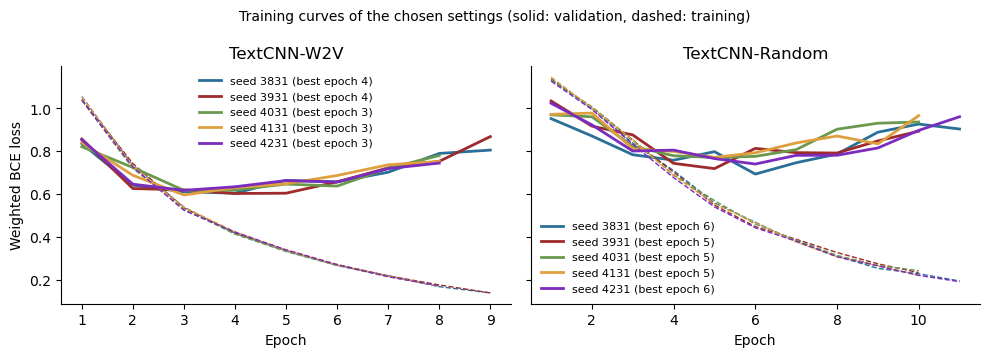

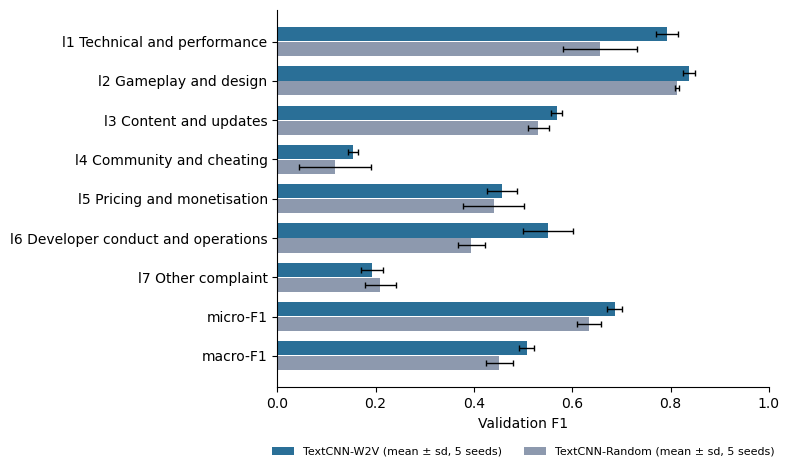

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, v in zip(axes, VARIANTS):
    for r, colour in zip([r for r in final if r["variant"] == v], ["#2a6f97", "#9e2a2b", "#6a994e", "#e09f3e", "#7b2cbf"]):
        h = pd.DataFrame(r["history"])
        ax.plot(h.epoch, h.train_loss, color=colour, lw=1, ls="--")
        ax.plot(h.epoch, h.val_loss, color=colour, lw=2, label=f"seed {r['seed']} (best epoch {r['best_epoch']})")
    ax.set_title(f"TextCNN-{'W2V' if v == 'w2v' else 'Random'}")
    ax.set_xlabel("Epoch")
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Weighted BCE loss")
fig.suptitle("Training curves of the chosen settings (solid: validation, dashed: training)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_training_curves.png", dpi=150)
plt.show()

names = [f"{c} {LABEL_NAMES[int(c[1])]}" for c in LABEL_COLS] + ["micro-F1", "macro-F1"]
keys = LABEL_COLS + ["val_micro_f1", "val_macro_f1"]
fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(names))
for i, (v, colour) in enumerate([("w2v", "#2a6f97"), ("random", "#8d99ae")]):
    part = final_df[final_df.variant == v]
    ax.barh(y + (i - 0.5) * 0.38, part[keys].mean(), xerr=part[keys].std(), height=0.36, color=colour,
            error_kw={"lw": 1, "capsize": 2}, label=f"TextCNN-{'W2V' if v == 'w2v' else 'Random'} (mean ± sd, 5 seeds)")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel("Validation F1")
ax.set_xlim(0, 1)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_w2v_vs_random.png", dpi=150)
plt.show()

#### Save configuration

In [7]:
config = {"smoke_test": SMOKE_TEST, "grid": GRID, "fixed": FIXED, "tune_seed": TUNE_SEED, "extra_seeds": EXTRA_SEEDS,
          "vocabulary_size": len(itos), "embedding_init_scale": scale, "device": str(DEVICE), "torch": torch.__version__,
          "chosen": {v: {k: (float(chosen[v][k]) if k != "n_filters" else int(chosen[v][k])) for k in ["lr", "dropout", "n_filters"]} for v in VARIANTS},
          "validation_mean": {v: {m: round(float(final_df.loc[final_df.variant == v, m].mean()), 4) for m in ["val_micro_f1", "val_macro_f1"]} for v in VARIANTS},
          "validation_std": {v: {m: round(float(final_df.loc[final_df.variant == v, m].std()), 4) for m in ["val_micro_f1", "val_macro_f1"]} for v in VARIANTS},
          "test_evaluated": False}
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(json.dumps(config["chosen"], indent=1), json.dumps(config["validation_mean"], indent=1))

{
 "w2v": {
  "lr": 0.001,
  "dropout": 0.3,
  "n_filters": 200
 },
 "random": {
  "lr": 0.002,
  "dropout": 0.5,
  "n_filters": 100
 }
} {
 "w2v": {
  "val_micro_f1": 0.686,
  "val_macro_f1": 0.5076
 },
 "random": {
  "val_micro_f1": 0.6344,
  "val_macro_f1": 0.4517
 }
}


### 3.3 BiLSTM (Word2Vec vs random initialisation)

#### Configuration

In [1]:
import copy
import json
import os
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from gensim.models import KeyedVectors
from sklearn.metrics import f1_score
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"

SMOKE_TEST = os.environ.get("A3_SMOKE_TEST") == "1"     # quick check of the code only; never used for results
OUT_DIR = A3_DIR / "outputs" / ("13_bilstm_smoke" if SMOKE_TEST else "13_bilstm")
RUN_DIR = OUT_DIR / "runs"
for d in [RUN_DIR, OUT_DIR / "figures", OUT_DIR / "models"]:
    d.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {1: "Technical and performance", 2: "Gameplay and design", 3: "Content and updates",
               4: "Community and cheating", 5: "Pricing and monetisation", 6: "Developer conduct and operations",
               7: "Other complaint"}
LABEL_COLS = [f"l{k}" for k in LABEL_NAMES]

TUNE_SEED, EXTRA_SEEDS = 3831, [3931, 4031, 4131, 4231]
STAGE1 = {"lr": [5e-4, 1e-3, 2e-3, 4e-3], "hidden": 128, "dropout": 0.5}
STAGE2 = {"hidden": [64, 128, 256], "dropout": [0.3, 0.5]}
FIXED = {"batch_size": 32, "max_epochs": 50, "patience": 5, "clip_norm": 1.0, "max_len": 512, "head": 256, "tail": 256}
VARIANTS = ["w2v", "random"]
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)
if SMOKE_TEST:
    STAGE1 = {"lr": [1e-3, 2e-3], "hidden": 64, "dropout": 0.5}
    STAGE2 = {"hidden": [64], "dropout": [0.5]}
    FIXED.update(max_epochs=1)
    EXTRA_SEEDS = [3931]

torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
DEVICE = torch.device("cpu")
print("Smoke test" if SMOKE_TEST else "Full run", "| torch", torch.__version__, "| output", OUT_DIR)

Full run | torch 2.14.0 | output /Users/kysen/MA3831/A3/outputs/13_bilstm


#### Tokens, vocabulary and embedding matrices (as in 3.2)

In [2]:
TOKEN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
def tokenize(text):
    """Same tokeniser as in 2.5 and 3.2."""
    return TOKEN.findall(re.sub(r"♥+", " swearword ", text.lower()).replace("’", "'"))

data = pd.read_csv(A3_DIR / "outputs" / "08_merge_labels" / "all_labels.csv", dtype={"appid": str, "labels": str})
wv = KeyedVectors.load(str(A3_DIR / "outputs" / "10_word2vec" / "word2vec.kv"))
PAD, UNK = 0, 1
itos = ["<pad>", "<unk>"] + list(wv.index_to_key)
stoi = {w: i for i, w in enumerate(itos)}

def encode(text):
    ids = [stoi.get(t, UNK) for t in tokenize(text)] or [UNK]
    if len(ids) > FIXED["max_len"]:
        ids = ids[:FIXED["head"]] + ids[-FIXED["tail"]:]
    return ids

split = {s: data[data.split == s].reset_index(drop=True) for s in ["train", "validation", "test"]}
ids = {s: split[s].text_clean.map(encode).tolist() for s in ["train", "validation"]}
Y = {s: split[s][LABEL_COLS].to_numpy(dtype=np.float32) for s in ["train", "validation"]}

w2v_matrix = np.zeros((len(itos), wv.vector_size), dtype=np.float32)
w2v_matrix[2:] = wv.vectors
scale = float(wv.vectors.std())
w2v_matrix[UNK] = np.random.default_rng(TUNE_SEED).normal(0, scale, wv.vector_size)

def embedding_matrix(variant, seed):
    if variant == "w2v":
        return w2v_matrix.copy()
    m = np.random.default_rng(seed).normal(0, scale, w2v_matrix.shape).astype(np.float32)
    m[PAD] = 0
    return m

POS_WEIGHT = torch.tensor((len(Y["train"]) - Y["train"].sum(0)) / Y["train"].sum(0), dtype=torch.float32)
print(f"Vocabulary {len(itos):,}; training reviews {len(ids['train']):,}, validation {len(ids['validation']):,}")

Vocabulary 15,419; training reviews 2,800, validation 600


#### Model, batching and training loop

In [3]:
class BiLSTM(nn.Module):
    def __init__(self, embeddings, hidden, dropout, n_labels=7):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embeddings), freeze=False, padding_idx=PAD)
        self.lstm = nn.LSTM(embeddings.shape[1], hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(4 * hidden, n_labels)

    def forward(self, x, lengths):
        e = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        h, _ = pad_packed_sequence(self.lstm(packed)[0], batch_first=True)      # batch x time x 2*hidden
        valid = (torch.arange(h.shape[1]).unsqueeze(0) < lengths.unsqueeze(1)).unsqueeze(2)
        mean = (h * valid).sum(1) / lengths.unsqueeze(1)
        maxed = h.masked_fill(~valid, float("-inf")).max(1).values
        return self.out(self.dropout(torch.cat([mean, maxed], dim=1)))

def batches(seqs, labels, batch_size, shuffle, generator=None):
    """Length bucketing as in 3.2."""
    if shuffle:
        order = torch.randperm(len(seqs), generator=generator).tolist()
        chunk = batch_size * 50
        order = [i for c in range(0, len(order), chunk) for i in sorted(order[c:c + chunk], key=lambda i: len(seqs[i]))]
        groups = [order[s:s + batch_size] for s in range(0, len(order), batch_size)]
        groups = [groups[j] for j in torch.randperm(len(groups), generator=generator).tolist()]
    else:
        order = sorted(range(len(seqs)), key=lambda i: len(seqs[i]))
        groups = [order[s:s + batch_size] for s in range(0, len(order), batch_size)]
    for idx in groups:
        lens = torch.tensor([len(seqs[i]) for i in idx])
        x = torch.full((len(idx), int(lens.max())), PAD, dtype=torch.long)
        for row, i in enumerate(idx):
            x[row, :len(seqs[i])] = torch.tensor(seqs[i])
        yield idx, x, lens, torch.tensor(labels[idx])

loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)

def evaluate(model, seqs, labels):
    model.eval()
    probs, total = np.zeros(labels.shape, dtype=np.float32), 0.0
    with torch.no_grad():
        for idx, x, lens, y in batches(seqs, labels, 128, shuffle=False):
            logits = model(x, lens)
            total += loss_fn(logits, y).item() * len(idx)
            probs[idx] = torch.sigmoid(logits).numpy()
    return total / len(seqs), probs

def best_shared_threshold(Yt, P):
    scores = [f1_score(Yt, (P >= t).astype(int), average="micro", zero_division=0) for t in THRESHOLD_GRID]
    i = int(np.argmax(scores))
    return float(THRESHOLD_GRID[i]), float(scores[i])

def train_one(variant, lr, hidden, dropout, seed):
    """Train one model; results are cached in RUN_DIR so an interrupted run can resume."""
    name = f"{variant}_lr{lr:g}_h{hidden}_do{dropout:g}_s{seed}"
    cache = RUN_DIR / f"{name}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = BiLSTM(embedding_matrix(variant, seed), hidden, dropout)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history, best, best_state, wait, start = [], np.inf, None, 0, time.time()
    for epoch in range(1, FIXED["max_epochs"] + 1):
        model.train()
        train_loss = 0.0
        for idx, x, lens, y in batches(ids["train"], Y["train"], FIXED["batch_size"], shuffle=True, generator=gen):
            opt.zero_grad()
            loss = loss_fn(model(x, lens), y)
            if not torch.isfinite(loss):
                raise RuntimeError(f"{name}: non-finite training loss in epoch {epoch}")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), FIXED["clip_norm"])
            opt.step()
            train_loss += loss.item() * len(idx)
        val_loss, _ = evaluate(model, ids["validation"], Y["validation"])
        history.append({"epoch": epoch, "train_loss": train_loss / len(ids["train"]), "val_loss": val_loss})
        if val_loss < best - 1e-4:
            best, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= FIXED["patience"]:
                break
    model.load_state_dict(best_state)
    _, P = evaluate(model, ids["validation"], Y["validation"])
    t, micro = best_shared_threshold(Y["validation"], P)
    pred = (P >= t).astype(int)
    result = {"name": name, "variant": variant, "lr": lr, "hidden": hidden, "dropout": dropout, "seed": seed,
              "best_epoch": int(min(history, key=lambda h: h["val_loss"])["epoch"]), "epochs_run": len(history),
              "best_val_loss": best, "threshold": t, "val_micro_f1": micro,
              "val_macro_f1": float(f1_score(Y["validation"], pred, average="macro", zero_division=0)),
              "val_per_label_f1": f1_score(Y["validation"], pred, average=None, zero_division=0).round(4).tolist(),
              "seconds": round(time.time() - start, 1), "history": history}
    torch.save(model.state_dict(), OUT_DIR / "models" / f"{name}.pt")
    np.save(RUN_DIR / f"{name}_val_probs.npy", P)
    cache.write_text(json.dumps(result), encoding="utf-8")
    return result

def show(r):
    print(f"  {r['name']:<34} best epoch {r['best_epoch']:2d}/{r['epochs_run']:2d}  val loss {r['best_val_loss']:.4f}  "
          f"micro-F1 {r['val_micro_f1']:.4f}  macro-F1 {r['val_macro_f1']:.4f}  ({r['seconds'] / 60:.1f} min)", flush=True)

#### Stage 1: learning rate (hidden size 128, dropout 0.5, seed 3831)

In [4]:
stage1, best_lr, lr_extensions = {}, {}, {}
for v in VARIANTS:
    lrs, added = list(STAGE1["lr"]), []
    while True:
        for lr in lrs:
            if lr not in {r["lr"] for r in stage1.get(v, [])}:
                stage1.setdefault(v, []).append(train_one(v, lr, STAGE1["hidden"], STAGE1["dropout"], TUNE_SEED))
                show(stage1[v][-1])
        best = max(stage1[v], key=lambda r: r["val_micro_f1"])["lr"]
        if SMOKE_TEST or len(added) >= 2 or min(lrs) < best < max(lrs):
            break
        new = best / 2 if best == min(lrs) else best * 2
        print(f"  {v}: best learning rate {best:g} is at the edge of the range; adding {new:g}")
        lrs.append(new)
        added.append(new)
    best_lr[v], lr_extensions[v] = best, added
    print(f"{v}: best learning rate {best:g}\n")

stage1_df = pd.DataFrame([r for v in VARIANTS for r in stage1[v]])[["variant", "lr", "best_epoch", "epochs_run", "best_val_loss", "threshold", "val_micro_f1", "val_macro_f1", "seconds"]]
stage1_df.to_csv(OUT_DIR / "stage1_learning_rate.csv", index=False)
stage1_df.sort_values(["variant", "lr"]).round(4)

  w2v_lr0.0005_h128_do0.5_s3831      best epoch 13/18  val loss 0.6246  micro-F1 0.6850  macro-F1 0.5215  (10.0 min)


  w2v_lr0.001_h128_do0.5_s3831       best epoch  8/13  val loss 0.5888  micro-F1 0.7103  macro-F1 0.5394  (7.4 min)


  w2v_lr0.002_h128_do0.5_s3831       best epoch  6/11  val loss 0.5979  micro-F1 0.7006  macro-F1 0.5372  (6.3 min)


  w2v_lr0.004_h128_do0.5_s3831       best epoch  3/ 8  val loss 0.6242  micro-F1 0.6717  macro-F1 0.5142  (4.5 min)


w2v: best learning rate 0.001



  random_lr0.0005_h128_do0.5_s3831   best epoch 18/23  val loss 0.7599  micro-F1 0.5897  macro-F1 0.4436  (13.2 min)


... (5 outputs left out)

  random: best learning rate 0.008 is at the edge of the range; adding 0.016


  random_lr0.016_h128_do0.5_s3831    best epoch  3/ 8  val loss 0.7746  micro-F1 0.6245  macro-F1 0.4406  (4.7 min)


random: best learning rate 0.008



,variant,lr,best_epoch,epochs_run,best_val_loss,threshold,val_micro_f1,val_macro_f1,seconds
4,random,0.0005,18,23,0.7599,0.37,0.5897,0.4436,789.4
5,random,0.0010,10,15,0.7549,0.50,0.5943,0.4463,512.9
6,random,0.0020,6,11,0.7330,0.49,0.6012,0.4482,375.4
7,random,0.0040,5,10,0.7087,0.59,0.6345,0.4603,342.7
8,random,0.0080,3,8,0.7069,0.44,0.6362,0.4593,273.9
9,random,0.0160,3,8,0.7746,0.56,0.6245,0.4406,282.0
0,w2v,0.0005,13,18,0.6246,0.58,0.6850,0.5215,600.2
1,w2v,0.0010,8,13,0.5888,0.61,0.7103,0.5394,443.5
2,w2v,0.0020,6,11,0.5979,0.50,0.7006,0.5372,378.8
3,w2v,0.0040,3,8,0.6242,0.41,0.6717,0.5142,271.7


#### Stage 2: hidden size and dropout at the best learning rate (seed 3831)

In [5]:
stage2 = {}
for v in VARIANTS:
    for hidden in STAGE2["hidden"]:
        for dropout in STAGE2["dropout"]:
            stage2.setdefault(v, []).append(train_one(v, best_lr[v], hidden, dropout, TUNE_SEED))
            show(stage2[v][-1])
stage2_df = pd.DataFrame([r for v in VARIANTS for r in stage2[v]])[["variant", "lr", "hidden", "dropout", "best_epoch", "epochs_run", "best_val_loss", "threshold", "val_micro_f1", "val_macro_f1", "seconds"]]
stage2_df.to_csv(OUT_DIR / "stage2_size_dropout.csv", index=False)
chosen = {v: stage2_df[stage2_df.variant == v].sort_values("val_micro_f1", ascending=False).iloc[0] for v in VARIANTS}
for v in VARIANTS:
    c = chosen[v]
    edge = " (largest hidden size tried)" if c.hidden == max(STAGE2["hidden"]) else ""
    print(f"{v}: chosen lr {c.lr:g}, hidden {int(c.hidden)}{edge}, dropout {c.dropout:g}")
stage2_df.pivot_table(index=["variant", "hidden"], columns="dropout", values="val_micro_f1").round(4)

  w2v_lr0.001_h64_do0.3_s3831        best epoch  6/11  val loss 0.6387  micro-F1 0.6830  macro-F1 0.5059  (3.1 min)


  w2v_lr0.001_h64_do0.5_s3831        best epoch  6/11  val loss 0.6213  micro-F1 0.6578  macro-F1 0.4999  (3.0 min)


  w2v_lr0.001_h128_do0.3_s3831       best epoch  4/ 9  val loss 0.6177  micro-F1 0.6510  macro-F1 0.4937  (5.1 min)


  w2v_lr0.001_h128_do0.5_s3831       best epoch  8/13  val loss 0.5888  micro-F1 0.7103  macro-F1 0.5394  (7.4 min)


  w2v_lr0.001_h256_do0.3_s3831       best epoch  6/11  val loss 0.6066  micro-F1 0.6954  macro-F1 0.5235  (12.9 min)


  w2v_lr0.001_h256_do0.5_s3831       best epoch  6/11  val loss 0.5954  micro-F1 0.6756  macro-F1 0.5105  (13.0 min)


... (4 outputs left out)

  random_lr0.008_h256_do0.3_s3831    best epoch  2/ 7  val loss 0.7099  micro-F1 0.6042  macro-F1 0.4132  (8.5 min)


  random_lr0.008_h256_do0.5_s3831    best epoch  6/11  val loss 0.7547  micro-F1 0.6584  macro-F1 0.4666  (13.0 min)


w2v: chosen lr 0.001, hidden 128, dropout 0.5
random: chosen lr 0.008, hidden 256 (largest hidden size tried), dropout 0.5


dropout            0.3     0.5
variant hidden                
random  64      0.6163  0.6095
        128     0.6244  0.6362
        256     0.6042  0.6584
w2v     64      0.6830  0.6578
        128     0.6510  0.7103
        256     0.6954  0.6756

#### Chosen setting per variant, five seeds

In [6]:
final = []
for v in VARIANTS:
    c = chosen[v]
    for seed in [TUNE_SEED] + EXTRA_SEEDS:
        final.append(train_one(v, float(c.lr), int(c.hidden), float(c.dropout), seed))
        show(final[-1])

final_df = pd.DataFrame(final)
per_label = pd.DataFrame(final_df.val_per_label_f1.tolist(), columns=LABEL_COLS)
final_df = pd.concat([final_df.drop(columns=["val_per_label_f1", "history"]), per_label], axis=1)
final_df.to_csv(OUT_DIR / "final_seed_results.csv", index=False)
print("Validation results over five seeds (mean, std):")
final_df.groupby("variant")[["val_micro_f1", "val_macro_f1"] + LABEL_COLS + ["best_epoch", "threshold"]].agg(["mean", "std"]).T.round(4)

  w2v_lr0.001_h128_do0.5_s3831       best epoch  8/13  val loss 0.5888  micro-F1 0.7103  macro-F1 0.5394  (7.4 min)


  w2v_lr0.001_h128_do0.5_s3931       best epoch  6/11  val loss 0.5962  micro-F1 0.6524  macro-F1 0.4906  (6.5 min)


  w2v_lr0.001_h128_do0.5_s4031       best epoch  5/10  val loss 0.6335  micro-F1 0.6605  macro-F1 0.4915  (5.9 min)


  w2v_lr0.001_h128_do0.5_s4131       best epoch  5/10  val loss 0.6484  micro-F1 0.6522  macro-F1 0.4841  (5.9 min)


  w2v_lr0.001_h128_do0.5_s4231       best epoch  6/11  val loss 0.5878  micro-F1 0.6696  macro-F1 0.5095  (6.5 min)


  random_lr0.008_h256_do0.5_s3831    best epoch  6/11  val loss 0.7547  micro-F1 0.6584  macro-F1 0.4666  (13.0 min)


... (2 outputs left out)

  random_lr0.008_h256_do0.5_s4131    best epoch  3/ 8  val loss 0.7657  micro-F1 0.5924  macro-F1 0.4484  (9.8 min)


  random_lr0.008_h256_do0.5_s4231    best epoch  3/ 8  val loss 0.6462  micro-F1 0.6018  macro-F1 0.4657  (9.8 min)


Validation results over five seeds (mean, std):


variant            random     w2v
val_micro_f1 mean  0.6033  0.6690
             std   0.0320  0.0242
val_macro_f1 mean  0.4549  0.5030
             std   0.0102  0.0224
l1           mean  0.7161  0.7925
             std   0.0484  0.0124
l2           mean  0.8005  0.8444
             std   0.0143  0.0089
l3           mean  0.5285  0.5359
             std   0.0212  0.0335
l4           mean  0.0832  0.1186
             std   0.0352  0.0392
l5           mean  0.4535  0.4854
             std   0.0517  0.0445
l6           mean  0.4256  0.5373
             std   0.0163  0.0100
l7           mean  0.1773  0.2071
             std   0.0544  0.0367
best_epoch   mean  3.6000  6.0000
             std   1.3416  1.2247
threshold    mean  0.5180  0.5640
             std   0.1366  0.0305

Key result (validation, 5 seeds): BiLSTM-W2V micro-F1 0.669 ± 0.024, macro-F1 0.503; BiLSTM-Random 0.603 ± 0.032, 0.455.

#### Figures and configuration

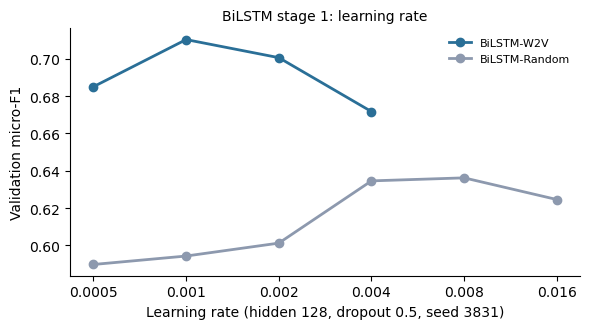

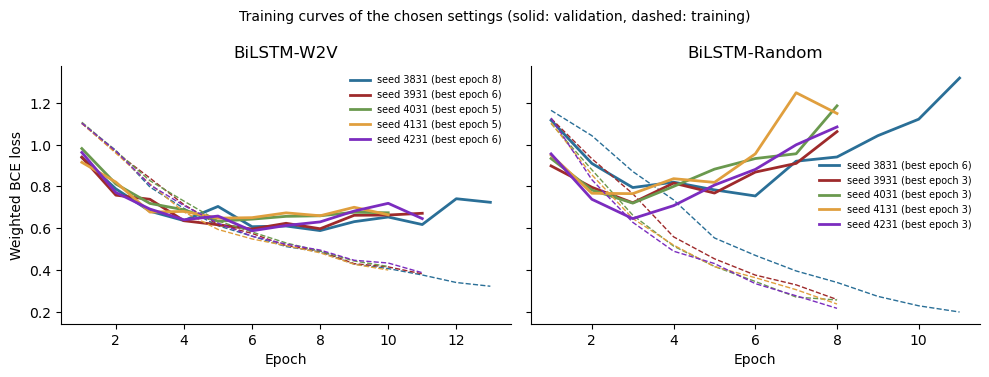

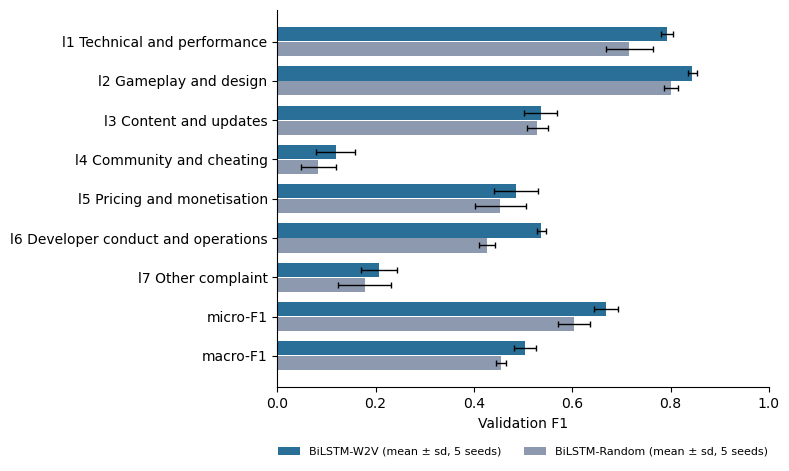

{"w2v": {"lr": 0.001, "hidden": 128, "dropout": 0.5}, "random": {"lr": 0.008, "hidden": 256, "dropout": 0.5}} {"w2v": {"val_micro_f1": 0.669, "val_macro_f1": 0.503}, "random": {"val_micro_f1": 0.6033, "val_macro_f1": 0.4549}}


In [7]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for v, colour in [("w2v", "#2a6f97"), ("random", "#8d99ae")]:
    part = stage1_df[stage1_df.variant == v].sort_values("lr")
    ax.plot(part.lr, part.val_micro_f1, marker="o", color=colour, lw=2, label=f"BiLSTM-{'W2V' if v == 'w2v' else 'Random'}")
ax.set_xscale("log", base=2)
ax.set_xticks(sorted(stage1_df.lr.unique()), [f"{x:g}" for x in sorted(stage1_df.lr.unique())])
ax.set_xlabel("Learning rate (hidden 128, dropout 0.5, seed 3831)")
ax.set_ylabel("Validation micro-F1")
ax.set_title("BiLSTM stage 1: learning rate", fontsize=10)
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_stage1_learning_rate.png", dpi=150)
plt.show()

colours = ["#2a6f97", "#9e2a2b", "#6a994e", "#e09f3e", "#7b2cbf"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, v in zip(axes, VARIANTS):
    for r, colour in zip([r for r in final if r["variant"] == v], colours):
        h = pd.DataFrame(r["history"])
        ax.plot(h.epoch, h.train_loss, color=colour, lw=1, ls="--")
        ax.plot(h.epoch, h.val_loss, color=colour, lw=2, label=f"seed {r['seed']} (best epoch {r['best_epoch']})")
    ax.set_title(f"BiLSTM-{'W2V' if v == 'w2v' else 'Random'}")
    ax.set_xlabel("Epoch")
    ax.legend(frameon=False, fontsize=7)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Weighted BCE loss")
fig.suptitle("Training curves of the chosen settings (solid: validation, dashed: training)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_training_curves.png", dpi=150)
plt.show()

names = [f"{c} {LABEL_NAMES[int(c[1])]}" for c in LABEL_COLS] + ["micro-F1", "macro-F1"]
keys = LABEL_COLS + ["val_micro_f1", "val_macro_f1"]
fig, ax = plt.subplots(figsize=(8, 4.8))
y = np.arange(len(names))
for i, (v, colour) in enumerate([("w2v", "#2a6f97"), ("random", "#8d99ae")]):
    part = final_df[final_df.variant == v]
    ax.barh(y + (i - 0.5) * 0.38, part[keys].mean(), xerr=part[keys].std(), height=0.36, color=colour,
            error_kw={"lw": 1, "capsize": 2}, label=f"BiLSTM-{'W2V' if v == 'w2v' else 'Random'} (mean ± sd, 5 seeds)")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel("Validation F1")
ax.set_xlim(0, 1)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_w2v_vs_random.png", dpi=150)
plt.show()

config = {"smoke_test": SMOKE_TEST, "stage1": STAGE1, "lr_extensions": lr_extensions, "stage2": STAGE2, "fixed": FIXED,
          "tune_seed": TUNE_SEED, "extra_seeds": EXTRA_SEEDS, "best_lr_stage1": best_lr,
          "chosen": {v: {"lr": float(chosen[v].lr), "hidden": int(chosen[v].hidden), "dropout": float(chosen[v].dropout)} for v in VARIANTS},
          "validation_mean": {v: {m: round(float(final_df.loc[final_df.variant == v, m].mean()), 4) for m in ["val_micro_f1", "val_macro_f1"]} for v in VARIANTS},
          "validation_std": {v: {m: round(float(final_df.loc[final_df.variant == v, m].std()), 4) for m in ["val_micro_f1", "val_macro_f1"]} for v in VARIANTS},
          "device": str(DEVICE), "torch": torch.__version__, "test_evaluated": False}
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(json.dumps(config["chosen"]), json.dumps(config["validation_mean"]))

### 3.4 Validation metrics: per-label AUC, loss and accuracy

#### Configuration and loading

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"
OUT = A3_DIR / "outputs"
OUT_DIR = OUT / "14_validation_metrics"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {1: "Technical and performance", 2: "Gameplay and design", 3: "Content and updates",
               4: "Community and cheating", 5: "Pricing and monetisation", 6: "Developer conduct and operations",
               7: "Other complaint"}
LABEL_COLS = [f"l{k}" for k in LABEL_NAMES]
SEEDS = [3831, 3931, 4031, 4131, 4231]

data = pd.read_csv(OUT / "08_merge_labels" / "all_labels.csv", dtype={"appid": str})
train = data[data.split == "train"]
val = data[data.split == "validation"].reset_index(drop=True)   # same row order as in 3.1-3.3
Y = val[LABEL_COLS].to_numpy(dtype=int)
POS_WEIGHT = ((len(train) - train[LABEL_COLS].sum()) / train[LABEL_COLS].sum()).to_numpy()
print(f"Validation reviews: {len(val)}; positives per label: {dict(zip(LABEL_COLS, Y.sum(0)))}")
print("Training positive-class weights:", dict(zip(LABEL_COLS, POS_WEIGHT.round(2))))

Validation reviews: 600; positives per label: {'l1': np.int64(219), 'l2': np.int64(311), 'l3': np.int64(127), 'l4': np.int64(7), 'l5': np.int64(32), 'l6': np.int64(76), 'l7': np.int64(16)}
Training positive-class weights: {'l1': np.float64(4.02), 'l2': np.float64(1.35), 'l3': np.float64(3.06), 'l4': np.float64(25.42), 'l5': np.float64(5.42), 'l6': np.float64(2.77), 'l7': np.float64(27.57)}


#### Collect the validation probabilities of every run

In [2]:
runs = []   # (model, seed, probabilities, threshold)

base = pd.read_csv(OUT / "09_tfidf_lr_baseline" / "validation_probabilities.csv")
assert base.label_id.tolist() == val.label_id.tolist(), "baseline rows are not in validation order"
base_cfg = json.loads((OUT / "09_tfidf_lr_baseline" / "config.json").read_text())
runs.append(("TF-IDF + LR", 3831, base[[f"p_{c}" for c in LABEL_COLS]].to_numpy(), base_cfg["shared_threshold"]))

def add_neural(model, nb_dir, names):
    for name in names:
        rec = json.loads((OUT / nb_dir / "runs" / f"{name}.json").read_text())
        runs.append((model, rec["seed"], np.load(OUT / nb_dir / "runs" / f"{name}_val_probs.npy"), rec["threshold"]))

for nb_dir, label in [("11_textcnn", "TextCNN"), ("13_bilstm", "BiLSTM")]:
    final = pd.read_csv(OUT / nb_dir / "final_seed_results.csv")
    for variant, model in [("w2v", f"{label}-W2V"), ("random", f"{label}-Random")]:
        names = final.loc[final.variant == variant, "name"].tolist()
        assert len(names) == 5, (nb_dir, variant, names)
        add_neural(model, nb_dir, names)

add_neural("DistilBERT", "12_distilbert", [f"distilbert_lr5e-05_s{s}" for s in (3831, 3931, 4031)])

for model, seed, P, t in runs:
    assert P.shape == Y.shape and np.isfinite(P).all() and (P >= 0).all() and (P <= 1).all(), (model, seed)
print(pd.Series([r[0] for r in runs]).value_counts().to_string())

TextCNN-W2V       5
TextCNN-Random    5
BiLSTM-W2V        5
BiLSTM-Random     5
DistilBERT        3
TF-IDF + LR       1


#### Metrics per run

In [3]:
EPS = 1e-7

def bce(P, weighted):
    P = np.clip(P, EPS, 1 - EPS)
    w = POS_WEIGHT if weighted else 1.0
    return float(np.mean(-(w * Y * np.log(P) + (1 - Y) * np.log(1 - P))))

def metrics(P, t):
    pred = (P >= t).astype(int)
    row = {"roc_auc_macro": roc_auc_score(Y, P, average="macro"),
           "roc_auc_micro": roc_auc_score(Y, P, average="micro"),
           "pr_auc_macro": average_precision_score(Y, P, average="macro"),
           "pr_auc_micro": average_precision_score(Y, P, average="micro"),
           "bce": bce(P, weighted=False),
           "bce_weighted": bce(P, weighted=True),
           "threshold": t,
           "precision_micro": precision_score(Y, pred, average="micro", zero_division=0),
           "recall_micro": recall_score(Y, pred, average="micro", zero_division=0),
           "f1_micro": f1_score(Y, pred, average="micro", zero_division=0),
           "f1_macro": f1_score(Y, pred, average="macro", zero_division=0),
           "hamming_accuracy": float((pred == Y).mean()),
           "subset_accuracy": float((pred == Y).all(1).mean())}
    for j, c in enumerate(LABEL_COLS):
        row[f"roc_{c}"] = roc_auc_score(Y[:, j], P[:, j])
        row[f"pr_{c}"] = average_precision_score(Y[:, j], P[:, j])
    return row

per_run = pd.DataFrame([{"model": m, "seed": s, **metrics(P, t)} for m, s, P, t in runs])
per_run.to_csv(OUT_DIR / "per_run_metrics.csv", index=False)

saved = {}
base_saved = base_cfg["validation"]["micro-F1"]   # saved rounded to 4 decimals
base_row = per_run[per_run.model == "TF-IDF + LR"].iloc[0]
assert abs(base_row.f1_micro - base_saved) < 5e-5 and abs(base_row.subset_accuracy - base_cfg["validation"]["exact match"]) < 5e-5
print(f"Baseline: recomputed micro-F1 {base_row.f1_micro:.4f}, saved {base_saved}")
for nb_dir, label in [("11_textcnn", "TextCNN"), ("13_bilstm", "BiLSTM")]:
    f = pd.read_csv(OUT / nb_dir / "final_seed_results.csv")
    for _, r in f.iterrows():
        saved[(f"{label}-{'W2V' if r.variant == 'w2v' else 'Random'}", r.seed)] = r.val_micro_f1
for s in (3831, 3931, 4031):
    saved[("DistilBERT", s)] = json.loads((OUT / "12_distilbert" / "runs" / f"distilbert_lr5e-05_s{s}.json").read_text())["val_micro_f1"]
diffs = [abs(r.f1_micro - saved[(r.model, r.seed)]) for r in per_run.itertuples() if r.model != "TF-IDF + LR"]
print(f"Neural runs: recomputed micro-F1 matches the saved values for {len(diffs)} runs; largest difference {max(diffs):.2e}")
assert max(diffs) < 1e-9

Baseline: recomputed micro-F1 0.6989, saved 0.6989
Neural runs: recomputed micro-F1 matches the saved values for 23 runs; largest difference 0.00e+00


#### Main result: ROC-AUC and PR-AUC per label

In [4]:
ORDER = ["TF-IDF + LR", "TextCNN-W2V", "TextCNN-Random", "BiLSTM-W2V", "BiLSTM-Random", "DistilBERT"]
SHOWN = ["TF-IDF + LR", "TextCNN-W2V", "TextCNN-Random", "BiLSTM-W2V"]
g = per_run.groupby("model")
prev = pd.Series(Y.mean(0), index=LABEL_COLS)

def mean_sd(cols):
    m, s = g[cols].mean().loc[ORDER], g[cols].std().loc[ORDER]
    m.columns = s.columns = LABEL_COLS
    text = m.round(3).map(lambda v: f"{v:.3f}") + s.map(lambda v: "" if np.isnan(v) else f" ± {v:.3f}")
    return m, s, text

tables = {}
for key, title in [("roc", "ROC-AUC per label (chance level 0.5)"), ("pr", "PR-AUC per label (chance level = prevalence)")]:
    m, s, text = mean_sd([f"{key}_{c}" for c in LABEL_COLS])
    pd.concat({"mean": m, "sd": s}, axis=1).round(4).to_csv(OUT_DIR / f"per_label_{key}_auc_all_models.csv")
    head = pd.DataFrame([prev.map(lambda v: f"{v:.3f}"), pd.Series(Y.sum(0), index=LABEL_COLS).astype(str)], index=["Prevalence", "Positives (n)"], columns=LABEL_COLS)
    shown = pd.concat([head, text.loc[SHOWN]])
    shown.columns = [f"l{k} {v}" for k, v in LABEL_NAMES.items()]
    shown.to_csv(OUT_DIR / f"per_label_{key}_auc_table.csv")
    tables[key] = m
    print(title)
    display(shown)

ROC-AUC per label (chance level 0.5)


,l1 Technical and performance,l2 Gameplay and design,l3 Content and updates,l4 Community and cheating,l5 Pricing and monetisation,l6 Developer conduct and operations,l7 Other complaint
Prevalence,0.365,0.518,0.212,0.012,0.053,0.127,0.027
Positives (n),219,311,127,7,32,76,16
TF-IDF + LR,0.898,0.919,0.838,0.850,0.898,0.824,0.788
TextCNN-W2V,0.925 ± 0.002,0.906 ± 0.003,0.818 ± 0.007,0.871 ± 0.011,0.920 ± 0.003,0.875 ± 0.002,0.871 ± 0.004
TextCNN-Random,0.841 ± 0.028,0.873 ± 0.006,0.792 ± 0.010,0.867 ± 0.022,0.863 ± 0.021,0.782 ± 0.013,0.869 ± 0.009
BiLSTM-W2V,0.914 ± 0.008,0.901 ± 0.010,0.792 ± 0.021,0.887 ± 0.045,0.924 ± 0.011,0.867 ± 0.010,0.879 ± 0.020


PR-AUC per label (chance level = prevalence)


,l1 Technical and performance,l2 Gameplay and design,l3 Content and updates,l4 Community and cheating,l5 Pricing and monetisation,l6 Developer conduct and operations,l7 Other complaint
Prevalence,0.365,0.518,0.212,0.012,0.053,0.127,0.027
Positives (n),219,311,127,7,32,76,16
TF-IDF + LR,0.853,0.920,0.649,0.106,0.526,0.466,0.071
TextCNN-W2V,0.866 ± 0.003,0.897 ± 0.004,0.550 ± 0.023,0.109 ± 0.012,0.480 ± 0.022,0.509 ± 0.006,0.154 ± 0.020
TextCNN-Random,0.761 ± 0.038,0.881 ± 0.012,0.516 ± 0.030,0.109 ± 0.033,0.370 ± 0.026,0.369 ± 0.031,0.167 ± 0.032
BiLSTM-W2V,0.857 ± 0.015,0.892 ± 0.013,0.452 ± 0.035,0.145 ± 0.072,0.527 ± 0.035,0.531 ± 0.013,0.125 ± 0.015


#### Figure: per-label AUC

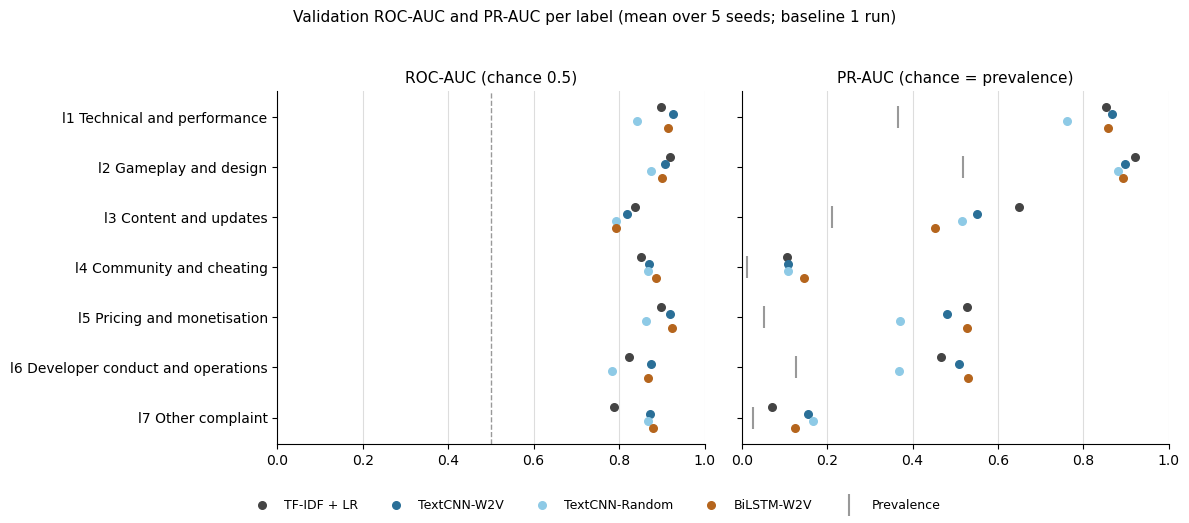

In [5]:
COLOURS = {"TF-IDF + LR": "#444444", "TextCNN-W2V": "#2a6f97", "TextCNN-Random": "#8ecae6", "BiLSTM-W2V": "#b5651d"}
names = [f"l{k} {v}" for k, v in LABEL_NAMES.items()]
y = np.arange(len(LABEL_COLS))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, key, title in [(axes[0], "roc", "ROC-AUC (chance 0.5)"), (axes[1], "pr", "PR-AUC (chance = prevalence)")]:
    for i, m in enumerate(SHOWN):
        ax.scatter(tables[key].loc[m], y + (i - 1.5) * 0.14, s=30, color=COLOURS[m], label=m, zorder=3)
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, 1)
    ax.grid(axis="x", color="#dddddd", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].axvline(0.5, color="#999999", ls="--", lw=1)
axes[1].scatter(prev, y, marker="|", s=250, color="#999999", label="Prevalence", zorder=2)
axes[0].set_yticks(y, names)
axes[0].invert_yaxis()
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.suptitle("Validation ROC-AUC and PR-AUC per label (mean over 5 seeds; baseline 1 run)", fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
fig.savefig(OUT_DIR / "figures" / "fig_per_label_auc.png", dpi=150)
plt.show()

#### Supplementary: averaged AUC, loss and accuracy

In [6]:
MAIN = ["roc_auc_macro", "roc_auc_micro", "pr_auc_macro", "pr_auc_micro", "bce", "bce_weighted",
        "f1_micro", "f1_macro", "precision_micro", "recall_micro", "hamming_accuracy", "subset_accuracy"]
mean, std, n = g[MAIN].mean().loc[ORDER], g[MAIN].std().loc[ORDER], g.size().loc[ORDER]
pd.concat({"mean": mean, "sd": std}, axis=1).assign(runs=n).round(4).to_csv(OUT_DIR / "summary_all_models.csv")
summary = mean.map(lambda v: f"{v:.3f}") + std.map(lambda v: "" if np.isnan(v) else f" ± {v:.3f}")
summary.insert(0, "runs", n.astype(str))
summary = summary.loc[SHOWN]
none = np.zeros_like(Y)
summary.loc["Reference: predict no label"] = ["-"] * 7 + ["0.000", "0.000", "-", "0.000",
                                                  f"{(none == Y).mean():.3f}", f"{(none == Y).all(1).mean():.3f}"]
summary.to_csv(OUT_DIR / "summary_table.csv")
pd.set_option("display.width", 250, "display.max_columns", 20)
summary

,runs,roc_auc_macro,roc_auc_micro,pr_auc_macro,pr_auc_micro,bce,bce_weighted,f1_micro,f1_macro,precision_micro,recall_micro,hamming_accuracy,subset_accuracy
model,,,,,,,,,,,,,
TF-IDF + LR,1,0.859,0.919,0.513,0.782,0.281,1.105,0.699,0.477,0.666,0.735,0.881,0.400
TextCNN-W2V,5,0.884 ± 0.004,0.920 ± 0.005,0.509 ± 0.007,0.735 ± 0.019,0.335 ± 0.022,0.607 ± 0.010,0.686 ± 0.016,0.508 ± 0.015,0.630 ± 0.027,0.754 ± 0.034,0.870 ± 0.009,0.385 ± 0.027
TextCNN-Random,5,0.841 ± 0.009,0.888 ± 0.011,0.453 ± 0.018,0.672 ± 0.021,0.382 ± 0.016,0.738 ± 0.034,0.634 ± 0.024,0.452 ± 0.027,0.595 ± 0.032,0.682 ± 0.040,0.853 ± 0.012,0.310 ± 0.041
BiLSTM-W2V,5,0.881 ± 0.010,0.908 ± 0.011,0.504 ± 0.022,0.682 ± 0.041,0.373 ± 0.023,0.611 ± 0.028,0.669 ± 0.024,0.503 ± 0.022,0.589 ± 0.034,0.774 ± 0.011,0.856 ± 0.014,0.351 ± 0.040
Reference: predict no label,-,-,-,-,-,-,-,0.000,0.000,-,0.000,0.812,0.138


#### Save the configuration

In [7]:
config = {"split": "validation", "n_reviews": int(len(val)),
          "runs": {m: [int(s) for s in per_run.loc[per_run.model == m, "seed"]] for m in ORDER},
          "distilbert_note": "lr 5e-5; seeds 4131 and 4231 not available (non-finite training loss on MPS; not rerun by decision)",
          "pos_weight": dict(zip(LABEL_COLS, POS_WEIGHT.round(4).tolist())),
          "bce_clip": EPS}
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)

Saved to /Users/kysen/MA3831/A3/outputs/14_validation_metrics


### 3.5 Reload check before the test

#### Configuration and data

In [1]:
import json
import re
from pathlib import Path

import torch                   # import torch before nltk: the other order crashes torch layer creation on this Mac (segmentation fault)
import torch.nn as nn
import torch.nn.functional as F
import joblib
import nltk
import numpy as np
import pandas as pd
from gensim.models import KeyedVectors
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import f1_score
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"
OUT = A3_DIR / "outputs"
OUT_DIR = OUT / "15_reload_check"
OUT_DIR.mkdir(parents=True, exist_ok=True)

LABEL_COLS = [f"l{k}" for k in range(1, 8)]
TOL = 1e-6                     # largest allowed probability difference
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)

data = pd.read_csv(OUT / "08_merge_labels" / "all_labels.csv", dtype={"appid": str, "labels": str})
val = data[data.split == "validation"].reset_index(drop=True)      # same order as in 3.1-3.3
Y = val[LABEL_COLS].to_numpy(dtype=np.float32)
print(f"Validation reviews: {len(val)}; torch {torch.__version__}")
checks = []

Validation reviews: 600; torch 2.14.0


#### TF-IDF + LR baseline

In [2]:
KEEP = {"no", "not", "nor", "never", "nothing", "none", "nobody", "nowhere", "cannot", "without", "but",
        "against", "less", "least", "too", "very", "few", "more", "most", "only", "again", "off", "down", "up"}
STOP_WORDS = frozenset(ENGLISH_STOP_WORDS - KEEP)
TOKEN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
POS_MAP = {"J": "a", "V": "v", "N": "n", "R": "r"}
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r"♥+", " swearword ", text.lower())
    tokens = TOKEN.findall(text.replace("’", "'"))
    lemmas = [lemmatizer.lemmatize(tok, POS_MAP.get(tag[0], "n")) for tok, tag in nltk.pos_tag(tokens)]
    return [w for w in lemmas if w not in STOP_WORDS and len(w) > 1]

base_dir = OUT / "09_tfidf_lr_baseline"
saved_prep = pd.read_csv(base_dir / "preprocessed_text.csv", keep_default_na=False).set_index("label_id")
prep = val.text_clean.map(preprocess).str.join(" ")
same_text = (prep.values == saved_prep.loc[val.label_id, "text_prep"].values)
print(f"Re-preprocessed validation text identical to the saved text: {same_text.sum()} / {len(val)}")

bundle = joblib.load(base_dir / "tfidf_lr_model.joblib")
P = bundle["model"].predict_proba(bundle["vectorizer"].transform(prep))
saved = pd.read_csv(base_dir / "validation_probabilities.csv")
assert saved.label_id.tolist() == val.label_id.tolist()
saved_P = saved[[f"p_{c}" for c in LABEL_COLS]].to_numpy()
micro = f1_score(Y, (P >= bundle["threshold"]).astype(int), average="micro", zero_division=0)
saved_micro = json.loads((base_dir / "config.json").read_text())["validation"]["micro-F1"]
checks.append({"model": "TF-IDF + LR", "run": f"C={bundle['C']:g}", "same_input": bool(same_text.all()),
               "max_abs_prob_diff": float(np.abs(P - saved_P).max()), "threshold": bundle["threshold"],
               "micro_f1_now": micro, "micro_f1_saved": saved_micro, "micro_f1_tolerance": 5e-5})   # saved rounded to 4 decimals
print(checks[-1])

Re-preprocessed validation text identical to the saved text: 600 / 600
{'model': 'TF-IDF + LR', 'run': 'C=100', 'same_input': True, 'max_abs_prob_diff': 1.1102230246251565e-16, 'threshold': 0.37, 'micro_f1_now': 0.6988533494266748, 'micro_f1_saved': 0.6989, 'micro_f1_tolerance': 5e-05}


#### Neural models: tokens, vocabulary and model classes

In [3]:
def tokenize(text):
    return TOKEN.findall(re.sub(r"♥+", " swearword ", text.lower()).replace("’", "'"))

wv = KeyedVectors.load(str(OUT / "10_word2vec" / "word2vec.kv"))
PAD, UNK = 0, 1
itos = ["<pad>", "<unk>"] + list(wv.index_to_key)
stoi = {w: i for i, w in enumerate(itos)}
MAX_LEN, HEAD, TAIL = 512, 256, 256

def encode(text):
    ids = [stoi.get(t, UNK) for t in tokenize(text)] or [UNK]
    if len(ids) > MAX_LEN:
        ids = ids[:HEAD] + ids[-TAIL:]
    return ids

val_ids = val.text_clean.map(encode).tolist()
placeholder = np.zeros((len(itos), wv.vector_size), dtype=np.float32)
print(f"Vocabulary {len(itos):,}; <unk> share of validation tokens {np.mean([i == UNK for x in val_ids for i in x]):.2%}")

class TextCNN(nn.Module):
    def __init__(self, embeddings, n_filters, kernel_sizes, dropout, n_labels=7):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embeddings), freeze=False, padding_idx=PAD)
        self.convs = nn.ModuleList(nn.Conv1d(embeddings.shape[1], n_filters, k) for k in kernel_sizes)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(n_filters * len(kernel_sizes), n_labels)

    def forward(self, x, lengths):
        e = self.embedding(x).transpose(1, 2)
        pooled = []
        for conv in self.convs:
            h = F.relu(conv(e))
            k = conv.kernel_size[0]
            pos = torch.arange(h.shape[2]).unsqueeze(0)
            valid = (pos + k <= lengths.unsqueeze(1)) | (pos == 0)
            h = h.masked_fill(~valid.unsqueeze(1), float("-inf"))
            pooled.append(h.max(dim=2).values)
        return self.out(self.dropout(torch.cat(pooled, dim=1)))

class BiLSTM(nn.Module):
    def __init__(self, embeddings, hidden, dropout, n_labels=7):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embeddings), freeze=False, padding_idx=PAD)
        self.lstm = nn.LSTM(embeddings.shape[1], hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(4 * hidden, n_labels)

    def forward(self, x, lengths):
        e = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        h, _ = pad_packed_sequence(self.lstm(packed)[0], batch_first=True)
        valid = (torch.arange(h.shape[1]).unsqueeze(0) < lengths.unsqueeze(1)).unsqueeze(2)
        mean = (h * valid).sum(1) / lengths.unsqueeze(1)
        maxed = h.masked_fill(~valid, float("-inf")).max(1).values
        return self.out(self.dropout(torch.cat([mean, maxed], dim=1)))

def predict(model, seqs, min_len=1, batch_size=128):
    """Probabilities in the original row order; batches of similar length as in training (padding is masked)."""
    model.eval()
    order = sorted(range(len(seqs)), key=lambda i: len(seqs[i]))
    probs = np.zeros((len(seqs), 7), dtype=np.float32)
    with torch.no_grad():
        for s in range(0, len(order), batch_size):
            idx = order[s:s + batch_size]
            lens = torch.tensor([len(seqs[i]) for i in idx])
            x = torch.full((len(idx), max(int(lens.max()), min_len)), PAD, dtype=torch.long)
            for row, i in enumerate(idx):
                x[row, :len(seqs[i])] = torch.tensor(seqs[i])
            probs[idx] = torch.sigmoid(model(x, lens)).numpy()
    return probs

Vocabulary 15,419; <unk> share of validation tokens 1.83%


#### Load every final neural model and compare

In [4]:
def check_neural(model_name, nb_dir, row, model):
    name = row["name"]
    model.load_state_dict(torch.load(OUT / nb_dir / "models" / f"{name}.pt", map_location="cpu"))
    P = predict(model, val_ids, min_len=5 if isinstance(model, TextCNN) else 1)
    saved_P = np.load(OUT / nb_dir / "runs" / f"{name}_val_probs.npy")
    micro = f1_score(Y, (P >= row["threshold"]).astype(int), average="micro", zero_division=0)
    checks.append({"model": model_name, "run": name, "same_input": True,
                   "max_abs_prob_diff": float(np.abs(P - saved_P).max()), "threshold": row["threshold"],
                   "micro_f1_now": micro, "micro_f1_saved": row["val_micro_f1"], "micro_f1_tolerance": 1e-9})

cnn = pd.read_csv(OUT / "11_textcnn" / "final_seed_results.csv")
for _, r in cnn.iterrows():
    m = TextCNN(placeholder, int(r.n_filters), [3, 4, 5], float(r.dropout))
    check_neural(f"TextCNN-{'W2V' if r.variant == 'w2v' else 'Random'}", "11_textcnn", r, m)

lstm = pd.read_csv(OUT / "13_bilstm" / "final_seed_results.csv")
for _, r in lstm.iterrows():
    m = BiLSTM(placeholder, int(r.hidden), float(r.dropout))
    check_neural(f"BiLSTM-{'W2V' if r.variant == 'w2v' else 'Random'}", "13_bilstm", r, m)
print(f"Checked {len(cnn) + len(lstm)} neural runs")

Checked 20 neural runs


#### Result

In [5]:
res = pd.DataFrame(checks)
res["micro_f1_diff"] = (res.micro_f1_now - res.micro_f1_saved).abs()
res["passed"] = res.same_input & (res.max_abs_prob_diff <= TOL) & (res.micro_f1_diff <= res.micro_f1_tolerance)
res.to_csv(OUT_DIR / "reload_check.csv", index=False)
pd.set_option("display.width", 200)
display(res[["model", "run", "same_input", "max_abs_prob_diff", "threshold", "micro_f1_now", "micro_f1_saved", "passed"]])
print(f"Passed: {res.passed.sum()} / {len(res)}")
assert res.passed.all(), "a model does not reproduce its saved validation results"

config = {"checked_runs": len(res), "probability_tolerance": TOL, "device": "cpu", "torch": torch.__version__,
          "test_set_used": False, "models_for_test": sorted(res.model.unique().tolist())}
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)

,model,run,same_input,max_abs_prob_diff,threshold,micro_f1_now,micro_f1_saved,passed
0,TF-IDF + LR,C=100,True,1.110223e-16,0.37,0.698853,0.698900,True
1,TextCNN-W2V,w2v_lr0.001_do0.3_f200_s3831,True,0.000000e+00,0.54,0.707331,0.707331,True
2,TextCNN-W2V,w2v_lr0.001_do0.3_f200_s3931,True,0.000000e+00,0.51,0.690727,0.690727,True
3,TextCNN-W2V,w2v_lr0.001_do0.3_f200_s4031,True,0.000000e+00,0.47,0.670330,0.670330,True
4,TextCNN-W2V,w2v_lr0.001_do0.3_f200_s4131,True,0.000000e+00,0.62,0.690758,0.690758,True
5,TextCNN-W2V,w2v_lr0.001_do0.3_f200_s4231,True,0.000000e+00,0.66,0.670702,0.670702,True
6,TextCNN-Random,random_lr0.002_do0.5_f100_s3831,True,0.000000e+00,0.56,0.666278,0.666278,True
7,TextCNN-Random,random_lr0.002_do0.5_f100_s3931,True,0.000000e+00,0.55,0.647293,0.647293,True
8,TextCNN-Random,random_lr0.002_do0.5_f100_s4031,True,0.000000e+00,0.52,0.601367,0.601367,True
9,TextCNN-Random,random_lr0.002_do0.5_f100_s4131,True,0.000000e+00,0.53,0.626055,0.626055,True


Passed: 21 / 21
Saved to /Users/kysen/MA3831/A3/outputs/15_reload_check


Key result: all 21 final models reproduce the saved validation probabilities.

### 3.6 Test evaluation (test set used once)

#### Configuration and data

In [1]:
import json
import re
import time
from pathlib import Path

import torch                   # import torch before nltk: the other order crashes torch layer creation on this Mac
import torch.nn as nn
import torch.nn.functional as F
import joblib
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from gensim.models import KeyedVectors
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import average_precision_score, roc_auc_score
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

A3_DIR = Path.cwd().resolve().parent
assert A3_DIR.name == "A3" and (A3_DIR / "notebooks").exists(), f"Run this notebook from A3/notebooks (cwd: {Path.cwd()})"
OUT = A3_DIR / "outputs"
OUT_DIR = OUT / "16_test_evaluation"
assert not (OUT_DIR / "config.json").exists(), "The test evaluation has already been run; it is run only once."
for d in [OUT_DIR / "figures", OUT_DIR / "probabilities"]:
    d.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {1: "Technical and performance", 2: "Gameplay and design", 3: "Content and updates",
               4: "Community and cheating", 5: "Pricing and monetisation", 6: "Developer conduct and operations",
               7: "Other complaint"}
LABEL_COLS = [f"l{k}" for k in LABEL_NAMES]
MODELS = ["TF-IDF + LR", "TextCNN-W2V", "TextCNN-Random", "BiLSTM-W2V", "BiLSTM-Random"]
MAIN_MODEL = "TextCNN-W2V"
COMPARISONS = [("TextCNN-W2V", "TF-IDF + LR"), ("TextCNN-W2V", "TextCNN-Random"),
               ("BiLSTM-W2V", "BiLSTM-Random"), ("TextCNN-W2V", "BiLSTM-W2V")]
N_BOOT, BOOT_SEED = 2000, 3831
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)

data = pd.read_csv(OUT / "08_merge_labels" / "all_labels.csv", dtype={"appid": str, "labels": str})
test = data[data.split == "test"].reset_index(drop=True)
Y = test[LABEL_COLS].to_numpy(dtype=int)
assert (test.annotator == "human").all()
print(f"Test reviews: {len(test)} from {test.name.nunique()} games: {test.name.value_counts().to_dict()}")
print("Positives per label:", dict(zip(LABEL_COLS, Y.sum(0).tolist())))

Test reviews: 600 from 3 games: {'Escape from Tarkov': 200, 'Gears of War: E-Day': 200, 'Age of Wonders 4': 200}
Positives per label: {'l1': 212, 'l2': 197, 'l3': 194, 'l4': 56, 'l5': 155, 'l6': 267, 'l7': 35}


#### Predictions of the baseline

In [2]:
KEEP = {"no", "not", "nor", "never", "nothing", "none", "nobody", "nowhere", "cannot", "without", "but",
        "against", "less", "least", "too", "very", "few", "more", "most", "only", "again", "off", "down", "up"}
STOP_WORDS = frozenset(ENGLISH_STOP_WORDS - KEEP)
TOKEN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
POS_MAP = {"J": "a", "V": "v", "N": "n", "R": "r"}
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = re.sub(r"♥+", " swearword ", text.lower())
    tokens = TOKEN.findall(text.replace("’", "'"))
    lemmas = [lemmatizer.lemmatize(tok, POS_MAP.get(tag[0], "n")) for tok, tag in nltk.pos_tag(tokens)]
    return [w for w in lemmas if w not in STOP_WORDS and len(w) > 1]

base_dir = OUT / "09_tfidf_lr_baseline"
prep = test.text_clean.map(preprocess).str.join(" ")
saved_prep = pd.read_csv(base_dir / "preprocessed_text.csv", keep_default_na=False).set_index("label_id")
assert (prep.values == saved_prep.loc[test.label_id, "text_prep"].values).all()
bundle = joblib.load(base_dir / "tfidf_lr_model.joblib")
runs = [{"model": "TF-IDF + LR", "seed": None, "run": f"C={bundle['C']:g}", "threshold": bundle["threshold"],
         "P": bundle["model"].predict_proba(bundle["vectorizer"].transform(prep))}]
print(f"Baseline: C = {bundle['C']:g}, shared threshold {bundle['threshold']}")

Baseline: C = 100, shared threshold 0.37


#### Predictions of the neural models

In [3]:
def tokenize(text):
    return TOKEN.findall(re.sub(r"♥+", " swearword ", text.lower()).replace("’", "'"))

wv = KeyedVectors.load(str(OUT / "10_word2vec" / "word2vec.kv"))
PAD, UNK = 0, 1
itos = ["<pad>", "<unk>"] + list(wv.index_to_key)
stoi = {w: i for i, w in enumerate(itos)}
MAX_LEN, HEAD, TAIL = 512, 256, 256

def encode(text):
    ids = [stoi.get(t, UNK) for t in tokenize(text)] or [UNK]
    if len(ids) > MAX_LEN:
        ids = ids[:HEAD] + ids[-TAIL:]
    return ids

test_ids = test.text_clean.map(encode).tolist()
placeholder = np.zeros((len(itos), wv.vector_size), dtype=np.float32)
print(f"<unk> share of test tokens: {np.mean([i == UNK for x in test_ids for i in x]):.2%}")

class TextCNN(nn.Module):
    def __init__(self, embeddings, n_filters, kernel_sizes, dropout, n_labels=7):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embeddings), freeze=False, padding_idx=PAD)
        self.convs = nn.ModuleList(nn.Conv1d(embeddings.shape[1], n_filters, k) for k in kernel_sizes)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(n_filters * len(kernel_sizes), n_labels)

    def forward(self, x, lengths):
        e = self.embedding(x).transpose(1, 2)
        pooled = []
        for conv in self.convs:
            h = F.relu(conv(e))
            k = conv.kernel_size[0]
            pos = torch.arange(h.shape[2]).unsqueeze(0)
            valid = (pos + k <= lengths.unsqueeze(1)) | (pos == 0)
            h = h.masked_fill(~valid.unsqueeze(1), float("-inf"))
            pooled.append(h.max(dim=2).values)
        return self.out(self.dropout(torch.cat(pooled, dim=1)))

class BiLSTM(nn.Module):
    def __init__(self, embeddings, hidden, dropout, n_labels=7):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embeddings), freeze=False, padding_idx=PAD)
        self.lstm = nn.LSTM(embeddings.shape[1], hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(4 * hidden, n_labels)

    def forward(self, x, lengths):
        e = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        h, _ = pad_packed_sequence(self.lstm(packed)[0], batch_first=True)
        valid = (torch.arange(h.shape[1]).unsqueeze(0) < lengths.unsqueeze(1)).unsqueeze(2)
        mean = (h * valid).sum(1) / lengths.unsqueeze(1)
        maxed = h.masked_fill(~valid, float("-inf")).max(1).values
        return self.out(self.dropout(torch.cat([mean, maxed], dim=1)))

def predict(model, seqs, min_len=1, batch_size=128):
    model.eval()
    order = sorted(range(len(seqs)), key=lambda i: len(seqs[i]))
    probs = np.zeros((len(seqs), 7), dtype=np.float32)
    with torch.no_grad():
        for s in range(0, len(order), batch_size):
            idx = order[s:s + batch_size]
            lens = torch.tensor([len(seqs[i]) for i in idx])
            x = torch.full((len(idx), max(int(lens.max()), min_len)), PAD, dtype=torch.long)
            for row, i in enumerate(idx):
                x[row, :len(seqs[i])] = torch.tensor(seqs[i])
            probs[idx] = torch.sigmoid(model(x, lens)).numpy()
    return probs

for nb_dir, label in [("11_textcnn", "TextCNN"), ("13_bilstm", "BiLSTM")]:
    for _, r in pd.read_csv(OUT / nb_dir / "final_seed_results.csv").iterrows():
        if label == "TextCNN":
            model, min_len = TextCNN(placeholder, int(r.n_filters), [3, 4, 5], float(r.dropout)), 5
        else:
            model, min_len = BiLSTM(placeholder, int(r.hidden), float(r.dropout)), 1
        model.load_state_dict(torch.load(OUT / nb_dir / "models" / f"{r['name']}.pt", map_location="cpu"))
        runs.append({"model": f"{label}-{'W2V' if r.variant == 'w2v' else 'Random'}", "seed": int(r.seed),
                     "run": r["name"], "threshold": float(r.threshold), "P": predict(model, test_ids, min_len)})

for r in runs:
    assert r["P"].shape == Y.shape and np.isfinite(r["P"]).all()
    name = r["run"].replace("=", "")
    pd.DataFrame(r["P"], columns=[f"p_{c}" for c in LABEL_COLS]).assign(label_id=test.label_id).to_csv(
        OUT_DIR / "probabilities" / f"{name}.csv", index=False)
print(pd.Series([r["model"] for r in runs]).value_counts().loc[MODELS].to_string())

<unk> share of test tokens: 2.59%


TF-IDF + LR       1
TextCNN-W2V       5
TextCNN-Random    5
BiLSTM-W2V        5
BiLSTM-Random     5


#### Metrics per run

In [4]:
def counts(pred, Yt):
    tp = (pred & Yt).sum(0)
    return tp, (pred & (1 - Yt)).sum(0), ((1 - pred) & Yt).sum(0)

def f1_from_counts(tp, fp, fn):
    """Returns micro-F1, macro-F1 and per-label F1."""
    denom = 2 * tp + fp + fn
    per = np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)
    micro = 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)
    return micro, per.mean(), per

rows = []
for r in runs:
    r["pred"] = (r["P"] >= r["threshold"]).astype(int)
    tp, fp, fn = counts(r["pred"], Y)
    micro, macro, per = f1_from_counts(tp, fp, fn)
    row = {"model": r["model"], "seed": r["seed"], "run": r["run"], "threshold": r["threshold"],
           "micro_f1": micro, "macro_f1": macro,
           "micro_precision": tp.sum() / max(tp.sum() + fp.sum(), 1), "micro_recall": tp.sum() / max(tp.sum() + fn.sum(), 1)}
    for j, c in enumerate(LABEL_COLS):
        row[f"f1_{c}"] = per[j]
        row[f"roc_{c}"] = roc_auc_score(Y[:, j], r["P"][:, j])
        row[f"pr_{c}"] = average_precision_score(Y[:, j], r["P"][:, j])
    for game, idx in test.groupby("name").groups.items():
        row[f"micro_f1 | {game}"] = f1_from_counts(*counts(r["pred"][idx], Y[idx]))[0]
    rows.append(row)
per_run = pd.DataFrame(rows)
per_run.to_csv(OUT_DIR / "per_run_metrics.csv", index=False)

g = per_run.groupby("model", sort=False)
def mean_sd(cols, names=None):
    m, s = g[cols].mean().loc[MODELS], g[cols].std().loc[MODELS]
    text = m.map(lambda v: f"{v:.3f}") + s.map(lambda v: "" if np.isnan(v) else f" ± {v:.3f}")
    if names:
        m.columns = s.columns = text.columns = names
    return m, s, text

#### Main results

In [5]:
pd.set_option("display.width", 250, "display.max_columns", 20)
m_overall, s_overall, overall = mean_sd(["micro_f1", "macro_f1"], ["micro-F1", "macro-F1"])
overall.insert(0, "runs", g.size().loc[MODELS].astype(str))
overall.to_csv(OUT_DIR / "table_overall_f1.csv")
print("Overall F1 (test set)")
display(overall)

names = [f"l{k} {v}" for k, v in LABEL_NAMES.items()]
head = pd.DataFrame([pd.Series(Y.mean(0), index=names).map(lambda v: f"{v:.3f}"), pd.Series(Y.sum(0), index=names).astype(str)],
                    index=["Prevalence", "Positives (n)"])
per_label = {}
for key, title in [("roc", "ROC-AUC per label (chance level 0.5)"), ("f1", "F1 per label"),
                   ("pr", "PR-AUC per label (chance level = prevalence; appendix)")]:
    m, s, text = mean_sd([f"{key}_{c}" for c in LABEL_COLS], names)
    per_label[key] = m
    table = pd.concat([head, text])
    table.to_csv(OUT_DIR / f"table_per_label_{key}.csv")
    pd.concat({"mean": m, "sd": s}, axis=1).round(4).to_csv(OUT_DIR / f"per_label_{key}_mean_sd.csv")
    print(title)
    display(table)

Overall F1 (test set)


,runs,micro-F1,macro-F1
model,,,
TF-IDF + LR,1,0.688,0.588
TextCNN-W2V,5,0.680 ± 0.019,0.643 ± 0.014
TextCNN-Random,5,0.616 ± 0.007,0.572 ± 0.013
BiLSTM-W2V,5,0.667 ± 0.009,0.628 ± 0.015
BiLSTM-Random,5,0.623 ± 0.020,0.585 ± 0.020


ROC-AUC per label (chance level 0.5)


,l1 Technical and performance,l2 Gameplay and design,l3 Content and updates,l4 Community and cheating,l5 Pricing and monetisation,l6 Developer conduct and operations,l7 Other complaint
Prevalence,0.353,0.328,0.323,0.093,0.258,0.445,0.058
Positives (n),212,197,194,56,155,267,35
TF-IDF + LR,0.878,0.907,0.847,0.889,0.899,0.846,0.861
TextCNN-W2V,0.912 ± 0.002,0.903 ± 0.006,0.806 ± 0.016,0.876 ± 0.005,0.927 ± 0.003,0.835 ± 0.004,0.914 ± 0.003
TextCNN-Random,0.854 ± 0.011,0.857 ± 0.007,0.763 ± 0.013,0.825 ± 0.034,0.851 ± 0.013,0.756 ± 0.012,0.894 ± 0.007
BiLSTM-W2V,0.894 ± 0.012,0.893 ± 0.007,0.768 ± 0.027,0.802 ± 0.017,0.917 ± 0.009,0.820 ± 0.009,0.922 ± 0.005
BiLSTM-Random,0.871 ± 0.007,0.882 ± 0.012,0.764 ± 0.018,0.852 ± 0.037,0.875 ± 0.017,0.782 ± 0.025,0.881 ± 0.019


F1 per label


,l1 Technical and performance,l2 Gameplay and design,l3 Content and updates,l4 Community and cheating,l5 Pricing and monetisation,l6 Developer conduct and operations,l7 Other complaint
Prevalence,0.353,0.328,0.323,0.093,0.258,0.445,0.058
Positives (n),212,197,194,56,155,267,35
TF-IDF + LR,0.712,0.765,0.663,0.475,0.723,0.682,0.095
TextCNN-W2V,0.776 ± 0.031,0.749 ± 0.022,0.608 ± 0.031,0.515 ± 0.030,0.768 ± 0.012,0.624 ± 0.063,0.460 ± 0.026
TextCNN-Random,0.695 ± 0.032,0.688 ± 0.012,0.555 ± 0.033,0.444 ± 0.083,0.649 ± 0.025,0.563 ± 0.057,0.413 ± 0.020
BiLSTM-W2V,0.745 ± 0.021,0.756 ± 0.012,0.561 ± 0.055,0.422 ± 0.057,0.772 ± 0.024,0.668 ± 0.032,0.471 ± 0.026
BiLSTM-Random,0.741 ± 0.013,0.716 ± 0.036,0.536 ± 0.045,0.499 ± 0.028,0.691 ± 0.039,0.602 ± 0.111,0.313 ± 0.042


PR-AUC per label (chance level = prevalence; appendix)


,l1 Technical and performance,l2 Gameplay and design,l3 Content and updates,l4 Community and cheating,l5 Pricing and monetisation,l6 Developer conduct and operations,l7 Other complaint
Prevalence,0.353,0.328,0.323,0.093,0.258,0.445,0.058
Positives (n),212,197,194,56,155,267,35
TF-IDF + LR,0.798,0.833,0.737,0.608,0.834,0.840,0.246
TextCNN-W2V,0.840 ± 0.006,0.827 ± 0.013,0.634 ± 0.023,0.607 ± 0.013,0.859 ± 0.004,0.819 ± 0.004,0.433 ± 0.029
TextCNN-Random,0.779 ± 0.014,0.750 ± 0.019,0.589 ± 0.035,0.502 ± 0.058,0.752 ± 0.018,0.741 ± 0.015,0.392 ± 0.019
BiLSTM-W2V,0.792 ± 0.016,0.798 ± 0.012,0.576 ± 0.033,0.359 ± 0.073,0.859 ± 0.010,0.811 ± 0.010,0.477 ± 0.013
BiLSTM-Random,0.788 ± 0.010,0.790 ± 0.023,0.586 ± 0.015,0.577 ± 0.086,0.787 ± 0.018,0.771 ± 0.023,0.300 ± 0.048


#### Bootstrap confidence intervals and paired comparisons

In [6]:
rng = np.random.default_rng(BOOT_SEED)
boot_idx = rng.integers(0, len(test), size=(N_BOOT, len(test)))
by_model = {m: [r for r in runs if r["model"] == m] for m in MODELS}

start = time.time()
boot = {m: np.zeros((N_BOOT, 2)) for m in MODELS}         # micro, macro (mean over seeds inside each resample)
for b, idx in enumerate(boot_idx):
    Yb = Y[idx]
    for m, rs in by_model.items():
        vals = [f1_from_counts(*counts(r["pred"][idx], Yb))[:2] for r in rs]
        boot[m][b] = np.mean(vals, axis=0)
print(f"{N_BOOT} bootstrap resamples in {time.time() - start:.0f} s")

ci = pd.DataFrame({m: {f"{metric} 95% CI": f"[{np.percentile(boot[m][:, k], 2.5):.3f}, {np.percentile(boot[m][:, k], 97.5):.3f}]"
                       for k, metric in enumerate(["micro-F1", "macro-F1"])} for m in MODELS}).T
ci.insert(0, "macro-F1", m_overall["macro-F1"].map(lambda v: f"{v:.3f}"))
ci.insert(0, "micro-F1", m_overall["micro-F1"].map(lambda v: f"{v:.3f}"))
ci.to_csv(OUT_DIR / "table_bootstrap_ci.csv")
print("Seed-averaged F1 with bootstrap 95% confidence intervals")
display(ci)

comp_rows = []
for a, b in COMPARISONS:
    for k, metric in enumerate(["micro-F1", "macro-F1"]):
        d = boot[a][:, k] - boot[b][:, k]
        observed = m_overall.loc[a, metric] - m_overall.loc[b, metric]
        comp_rows.append({"comparison": f"{a} − {b}", "metric": metric, "difference": round(observed, 4),
                          "95% CI": f"[{np.percentile(d, 2.5):.3f}, {np.percentile(d, 97.5):.3f}]",
                          "share of resamples > 0": round(float((d > 0).mean()), 3)})
comparisons = pd.DataFrame(comp_rows)
comparisons.to_csv(OUT_DIR / "table_comparisons.csv", index=False)
print("Paired differences (first model minus second); an interval that excludes 0 indicates a difference beyond resampling noise")
display(comparisons)

2000 bootstrap resamples in 2 s
Seed-averaged F1 with bootstrap 95% confidence intervals


,micro-F1,macro-F1,micro-F1 95% CI,macro-F1 95% CI
TF-IDF + LR,0.688,0.588,"[0.663, 0.711]","[0.554, 0.620]"
TextCNN-W2V,0.680,0.643,"[0.657, 0.702]","[0.614, 0.669]"
TextCNN-Random,0.616,0.572,"[0.593, 0.638]","[0.540, 0.600]"
BiLSTM-W2V,0.667,0.628,"[0.646, 0.688]","[0.601, 0.653]"
BiLSTM-Random,0.623,0.585,"[0.602, 0.643]","[0.561, 0.608]"


Paired differences (first model minus second); an interval that excludes 0 indicates a difference beyond resampling noise


,comparison,metric,difference,95% CI,share of resamples > 0
0,TextCNN-W2V − TF-IDF + LR,micro-F1,-0.0072,"[-0.030, 0.015]",0.245
1,TextCNN-W2V − TF-IDF + LR,macro-F1,0.0547,"[0.019, 0.088]",0.999
2,TextCNN-W2V − TextCNN-Random,micro-F1,0.0648,"[0.049, 0.080]",1.000
3,TextCNN-W2V − TextCNN-Random,macro-F1,0.0703,"[0.052, 0.089]",1.000
4,BiLSTM-W2V − BiLSTM-Random,micro-F1,0.0445,"[0.031, 0.057]",1.000
5,BiLSTM-W2V − BiLSTM-Random,macro-F1,0.0424,"[0.028, 0.057]",1.000
6,TextCNN-W2V − BiLSTM-W2V,micro-F1,0.0130,"[0.001, 0.025]",0.982
7,TextCNN-W2V − BiLSTM-W2V,macro-F1,0.0149,"[-0.001, 0.029]",0.967


#### Results per test game

In [7]:
games = sorted(test.name.unique())
_, _, per_game = mean_sd([f"micro_f1 | {gname}" for gname in games], games)
per_game.loc["Reviews (n)"] = [str(int((test.name == gname).sum())) for gname in games]
per_game.to_csv(OUT_DIR / "table_per_game_micro_f1.csv")
print("Micro-F1 per test game")
display(per_game)

Micro-F1 per test game


,Age of Wonders 4,Escape from Tarkov,Gears of War: E-Day
model,,,
TF-IDF + LR,0.714,0.649,0.697
TextCNN-W2V,0.701 ± 0.025,0.688 ± 0.024,0.653 ± 0.018
TextCNN-Random,0.658 ± 0.025,0.596 ± 0.023,0.591 ± 0.013
BiLSTM-W2V,0.691 ± 0.016,0.668 ± 0.014,0.643 ± 0.015
BiLSTM-Random,0.650 ± 0.021,0.628 ± 0.035,0.590 ± 0.032
Reviews (n),200,200,200


#### Figures

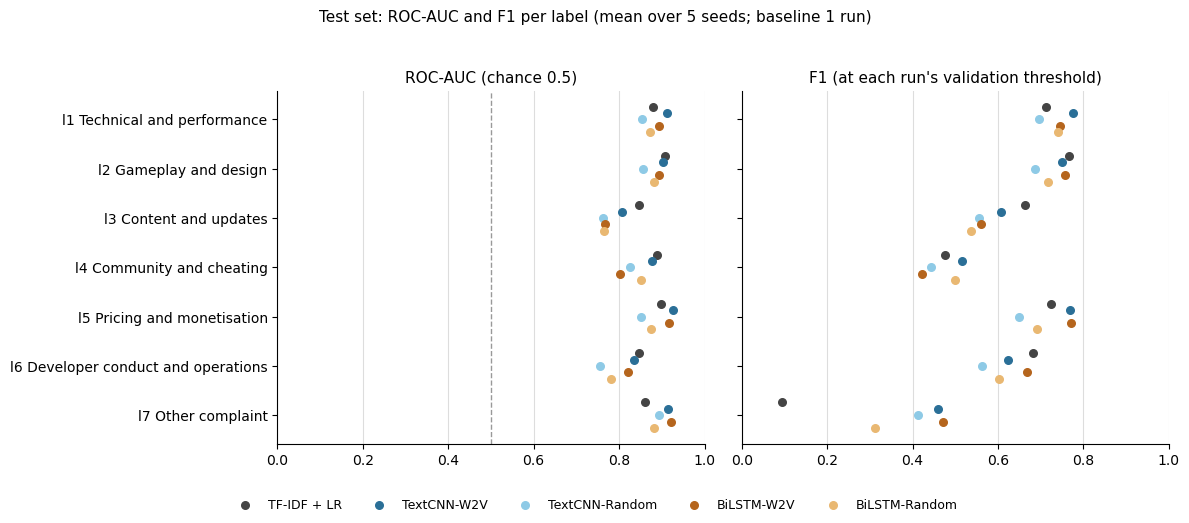

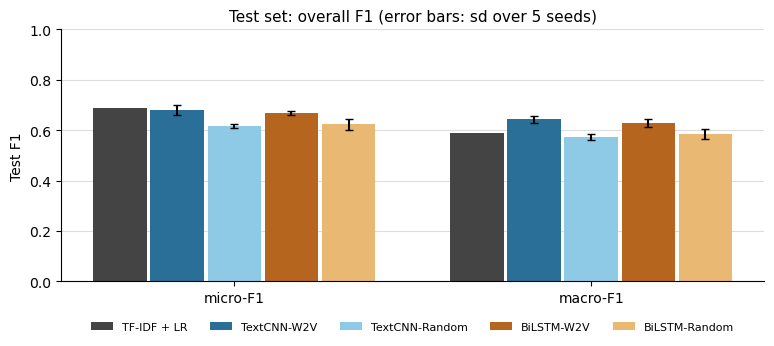

In [8]:
COLOURS = {"TF-IDF + LR": "#444444", "TextCNN-W2V": "#2a6f97", "TextCNN-Random": "#8ecae6",
           "BiLSTM-W2V": "#b5651d", "BiLSTM-Random": "#e9b872"}
y = np.arange(len(LABEL_COLS))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, key, title in [(axes[0], "roc", "ROC-AUC (chance 0.5)"), (axes[1], "f1", "F1 (at each run's validation threshold)")]:
    for i, m in enumerate(MODELS):
        ax.scatter(per_label[key].loc[m], y + (i - 2) * 0.13, s=30, color=COLOURS[m], label=m, zorder=3)
    ax.set_title(title, fontsize=11)
    ax.set_xlim(0, 1)
    ax.grid(axis="x", color="#dddddd", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].axvline(0.5, color="#999999", ls="--", lw=1)
axes[0].set_yticks(y, names)
axes[0].invert_yaxis()
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.suptitle("Test set: ROC-AUC and F1 per label (mean over 5 seeds; baseline 1 run)", fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 0.95))
fig.savefig(OUT_DIR / "figures" / "fig_test_per_label.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(2)
for i, m in enumerate(MODELS):
    ax.bar(x + (i - 2) * 0.16, m_overall.loc[m], width=0.15, color=COLOURS[m], label=m,
           yerr=None if np.isnan(s_overall.loc[m]).all() else s_overall.loc[m], capsize=3)
ax.set_xticks(x, ["micro-F1", "macro-F1"])
ax.set_ylim(0, 1)
ax.set_ylabel("Test F1")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#dddddd", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)
ax.set_title("Test set: overall F1 (error bars: sd over 5 seeds)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT_DIR / "figures" / "fig_test_overall_f1.png", dpi=150)
plt.show()

#### Record that the test set has been used

In [9]:
config = {"run_at_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "test_reviews": int(len(test)),
          "test_games": games, "models": MODELS, "main_model": MAIN_MODEL,
          "runs": {m: [r["run"] for r in by_model[m]] for m in MODELS},
          "comparisons": [f"{a} vs {b}" for a, b in COMPARISONS],
          "bootstrap": {"resamples": N_BOOT, "seed": BOOT_SEED, "unit": "review"},
          "thresholds": "each run's shared threshold chosen on the validation set",
          "not_tested": {"DistilBERT": "decided 2026-11-20, see notebook 14"}}
(OUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved to", OUT_DIR)

Saved to /Users/kysen/MA3831/A3/outputs/16_test_evaluation


#### Log loss (from the saved test probabilities)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

A3_DIR = Path.cwd().resolve().parent
TEST_DIR = A3_DIR / "outputs" / "16_test_evaluation"
LABEL_COLS = [f"l{i}" for i in range(1, 8)]
EPS = 1e-7

labels = pd.read_csv(A3_DIR / "outputs" / "08_merge_labels" / "all_labels.csv")
test = labels[labels.split == "test"].set_index("label_id")
config = pd.read_json(TEST_DIR / "config.json", typ="series")
run_file = {"TF-IDF + LR": "C100"}

rows = []
for model, runs in config["runs"].items():
    for run in runs:
        P = pd.read_csv(TEST_DIR / "probabilities" / f"{run_file.get(model, run)}.csv").set_index("label_id")
        Y = test.loc[P.index, LABEL_COLS].to_numpy()
        P = np.clip(P[[f"p_{c}" for c in LABEL_COLS]].to_numpy(), EPS, 1 - EPS)
        rows.append({"model": model, "run": run, "log_loss": float(np.mean(-(Y * np.log(P) + (1 - Y) * np.log(1 - P))))})

per_run = pd.DataFrame(rows)
table = per_run.groupby("model", sort=False).log_loss.agg(["mean", "std", "count"]).round(3)
per_run.to_csv(TEST_DIR / "table_log_loss_per_run.csv", index=False)
table.to_csv(TEST_DIR / "table_log_loss.csv")
table


,mean,std,count
model,,,
TF-IDF + LR,0.399,NaN,1
TextCNN-W2V,0.381,0.017,5
TextCNN-Random,0.432,0.010,5
BiLSTM-W2V,0.421,0.017,5
BiLSTM-Random,0.468,0.023,5


Key result (test): TextCNN-W2V ties with the baseline on micro-F1 (0.680 vs 0.688) and is better on macro-F1 (0.643 vs 0.588) and log loss (0.381 vs 0.399); Word2Vec initialisation beats random initialisation for both architectures.